# Group G+H Analysis (final plots)

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import os

# --- Group variable: change this to switch between groups ---
group_csv        = "group_gh_ssids.csv"
group_label      = "Group G+H"   # used in plot titles and filenames
group_short      = "group_gh"   # used in filenames

# --- Paths ---
elpac_clean_dir  = "../1095 Data/ELPAC/Cleaned"
enrollment_dir   = "../1095 Data/Enrollment"

os.makedirs("plots", exist_ok=True)

# --- Load Group SSIDs ---
group_ssids = set(pd.read_csv(group_csv)["SSID"])
print(f"{group_label}: {len(group_ssids):,} students")

# --- Load Cleaned Summative ELPAC files ---
summative_files = {
    1: "SummativeElpac_22_clean.csv",
    2: "SummativeElpac_23_clean.csv",
    3: "SummativeElpac_24_clean.csv",
}

summative_dfs = {}
for year_num, filename in summative_files.items():
    df = pd.read_csv(os.path.join(elpac_clean_dir, filename), low_memory=False)
    df = df.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
    df["OverallScaleScore"] = pd.to_numeric(df["OverallScaleScore"], errors="coerce")
    df["TestStartDate"] = pd.to_datetime(df["TestStartDate"], errors="coerce")
    summative_dfs[year_num] = df
    print(f"Summative {year_num}: {len(df):,} rows")

# --- Load Cleaned Initial 2022 for first test date ---
initial_22 = pd.read_csv(os.path.join(elpac_clean_dir, "InitialElpac_22_clean.csv"), low_memory=False)
initial_22 = initial_22.apply(lambda col: col.str.strip() if col.dtype == "object" else col)
initial_22["OverallPL"] = initial_22["OverallPL"].astype(str).str.strip()
initial_22["TestStartDate"] = pd.to_datetime(initial_22["TestStartDate"], errors="coerce")
print(f"Initial 2022 (clean): {len(initial_22):,} rows")

# --- Build per-student summative scores: {SSID: {1: score, 2: score, 3: score}} ---
student_scores = {}
for year_num, df in summative_dfs.items():
    df_group = df[df["SSID"].isin(group_ssids)][["SSID", "OverallScaleScore"]].dropna()
    for _, row in df_group.iterrows():
        ssid = row["SSID"]
        if ssid not in student_scores:
            student_scores[ssid] = {}
        student_scores[ssid][year_num] = row["OverallScaleScore"]

# --- Keep only students with all 3 summative scores ---
complete_students = {
    ssid: scores for ssid, scores in student_scores.items()
    if len(scores) == 3
}
print(f"Students with all 3 summative scores: {len(complete_students):,}")

# --- Global y-axis max ---
all_scores = [score for scores in complete_students.values() for score in scores.values()]
global_max = max(all_scores)
y_max = global_max * 1.10
print(f"Global max score: {global_max:.1f}, y-axis ceiling: {y_max:.1f}")

Group G+H: 12,918 students
Summative 1: 302,476 rows
Summative 2: 296,681 rows
Summative 3: 291,920 rows
Initial 2022 (clean): 62,946 rows
Students with all 3 summative scores: 12,918
Global max score: 1817.0, y-axis ceiling: 1998.7


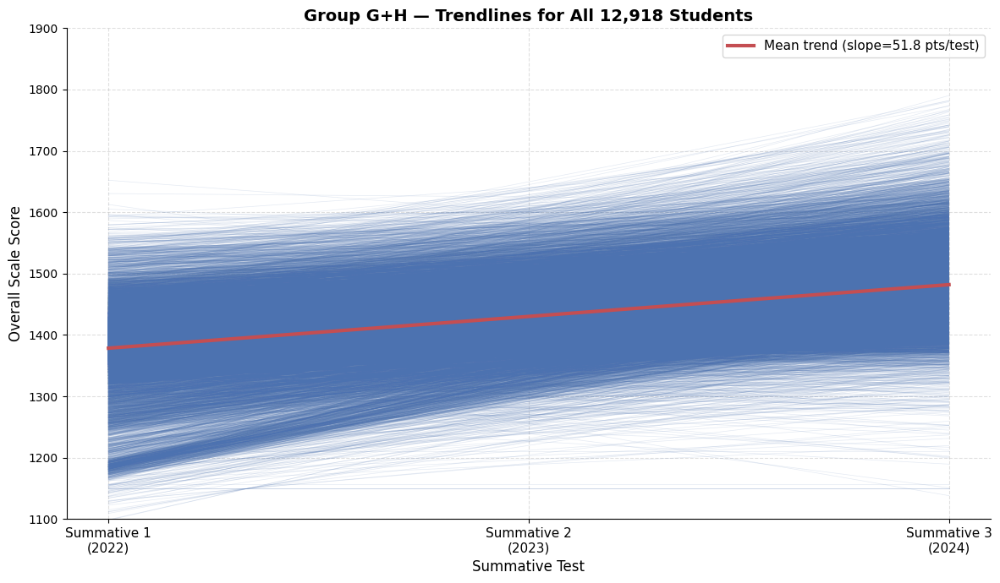

Saved: plots/group_gh_all_trendlines.png


In [8]:
# --- Plot all student trendlines on one figure ---
x = np.array([1, 2, 3])
slopes = []
intercepts = []

fig, ax = plt.subplots(figsize=(12, 7))

for ssid, scores in complete_students.items():
    y = np.array([scores[1], scores[2], scores[3]])
    slope, intercept, _, _, _ = stats.linregress(x, y)
    slopes.append(slope)
    intercepts.append(intercept)
    ax.plot(x, slope * x + intercept, color="#4C72B0", linewidth=0.5, alpha=0.15)

# --- Mean trendline ---
mean_slope     = np.mean(slopes)
mean_intercept = np.mean(intercepts)
mean_trend_y   = mean_slope * x + mean_intercept

ax.plot(x, mean_trend_y, color="#C44E52", linewidth=3, zorder=5,
        label=f"Mean trend (slope={mean_slope:.1f} pts/test)")

#ax.set_ylim(1150, y_max)
ax.set_ylim(1100, 1900)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(["Summative 1\n(2022)", "Summative 2\n(2023)", "Summative 3\n(2024)"], fontsize=11)
ax.set_xlabel("Summative Test", fontsize=12)
ax.set_ylabel("Overall Scale Score", fontsize=12)
ax.set_title(f"{group_label} — Trendlines for All {len(complete_students):,} Students",
             fontsize=14, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(True, linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(f"plots/{group_short}_all_trendlines.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: plots/{group_short}_all_trendlines.png")

Students with an initial test date: 12,918
Filtered scatter points (x > 0, y > 1000): 38,754


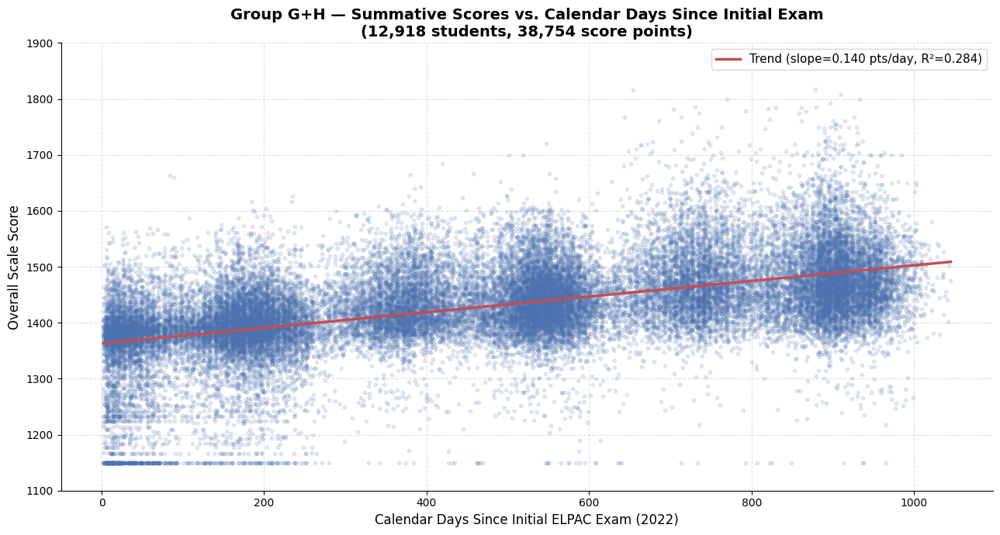

Saved: plots/group_gh_scatter_days.png


In [9]:
# --- Build first initial test date per student from Initial 2022 ---
first_initial_date = {}
for _, row in initial_22[["SSID", "TestStartDate"]].dropna().iterrows():
    ssid = row["SSID"]
    if ssid in group_ssids:
        first_initial_date[ssid] = row["TestStartDate"]

print(f"Students with an initial test date: {len(first_initial_date):,}")

# --- Build scatter dataset ---
records = []
for year_num, df in summative_dfs.items():
    df_group = df[df["SSID"].isin(complete_students.keys())].dropna(
        subset=["OverallScaleScore", "TestStartDate"]
    )
    for _, row in df_group.iterrows():
        ssid = row["SSID"]
        if ssid in first_initial_date:
            days = (row["TestStartDate"] - first_initial_date[ssid]).days
            records.append({"SSID": ssid, "days": days, "score": row["OverallScaleScore"]})

scatter_df = pd.DataFrame(records)

# --- Apply filters ---
scatter_df = scatter_df[(scatter_df["days"] > 0) & (scatter_df["score"] > 1000)]
print(f"Filtered scatter points (x > 0, y > 1000): {len(scatter_df):,}")

# --- Scatter plot ---
x = scatter_df["days"].values
y = scatter_df["score"].values

slope, intercept, r_value, _, _ = stats.linregress(x, y)
trend_x = np.linspace(x.min(), x.max(), 300)
trend_y = slope * trend_x + intercept
r_squared = r_value ** 2

fig, ax = plt.subplots(figsize=(13, 7))

ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)
ax.plot(trend_x, trend_y, color="#C44E52", linewidth=2.5, zorder=3,
        label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

#ax.set_ylim(1100, y_max)
ax.set_ylim(1100, 1900)
ax.set_xlabel("Calendar Days Since Initial ELPAC Exam (2022)", fontsize=12)
ax.set_ylabel("Overall Scale Score", fontsize=12)
ax.set_title(f"{group_label} — Summative Scores vs. Calendar Days Since Initial Exam\n"
             f"({len(complete_students):,} students, {len(scatter_df):,} score points)",
             fontsize=14, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(True, linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(f"plots/{group_short}_scatter_days.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: plots/{group_short}_scatter_days.png")

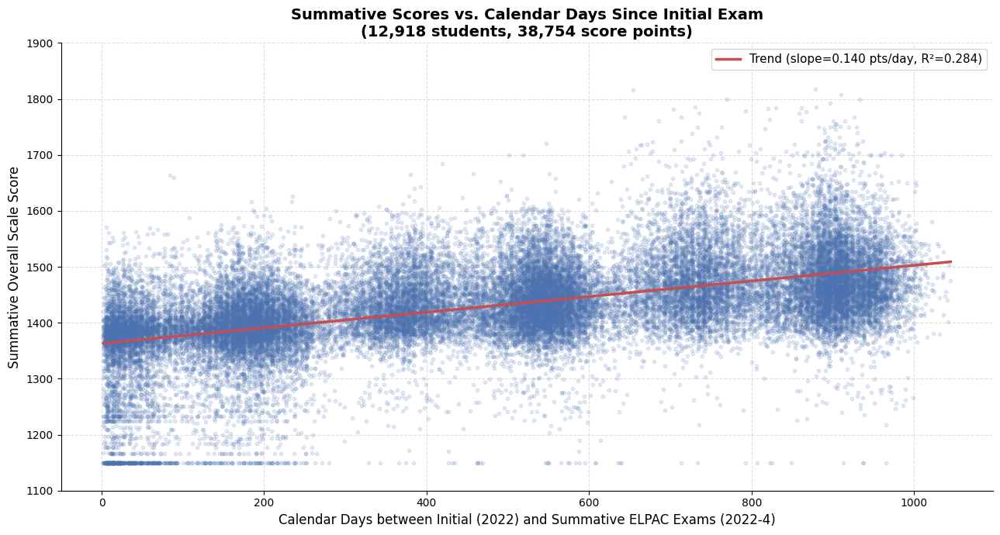

Saved: final_plots/group_gh_scatter_days.png


In [10]:
fig, ax = plt.subplots(figsize=(13, 7))

ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)
ax.plot(trend_x, trend_y, color="#C44E52", linewidth=2.5, zorder=3,
        label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

#ax.set_ylim(1100, y_max)
ax.set_ylim(1100, 1900)
ax.set_xlabel("Calendar Days between Initial (2022) and Summative ELPAC Exams (2022-4)", fontsize=12)
ax.set_ylabel("Summative Overall Scale Score", fontsize=12)
ax.set_title(f"Summative Scores vs. Calendar Days Since Initial Exam\n"
             f"({len(complete_students):,} students, {len(scatter_df):,} score points)",
             fontsize=14, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(True, linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(f"final_plots/{group_short}_scatter_days.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved: final_plots/{group_short}_scatter_days.png")

In [11]:
# --- Load Enrollment for grade level ---
enrollment_files = {
    "2021-22": "CEnrollment_21-22.csv",
    "2022-23": "CEnrollment_22-23.csv",
    "2023-24": "CEnrollment_23-24.csv",
}

enrollments = {}
for label, filename in enrollment_files.items():
    enrollments[label] = pd.read_csv(os.path.join(enrollment_dir, filename), low_memory=False)

enrollment_all = pd.concat(enrollments.values(), ignore_index=True)
enrollment_all = enrollment_all.drop_duplicates(subset="SSID", keep="first")
enrollment_group = enrollment_all[enrollment_all["SSID"].isin(group_ssids)]
print(f"{group_label} enrollment records: {len(enrollment_group):,}")

# --- ELPAC Summative Level Lookup Table ---
elpac_levels = {
    "KN": [(1, 1150, 1373), (2, 1374, 1421), (3, 1422, 1473), (4, 1474, 1700)],
    "01": [(1, 1150, 1410), (2, 1411, 1454), (3, 1455, 1506), (4, 1507, 1700)],
    "02": [(1, 1150, 1423), (2, 1424, 1470), (3, 1471, 1531), (4, 1532, 1700)],
    "03": [(1, 1150, 1447), (2, 1448, 1487), (3, 1488, 1534), (4, 1535, 1800)],
    "04": [(1, 1150, 1458), (2, 1459, 1498), (3, 1499, 1548), (4, 1549, 1800)],
    "05": [(1, 1150, 1466), (2, 1467, 1513), (3, 1514, 1559), (4, 1560, 1800)],
    "06": [(1, 1150, 1474), (2, 1475, 1516), (3, 1517, 1566), (4, 1567, 1900)],
    "07": [(1, 1150, 1480), (2, 1481, 1526), (3, 1527, 1575), (4, 1576, 1900)],
    "08": [(1, 1150, 1485), (2, 1486, 1533), (3, 1534, 1589), (4, 1590, 1900)],
    "09": [(1, 1150, 1492), (2, 1493, 1544), (3, 1545, 1605), (4, 1606, 1950)],
    "10": [(1, 1150, 1492), (2, 1493, 1544), (3, 1545, 1605), (4, 1606, 1950)],
    "11": [(1, 1150, 1499), (2, 1500, 1554), (3, 1555, 1614), (4, 1615, 1950)],
    "12": [(1, 1150, 1499), (2, 1500, 1554), (3, 1555, 1614), (4, 1615, 1950)],
}

def score_to_level(score, grade):
    grade = str(grade).strip()
    if grade not in elpac_levels or pd.isna(score):
        return None
    for level, low, high in elpac_levels[grade]:
        if low <= score <= high:
            return level
    return None

# --- Build scored dataset ---
records = []
for year_num, df in summative_dfs.items():
    df_group = df[df["SSID"].isin(complete_students.keys())].copy()
    df_group = df_group.merge(
        enrollment_group[["SSID", "GradeLevelCode"]].dropna(),
        on="SSID", how="left"
    )
    df_group = df_group.dropna(subset=["OverallScaleScore", "GradeLevelCode"])

    for _, row in df_group.iterrows():
        ssid  = row["SSID"]
        score = row["OverallScaleScore"]
        grade = row["GradeLevelCode"]
        level = score_to_level(score, grade)
        records.append({
            "SSID":           ssid,
            "TestNumber":     year_num,
            "Score":          score,
            "GradeLevelCode": grade,
            "Level":          level
        })

scored_df = pd.DataFrame(records)
print(f"Total scored records: {len(scored_df):,}")
print(f"Level distribution:\n{scored_df['Level'].value_counts().sort_index()}")

Group G+H enrollment records: 12,918
Total scored records: 38,754
Level distribution:
Level
1.0    20631
2.0     7842
3.0     6764
4.0     3507
Name: count, dtype: int64


In [12]:
# # --- Grouped bar chart: Level Distribution Across Summative Tests ---
# level_colors = {1: "#C44E52", 2: "#E07B2A", 3: "#4C9B4C", 4: "#4C72B0"}
# test_colors  = ["#4C72B0", "#4C9B4C", "#C44E52"]

# fig, ax = plt.subplots(figsize=(10, 6))

# x       = np.array([1, 2, 3, 4])
# width   = 0.25
# offsets = [-width, 0, width]

# for i, test_num in enumerate([1, 2, 3]):
#     test_data = scored_df[scored_df["TestNumber"] == test_num]["Level"].dropna()
#     counts    = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
#     bars      = ax.bar(x + offsets[i], counts.values, width=width,
#                        color=test_colors[i], edgecolor="white", linewidth=0.5,
#                        label=f"Summative {test_num} — {['2022','2023','2024'][i]} (n={len(test_data):,})")

#     for bar, count in zip(bars, counts.values):
#         if count > 0:
#             ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
#                     f"{count:,}", ha="center", va="bottom", fontsize=7, rotation=45)

# ax.set_xticks(x)
# ax.set_xticklabels(["Level 1", "Level 2", "Level 3", "Level 4"], fontsize=11)
# ax.set_xlabel("Level", fontsize=12)
# ax.set_ylabel("Number of Students", fontsize=12)
# ax.set_title(f"{group_label} — Level Distribution Across Summative Tests",
#              fontsize=14, fontweight="bold")
# ax.legend(fontsize=10)
# ax.grid(axis="y", linestyle="--", alpha=0.4)
# ax.spines[["top", "right"]].set_visible(False)

# plt.tight_layout()
# plt.savefig(f"plots/{group_short}_level_distribution_combined.png", dpi=150, bbox_inches="tight")
# plt.show()
# print(f"Saved: plots/{group_short}_level_distribution_combined.png")

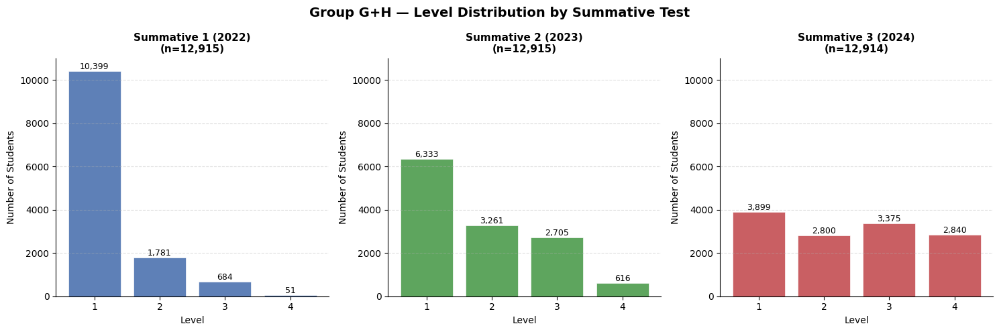

Saved: plots/group_gh_level_distribution.png


In [13]:
# --- 3 subplots: Level distribution for Summative 1, 2, 3 ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(f"{group_label} — Level Distribution by Summative Test",
             fontsize=14, fontweight="bold")

test_years  = {1: "2022", 2: "2023", 3: "2024"}
test_colors = ["#4C72B0", "#4C9B4C", "#C44E52"]

for ax, (test_num, color) in zip(axes, zip([1, 2, 3], test_colors)):
    test_data = scored_df[scored_df["TestNumber"] == test_num]["Level"].dropna()
    counts    = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
    bars      = ax.bar(counts.index, counts.values, color=color,
                       edgecolor="white", linewidth=0.5, alpha=0.9)

    for bar, count in zip(bars, counts.values):
        if count > 0:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                    f"{count:,}", ha="center", va="bottom", fontsize=9)

    ax.set_title(f"Summative {test_num} ({test_years[test_num]})\n(n={len(test_data):,})",
                 fontsize=11, fontweight="bold")
    ax.set_xlabel("Level", fontsize=10)
    ax.set_ylabel("Number of Students", fontsize=10)
    ax.set_xticks([1, 2, 3, 4])
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(0, 11000)

plt.tight_layout()
plt.savefig(f"plots/{group_short}_level_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: plots/{group_short}_level_distribution.png")

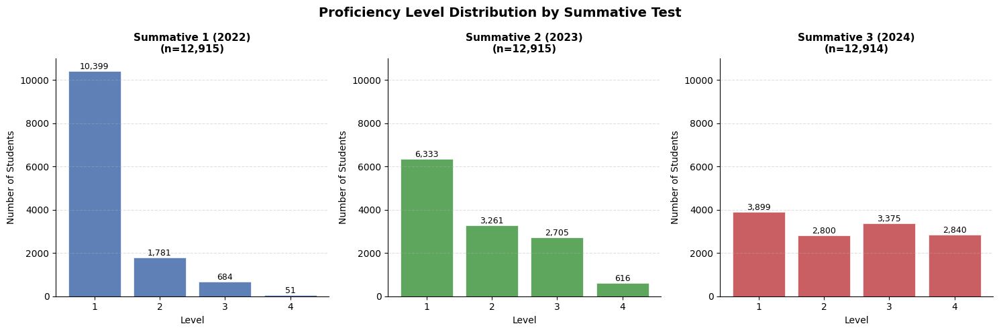

Saved: final_plots/group_gh_level_distribution.png


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(f"Proficiency Level Distribution by Summative Test",
             fontsize=14, fontweight="bold")

test_years  = {1: "2022", 2: "2023", 3: "2024"}
test_colors = ["#4C72B0", "#4C9B4C", "#C44E52"]

for ax, (test_num, color) in zip(axes, zip([1, 2, 3], test_colors)):
    test_data = scored_df[scored_df["TestNumber"] == test_num]["Level"].dropna()
    counts    = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
    bars      = ax.bar(counts.index, counts.values, color=color,
                       edgecolor="white", linewidth=0.5, alpha=0.9)

    for bar, count in zip(bars, counts.values):
        if count > 0:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                    f"{count:,}", ha="center", va="bottom", fontsize=9)

    ax.set_title(f"Summative {test_num} ({test_years[test_num]})\n(n={len(test_data):,})",
                 fontsize=11, fontweight="bold")
    ax.set_xlabel("Level", fontsize=10)
    ax.set_ylabel("Number of Students", fontsize=10)
    ax.set_xticks([1, 2, 3, 4])
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(0, 11000)

plt.tight_layout()
plt.savefig(f"final_plots/{group_short}_level_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: final_plots/{group_short}_level_distribution.png")

Students with Level 1 on Test 1: 10,399
Of those, with a Test 3 score: 10,398

Level 1 on Test 1 → Level on Test 3:
  Level 1: 3,891 students (37.4%)
  Level 2: 2,647 students (25.5%)
  Level 3: 2,520 students (24.2%)
  Level 4: 1,340 students (12.9%)


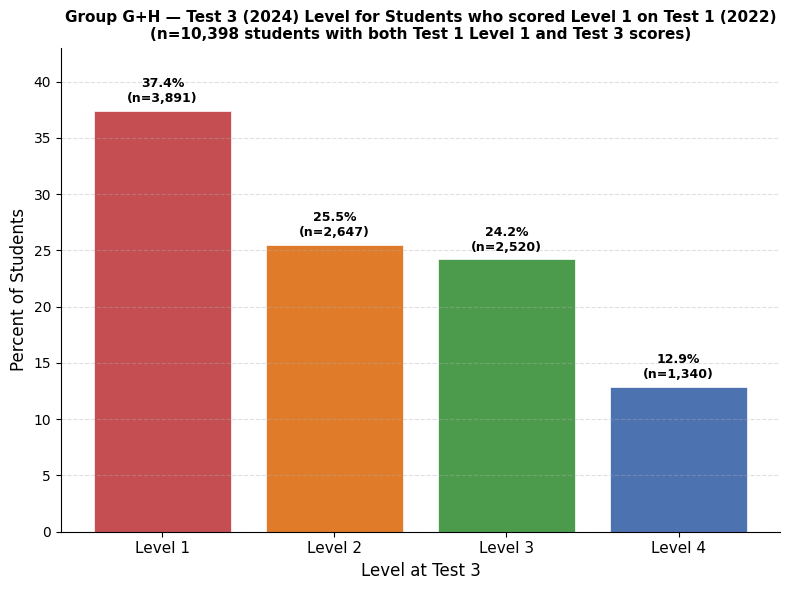

Saved: plots/group_gh_level1_test1_progression.png


In [15]:
# --- Students who scored Level 1 on Test 1 ---
level_colors = {1: "#C44E52", 2: "#E07B2A", 3: "#4C9B4C", 4: "#4C72B0"}

test1_level1 = scored_df[
    (scored_df["TestNumber"] == 1) & (scored_df["Level"] == 1)
]["SSID"].unique()

print(f"Students with Level 1 on Test 1: {len(test1_level1):,}")

# --- Find their level on Test 3 ---
test3_scores = scored_df[
    (scored_df["TestNumber"] == 3) & (scored_df["SSID"].isin(test1_level1))
][["SSID", "Level"]].dropna()

print(f"Of those, with a Test 3 score: {len(test3_scores):,}")

# --- Count and percent by Test 3 level ---
level_counts = test3_scores["Level"].value_counts().reindex([1, 2, 3, 4], fill_value=0)
level_pcts = (level_counts / len(test3_scores) * 100).round(1)

print(f"\nLevel 1 on Test 1 → Level on Test 3:")
for level in [1, 2, 3, 4]:
    print(f"  Level {level}: {level_counts[level]:,} students ({level_pcts[level]}%)")

# --- Bar chart ---
fig, ax = plt.subplots(figsize=(8, 6))

colors = [level_colors[l] for l in [1, 2, 3, 4]]
bars = ax.bar([1, 2, 3, 4], level_pcts.values, color=colors, edgecolor="white", linewidth=0.5)

for bar, count, pct in zip(bars, level_counts.values, level_pcts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f"{pct}%\n(n={count:,})", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels(["Level 1", "Level 2", "Level 3", "Level 4"], fontsize=11)
ax.set_xlabel("Level at Test 3", fontsize=12)
ax.set_ylabel("Percent of Students", fontsize=12)
ax.set_title(f"{group_label} — Test 3 (2024) Level for Students who scored Level 1 on Test 1 (2022)\n"
             f"(n={len(test3_scores):,} students with both Test 1 Level 1 and Test 3 scores)",
             fontsize=11, fontweight="bold")
ax.set_ylim(0, max(level_pcts.values) * 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(f"plots/{group_short}_level1_test1_progression.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: plots/{group_short}_level1_test1_progression.png")

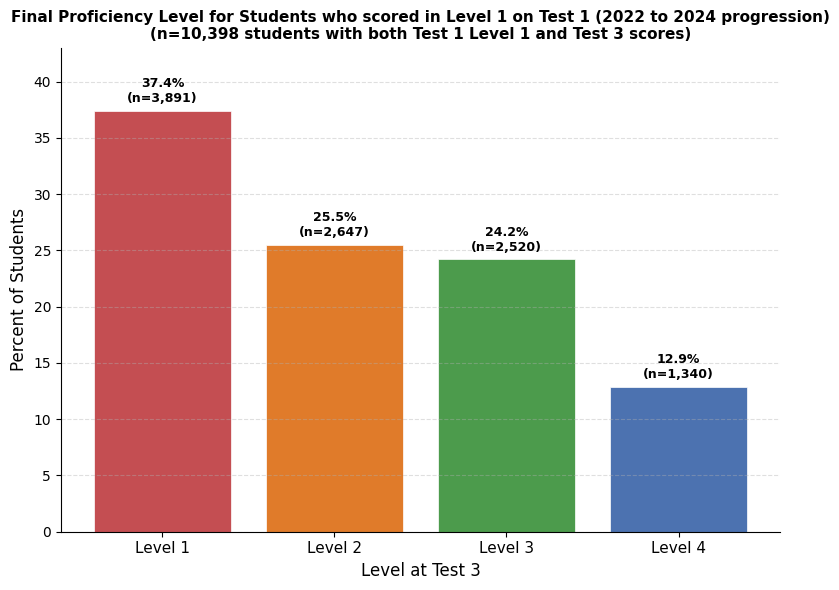

Saved: final_plots/group_gh_level1_test1_progression.png


In [16]:
fig, ax = plt.subplots(figsize=(8, 6))

colors = [level_colors[l] for l in [1, 2, 3, 4]]
bars = ax.bar([1, 2, 3, 4], level_pcts.values, color=colors, edgecolor="white", linewidth=0.5)

for bar, count, pct in zip(bars, level_counts.values, level_pcts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f"{pct}%\n(n={count:,})", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels(["Level 1", "Level 2", "Level 3", "Level 4"], fontsize=11)
ax.set_xlabel("Level at Test 3", fontsize=12)
ax.set_ylabel("Percent of Students", fontsize=12)
ax.set_title(f"Final Proficiency Level for Students who scored in Level 1 on Test 1 (2022 to 2024 progression)\n"
             f"(n={len(test3_scores):,} students with both Test 1 Level 1 and Test 3 scores)",
             fontsize=11, fontweight="bold")
ax.set_ylim(0, max(level_pcts.values) * 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(f"final_plots/{group_short}_level1_test1_progression.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: final_plots/{group_short}_level1_test1_progression.png")

# Break out by Grade level in 2022

In [17]:
# --- Load Enrollment files ---
enrollment_files = {
    "2021-22": "CEnrollment_21-22.csv",
    "2022-23": "CEnrollment_22-23.csv",
    "2023-24": "CEnrollment_23-24.csv",
}

enrollment_dfs = {}
for label, filename in enrollment_files.items():
    enrollment_dfs[label] = pd.read_csv(os.path.join(enrollment_dir, filename), low_memory=False)
    print(f"Enrollment {label}: {len(enrollment_dfs[label]):,} rows")

enrollment_all   = pd.concat(enrollment_dfs.values(), ignore_index=True)
enrollment_group = enrollment_all[enrollment_all["SSID"].isin(group_ssids)]
print(f"\n{group_label} enrollment records: {len(enrollment_group):,}")

Enrollment 2021-22: 1,519,618 rows
Enrollment 2022-23: 1,467,738 rows
Enrollment 2023-24: 1,471,765 rows

Group G+H enrollment records: 42,542


In [18]:
# --- Get grade level from 2021-22 enrollment (the year of the initial test) ---
grade_2022 = (
    enrollment_dfs["2021-22"][["SSID", "GradeLevelCode"]]
    .dropna()
    .drop_duplicates(subset="SSID", keep="first")
)

# --- Merge grade into scatter_df and scored_df ---
scatter_df = scatter_df.merge(grade_2022, on="SSID", how="left")
scored_df  = scored_df.merge(grade_2022, on="SSID", how="left")

grade_order  = ["KN", "01", "02", "03", "04", "05", "06", "07", "08", "09", "10", "11", "12"]
grade_labels = {
    "KN": "Kindergarten", "01": "Grade 1",  "02": "Grade 2",
    "03": "Grade 3",      "04": "Grade 4",  "05": "Grade 5",
    "06": "Grade 6",      "07": "Grade 7",  "08": "Grade 8",
    "09": "Grade 9",      "10": "Grade 10", "11": "Grade 11", "12": "Grade 12"
}

grades_present = [g for g in grade_order if g in scatter_df["GradeLevelCode"].values]
print(f"Grades present in {group_label}: {grades_present}")

Grades present in Group G+H: ['KN', '01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11']


In [19]:
# --- Check columns in scored_df and scatter_df ---
print("scored_df columns:", scored_df.columns.tolist())
print("scatter_df columns:", scatter_df.columns.tolist())

# --- Merge GradeLevelCode into scored_df if missing ---
if "GradeLevelCode" not in scored_df.columns:
    scored_df = scored_df.merge(grade_2022, on="SSID", how="left")
    print(f"Merged GradeLevelCode into scored_df")

# --- Merge GradeLevelCode into scatter_df if missing ---
if "GradeLevelCode" not in scatter_df.columns:
    scatter_df = scatter_df.merge(grade_2022, on="SSID", how="left")
    print(f"Merged GradeLevelCode into scatter_df")

# --- Confirm ---
grades_present = [g for g in grade_order if g in scored_df["GradeLevelCode"].values]
print(f"\nGrades present in scored_df: {grades_present}")
print(f"scored_df GradeLevelCode null count: {scored_df['GradeLevelCode'].isna().sum():,}")

scored_df columns: ['SSID', 'TestNumber', 'Score', 'GradeLevelCode_x', 'Level', 'GradeLevelCode_y']
scatter_df columns: ['SSID', 'days', 'score', 'GradeLevelCode']
Merged GradeLevelCode into scored_df

Grades present in scored_df: ['KN', '01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11']
scored_df GradeLevelCode null count: 0


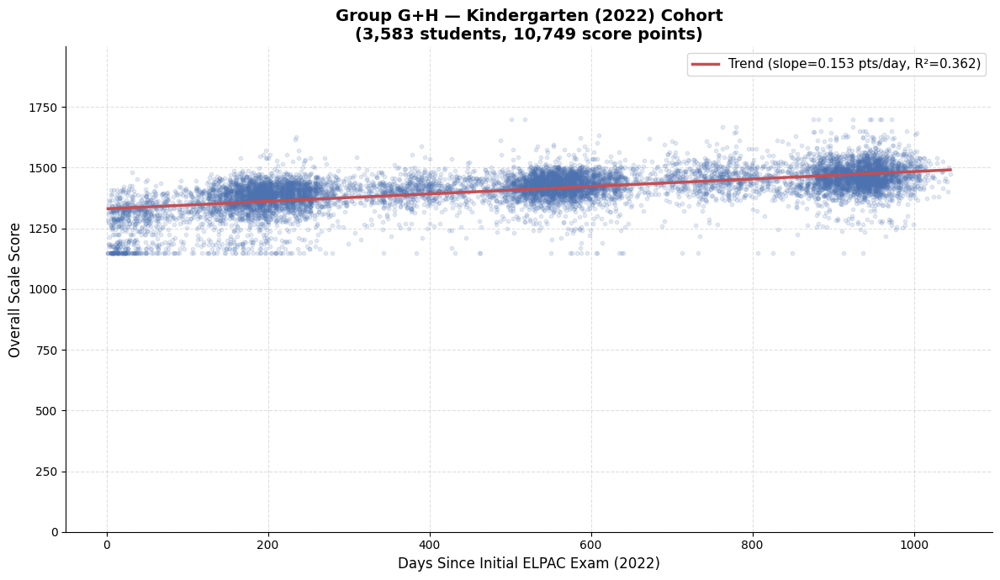

Saved: plots/group_gh_scatter_grade_KN.png


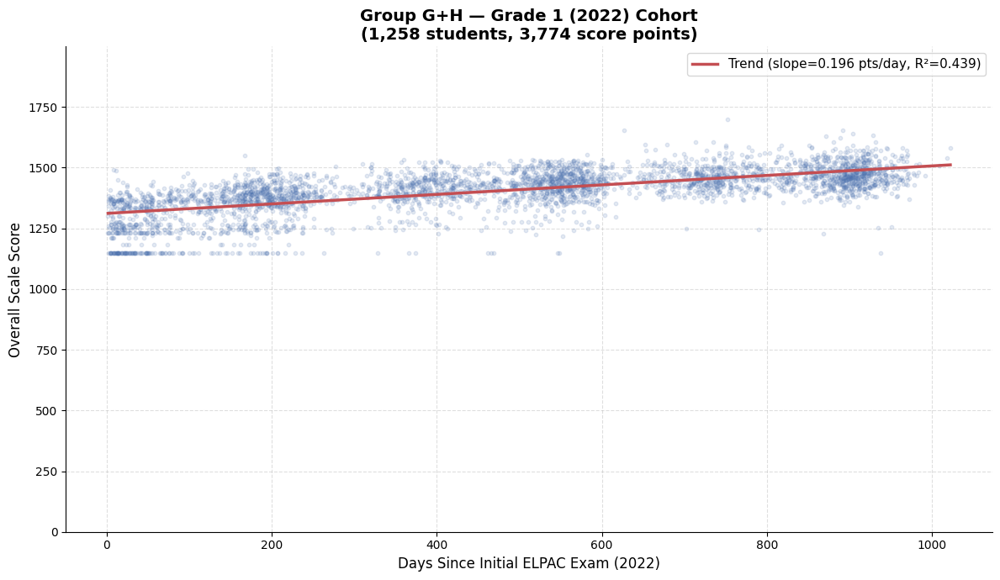

Saved: plots/group_gh_scatter_grade_01.png


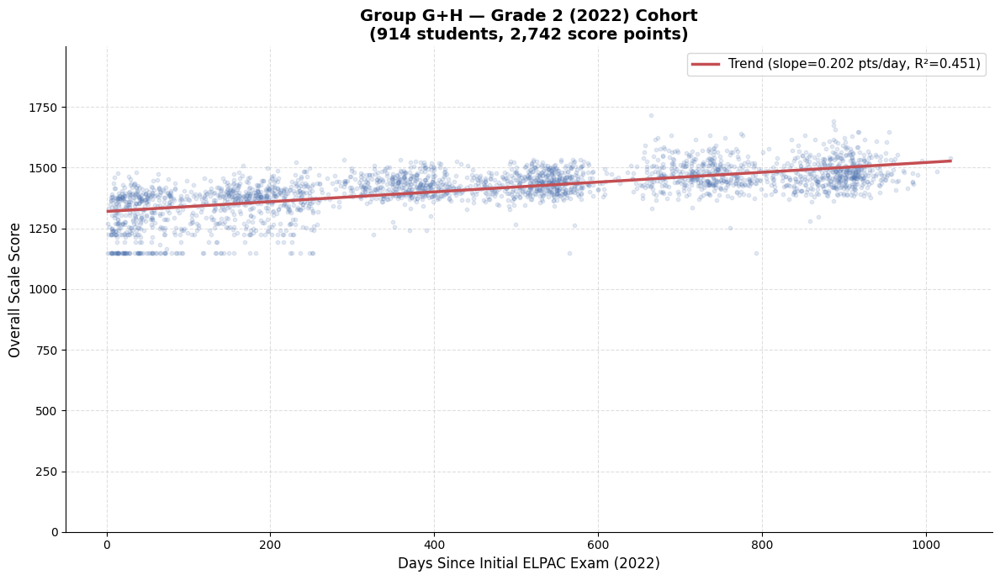

Saved: plots/group_gh_scatter_grade_02.png


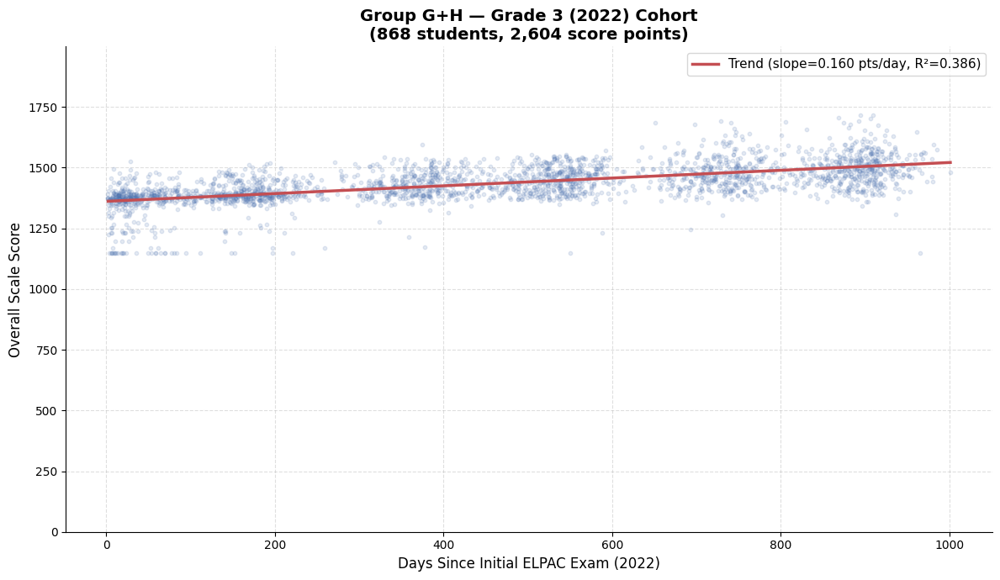

Saved: plots/group_gh_scatter_grade_03.png


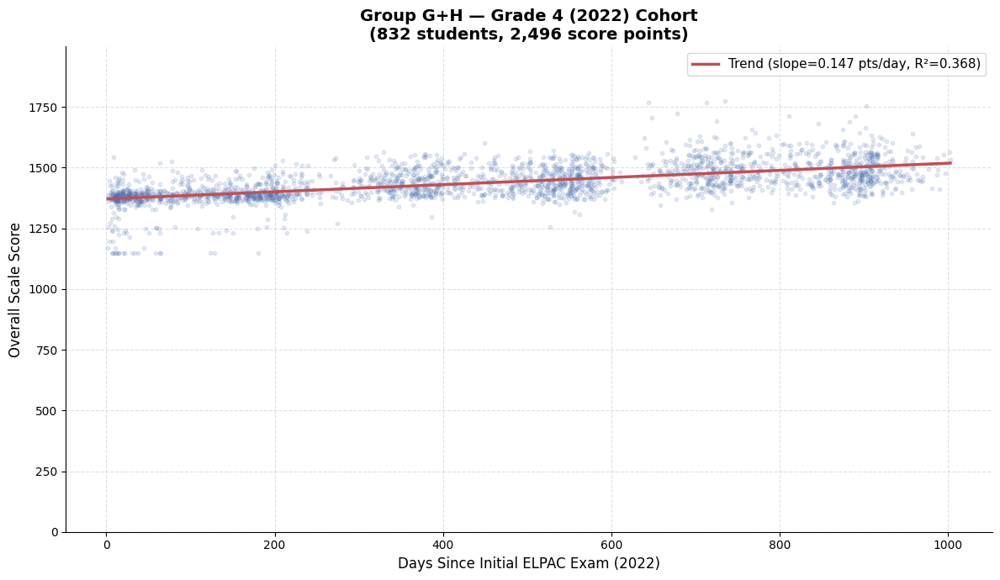

Saved: plots/group_gh_scatter_grade_04.png


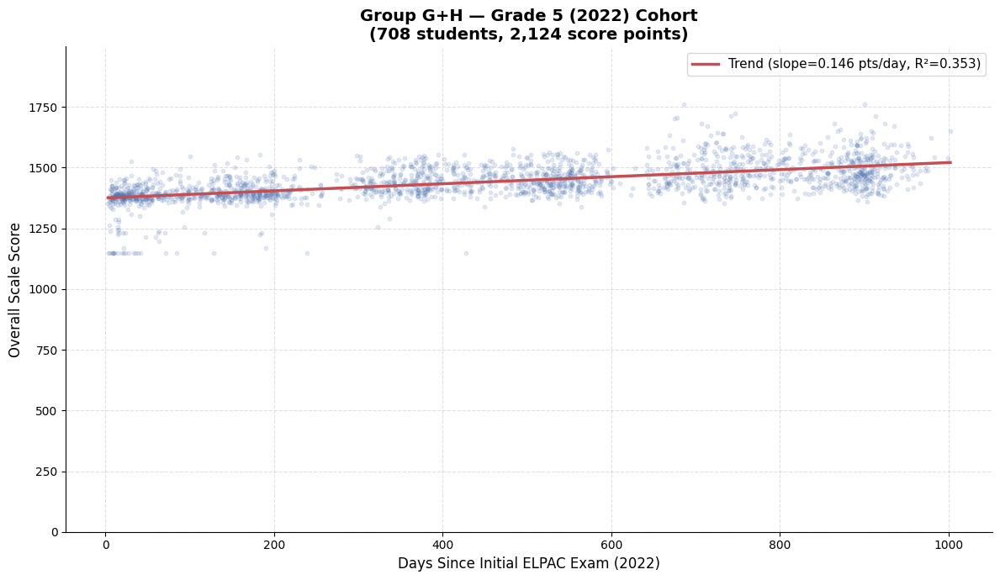

Saved: plots/group_gh_scatter_grade_05.png


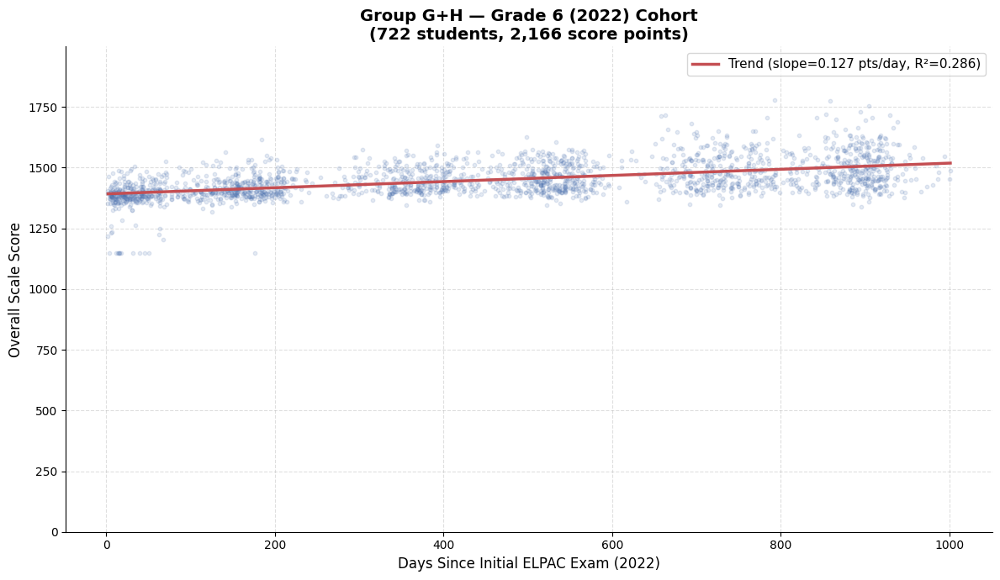

Saved: plots/group_gh_scatter_grade_06.png


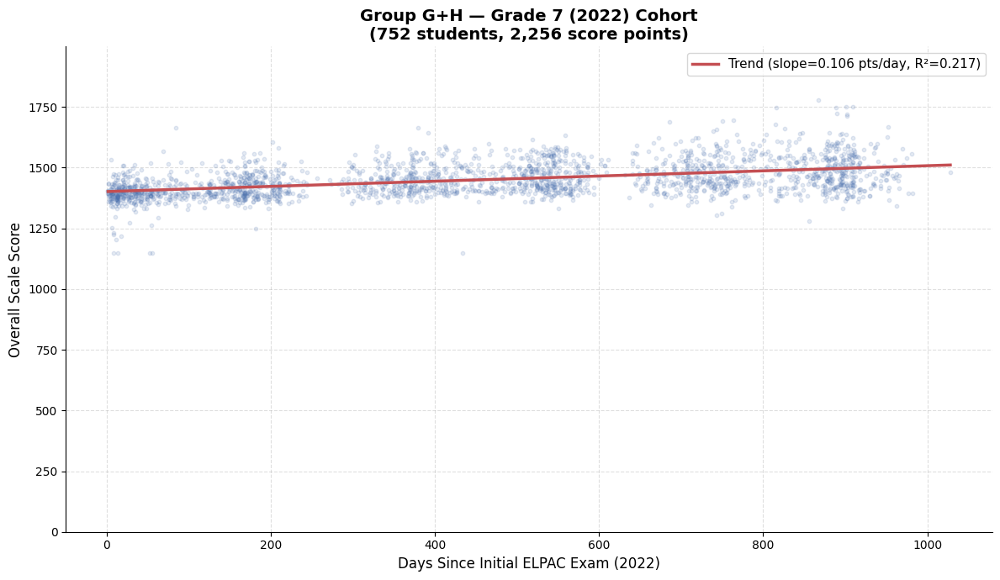

Saved: plots/group_gh_scatter_grade_07.png


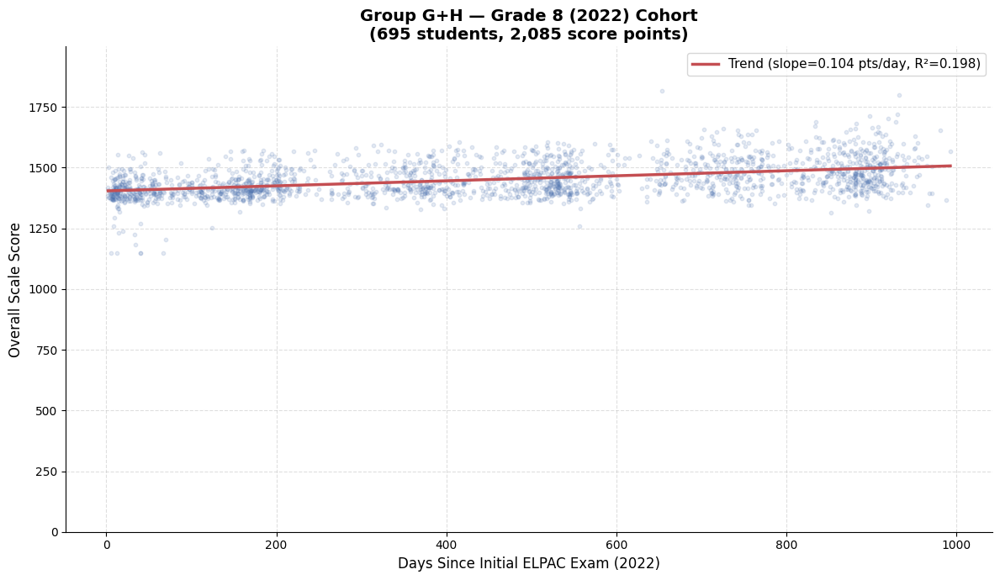

Saved: plots/group_gh_scatter_grade_08.png


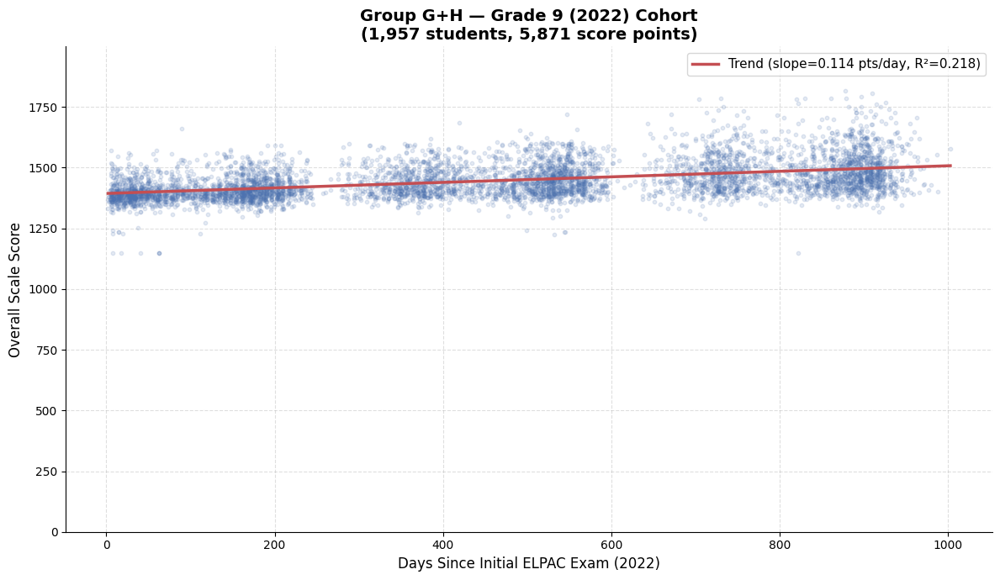

Saved: plots/group_gh_scatter_grade_09.png


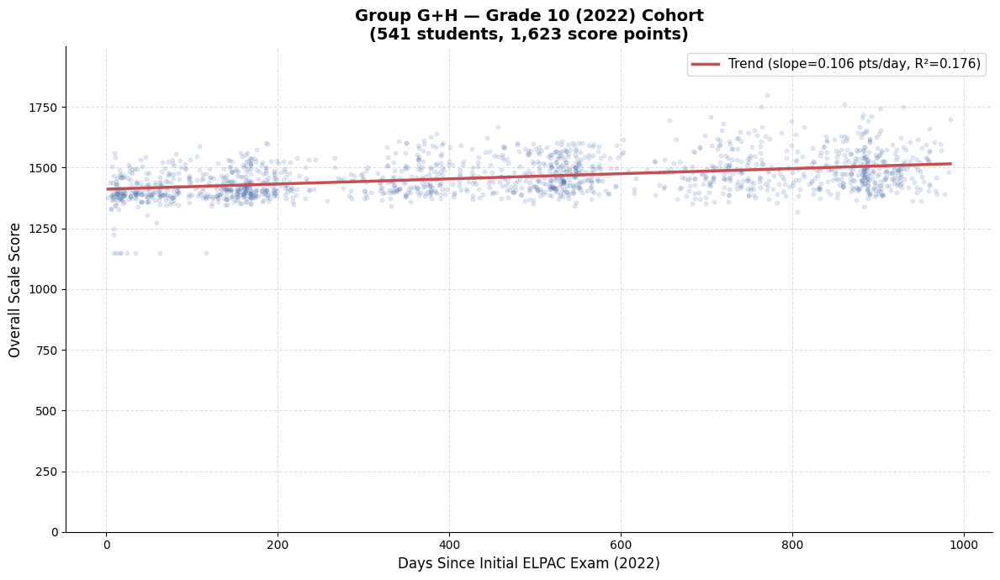

Saved: plots/group_gh_scatter_grade_10.png


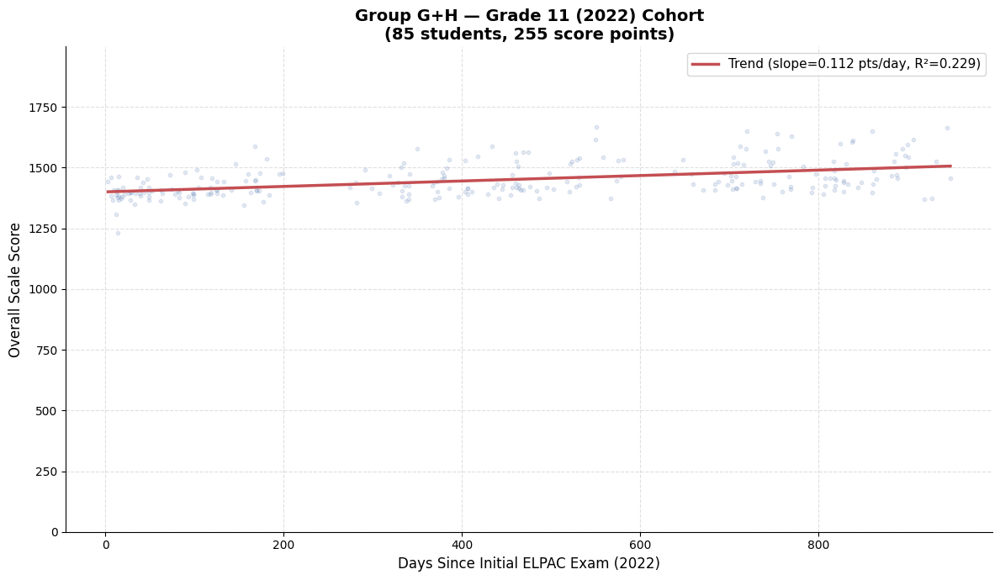

Saved: plots/group_gh_scatter_grade_11.png


In [20]:
# --- Scatter plot per grade ---
for grade in grades_present:
    grade_data = scatter_df[
        (scatter_df["GradeLevelCode"] == grade) &
        (scatter_df["days"] > 0) &
        (scatter_df["score"] > 1000)
    ]
    x = grade_data["days"].values
    y = grade_data["score"].values

    if len(x) < 2:
        print(f"Skipping {grade_labels[grade]} — insufficient data ({len(x)} points)")
        continue

    fig, ax = plt.subplots(figsize=(12, 7))
    ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    trend_x   = np.linspace(x.min(), x.max(), 300)
    r_squared = r_value ** 2
    ax.plot(trend_x, slope * trend_x + intercept, color="#C44E52", linewidth=2.5, zorder=3,
            label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

    ax.set_ylim(0, y_max)
    ax.set_xlabel("Days Since Initial ELPAC Exam (2022)", fontsize=12)
    ax.set_ylabel("Overall Scale Score", fontsize=12)
    ax.set_title(f"{group_label} — {grade_labels[grade]} (2022) Cohort\n"
                 f"({grade_data['SSID'].nunique():,} students, {len(x):,} score points)",
                 fontsize=14, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.savefig(f"plots/{group_short}_scatter_grade_{grade}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_scatter_grade_{grade}.png")

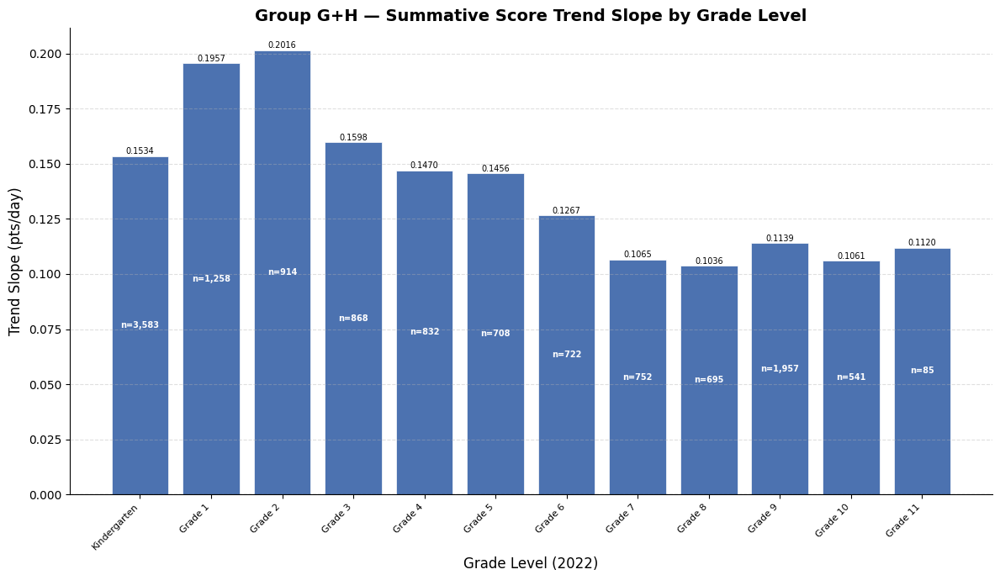

Saved: plots/group_gh_slope_by_grade.png


In [21]:
# --- Slope bar chart by Grade Level ---
grade_slopes = {}
grade_counts = {}

for grade in grades_present:
    grade_data = scatter_df[
        (scatter_df["GradeLevelCode"] == grade) &
        (scatter_df["days"] > 0) &
        (scatter_df["score"] > 1000)
    ]
    x = grade_data["days"].values
    y = grade_data["score"].values

    if len(x) < 2:
        continue

    slope, _, _, _, _ = stats.linregress(x, y)
    grade_slopes[grade] = slope
    grade_counts[grade] = grade_data["SSID"].nunique()

# Keep grade order (not sorted by slope) so the x-axis reads KN, 01, 02, ...
grade_names = [g for g in grade_order if g in grade_slopes]
slopes      = [grade_slopes[g] for g in grade_names]
counts      = [grade_counts[g] for g in grade_names]
labels      = [grade_labels[g] for g in grade_names]

# --- Bar chart ---
fig, ax = plt.subplots(figsize=(max(12, len(grade_names) * 0.9), 7))

colors = ["#4C72B0" if s >= 0 else "#C44E52" for s in slopes]
bars = ax.bar(range(len(grade_names)), slopes, color=colors, edgecolor="white", linewidth=0.5)

# Slope label above/below each bar
for bar, slope in zip(bars, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (0.0002 if slope >= 0 else -0.0002),
        f"{slope:.4f}",
        ha="center", va="bottom" if slope >= 0 else "top", fontsize=7
    )

# Student count inside each bar
for bar, count, slope in zip(bars, counts, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() / 2,
        f"n={count:,}",
        ha="center", va="center",
        fontsize=7, color="white", fontweight="bold"
    )

ax.set_xticks(range(len(grade_names)))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("Grade Level (2022)", fontsize=12)
ax.set_ylabel("Trend Slope (pts/day)", fontsize=12)
ax.set_title(f"{group_label} — Summative Score Trend Slope by Grade Level",
             fontsize=14, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(f"plots/{group_short}_slope_by_grade.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: plots/{group_short}_slope_by_grade.png")

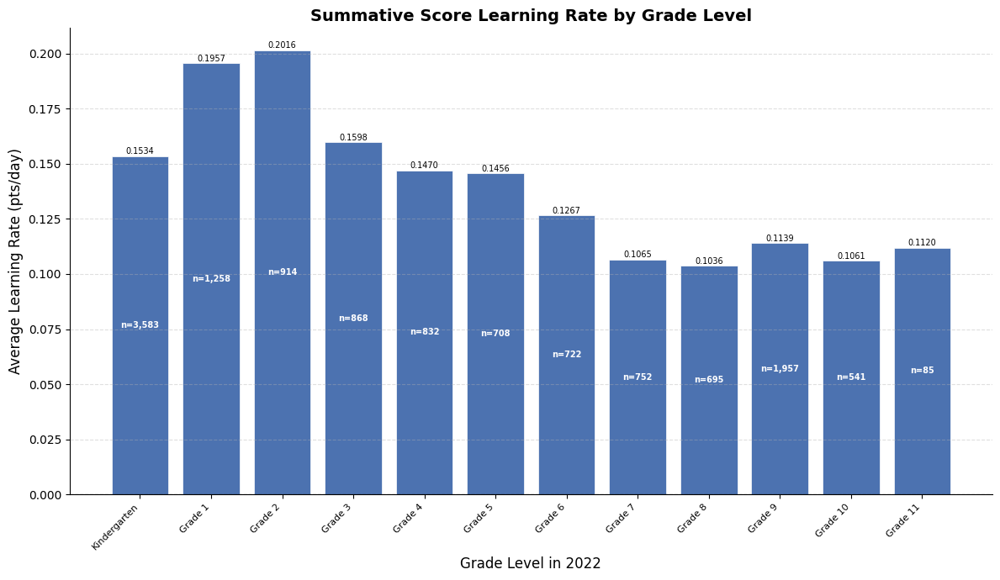

Saved: final_plots/group_gh_slope_by_grade.png


In [22]:
fig, ax = plt.subplots(figsize=(max(12, len(grade_names) * 0.9), 7))

colors = ["#4C72B0" if s >= 0 else "#C44E52" for s in slopes]
bars = ax.bar(range(len(grade_names)), slopes, color=colors, edgecolor="white", linewidth=0.5)

# Slope label above/below each bar
for bar, slope in zip(bars, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (0.0002 if slope >= 0 else -0.0002),
        f"{slope:.4f}",
        ha="center", va="bottom" if slope >= 0 else "top", fontsize=7
    )

# Student count inside each bar
for bar, count, slope in zip(bars, counts, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() / 2,
        f"n={count:,}",
        ha="center", va="center",
        fontsize=7, color="white", fontweight="bold"
    )

ax.set_xticks(range(len(grade_names)))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("Grade Level in 2022", fontsize=12)
ax.set_ylabel("Average Learning Rate (pts/day)", fontsize=12)
ax.set_title(f"Summative Score Learning Rate by Grade Level",
             fontsize=14, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(f"final_plots/{group_short}_slope_by_grade.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: final_plots/{group_short}_slope_by_grade.png")

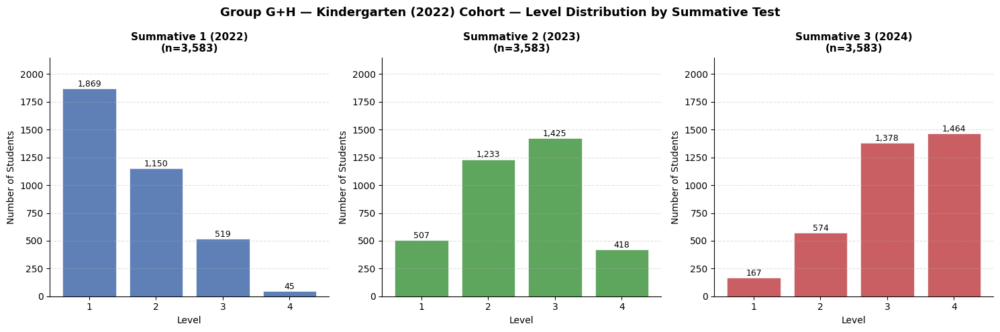

Saved: plots/group_gh_level_distribution_grade_KN.png


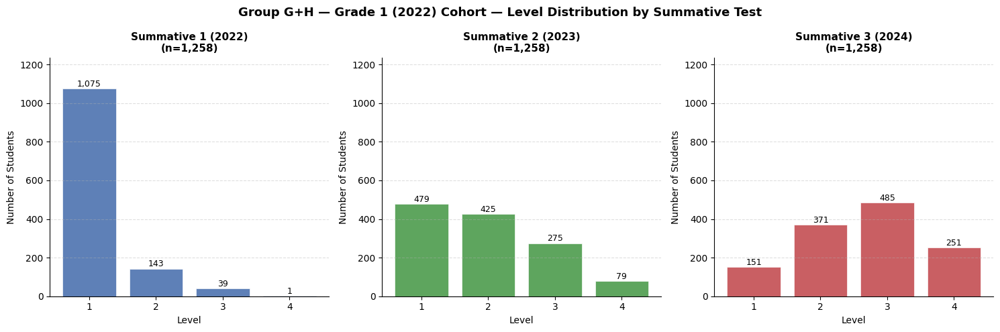

Saved: plots/group_gh_level_distribution_grade_01.png


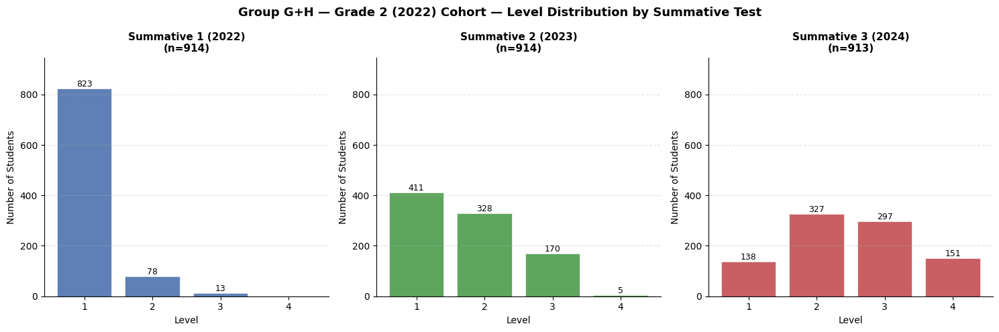

Saved: plots/group_gh_level_distribution_grade_02.png


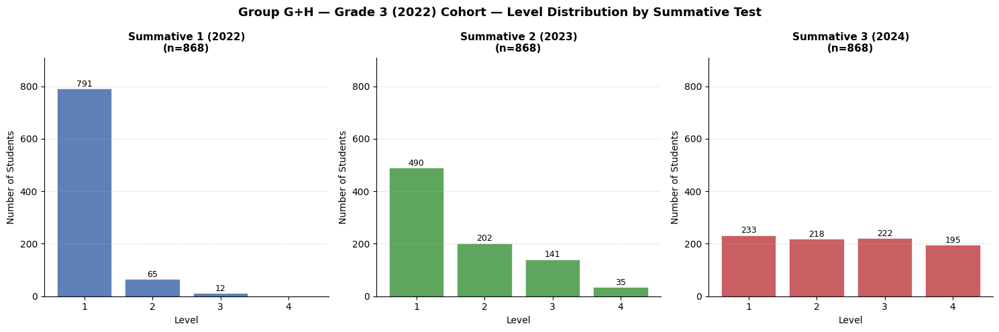

Saved: plots/group_gh_level_distribution_grade_03.png


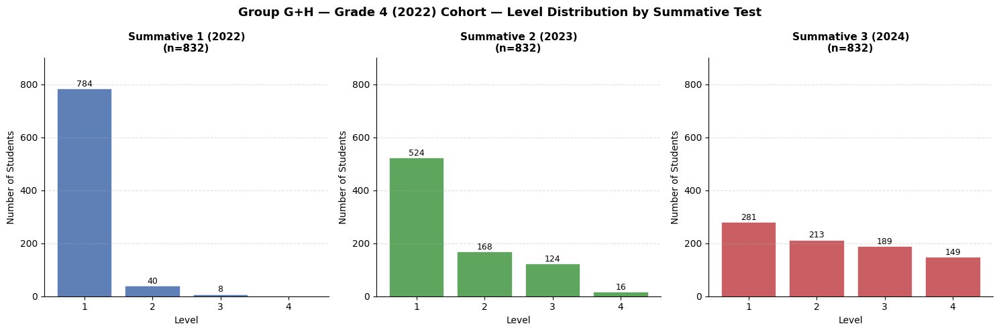

Saved: plots/group_gh_level_distribution_grade_04.png


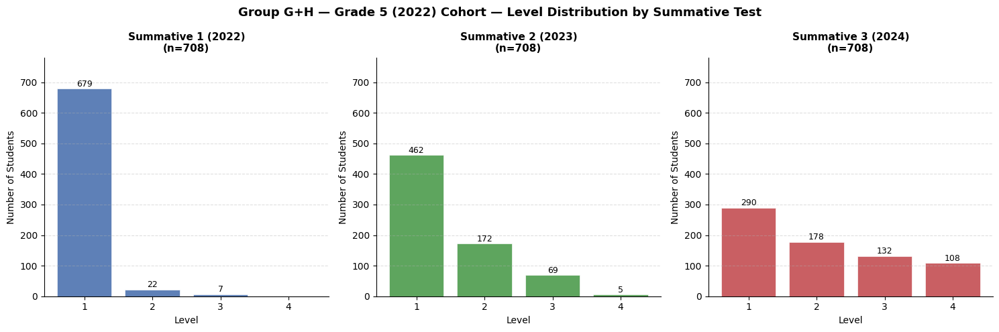

Saved: plots/group_gh_level_distribution_grade_05.png


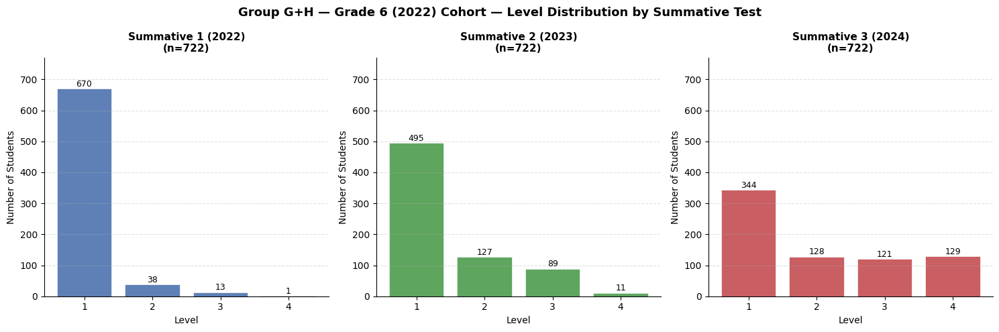

Saved: plots/group_gh_level_distribution_grade_06.png


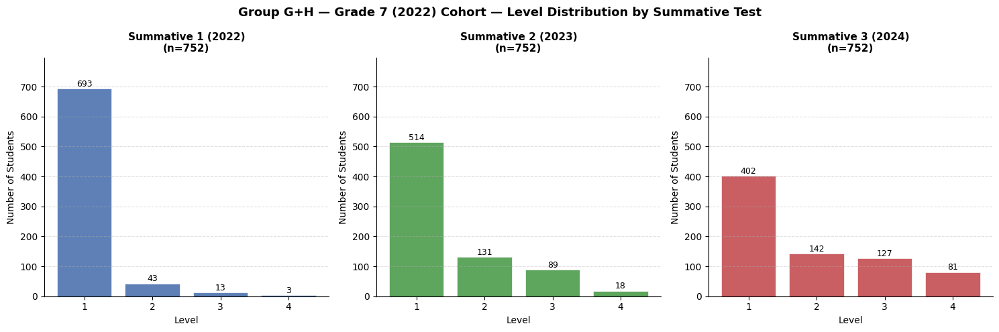

Saved: plots/group_gh_level_distribution_grade_07.png


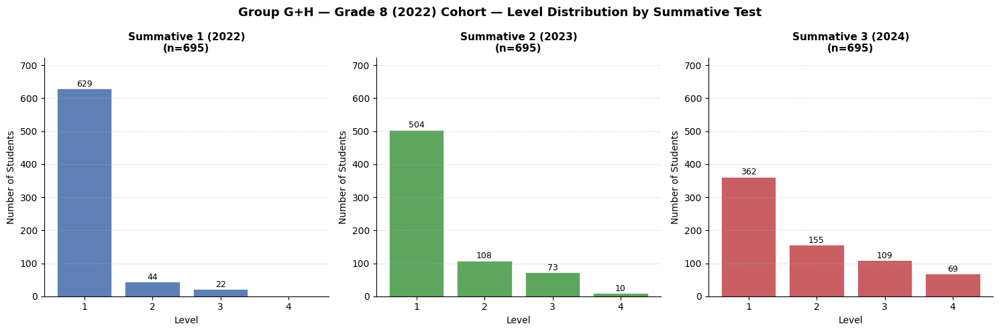

Saved: plots/group_gh_level_distribution_grade_08.png


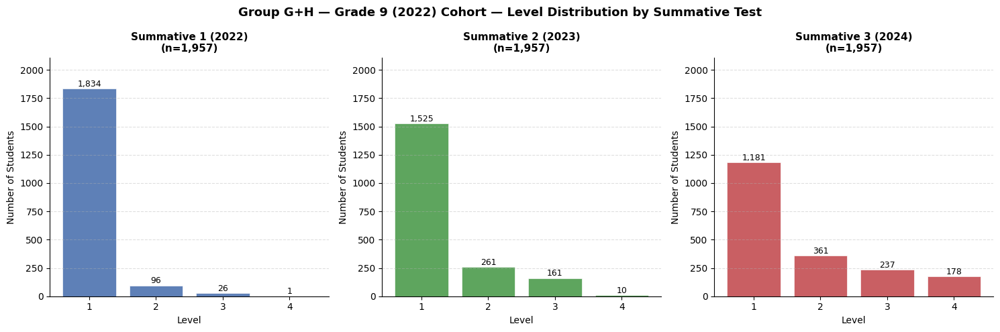

Saved: plots/group_gh_level_distribution_grade_09.png


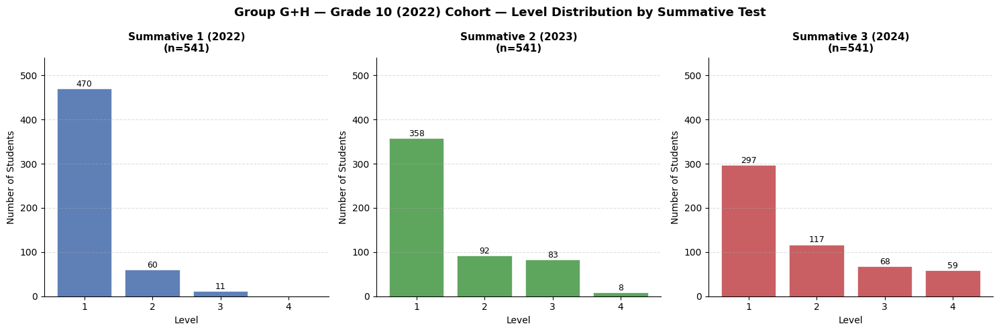

Saved: plots/group_gh_level_distribution_grade_10.png


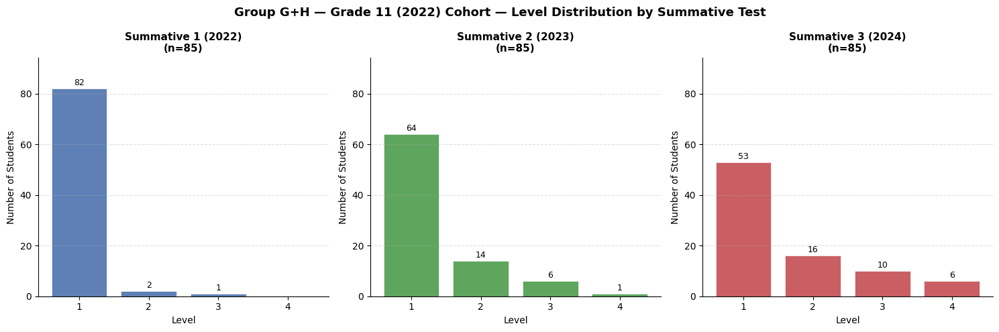

Saved: plots/group_gh_level_distribution_grade_11.png


In [23]:
# --- Level distribution per grade: 3 subplots with consistent y-axis ---
test_years  = {1: "2022", 2: "2023", 3: "2024"}
test_colors = ["#4C72B0", "#4C9B4C", "#C44E52"]

for grade in grades_present:
    grade_data = scored_df[scored_df["GradeLevelCode"] == grade]
    if len(grade_data) == 0:
        continue

    # Find y-axis max across all 3 tests for this grade
    grade_y_max = 0
    for test_num in [1, 2, 3]:
        test_data = grade_data[grade_data["TestNumber"] == test_num]["Level"].dropna()
        counts    = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        grade_y_max = max(grade_y_max, counts.max())
    grade_y_max = grade_y_max * 1.15  # 15% headroom for count labels

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f"{group_label} — {grade_labels[grade]} (2022) Cohort — Level Distribution by Summative Test",
                 fontsize=13, fontweight="bold")

    for ax, (test_num, color) in zip(axes, zip([1, 2, 3], test_colors)):
        test_data = grade_data[grade_data["TestNumber"] == test_num]["Level"].dropna()
        counts    = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        bars      = ax.bar(counts.index, counts.values, color=color,
                           edgecolor="white", linewidth=0.5, alpha=0.9)

        for bar, count in zip(bars, counts.values):
            if count > 0:
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                        f"{count:,}", ha="center", va="bottom", fontsize=9)

        ax.set_ylim(0, grade_y_max)
        ax.set_title(f"Summative {test_num} ({test_years[test_num]})\n(n={len(test_data):,})",
                     fontsize=11, fontweight="bold")
        ax.set_xlabel("Level", fontsize=10)
        ax.set_ylabel("Number of Students", fontsize=10)
        ax.set_xticks([1, 2, 3, 4])
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.savefig(f"plots/{group_short}_level_distribution_grade_{grade}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_level_distribution_grade_{grade}.png")

# Break out by District

In [24]:
# --- Get district from 2021-22 enrollment ---
district_2022 = (
    enrollment_dfs["2021-22"][["SSID", "CDCode", "Districtname"]]
    .dropna()
    .drop_duplicates(subset="SSID", keep="first")
)

# --- Merge district into scatter_df and scored_df ---
scatter_df = scatter_df.merge(district_2022, on="SSID", how="left")
scored_df  = scored_df.merge(district_2022, on="SSID", how="left")

# --- Unique districts sorted by name ---
districts = (
    scatter_df[["CDCode", "Districtname"]]
    .dropna()
    .drop_duplicates()
    .sort_values("Districtname")
    .reset_index(drop=True)
)
print(f"Unique districts: {len(districts)}")
print(districts.to_string(index=False))

Unique districts: 23
 CDCode                           Districtname
3366977                         Alvord Unified
3767991                     Cajon Valley Union
3467314                      Elk Grove Unified
1062166                         Fresno Unified
3066522                   Garden Grove Unified
1964568                       Glendale Unified
3768130                   Grossmont Union High
 161192                        Hayward Unified
1910199 Los Angeles County Office of Education
1964733                    Los Angeles Unified
1075127                        Mendota Unified
5071167                Modesto City Elementary
5071175                      Modesto City High
 761754                     Mt. Diablo Unified
 161259                        Oakland Unified
3768338                      San Diego Unified
3868478                  San Francisco Unified
3467447                       San Juan Unified
2165458             San Rafael City Elementary
2165466                   San Rafael Ci

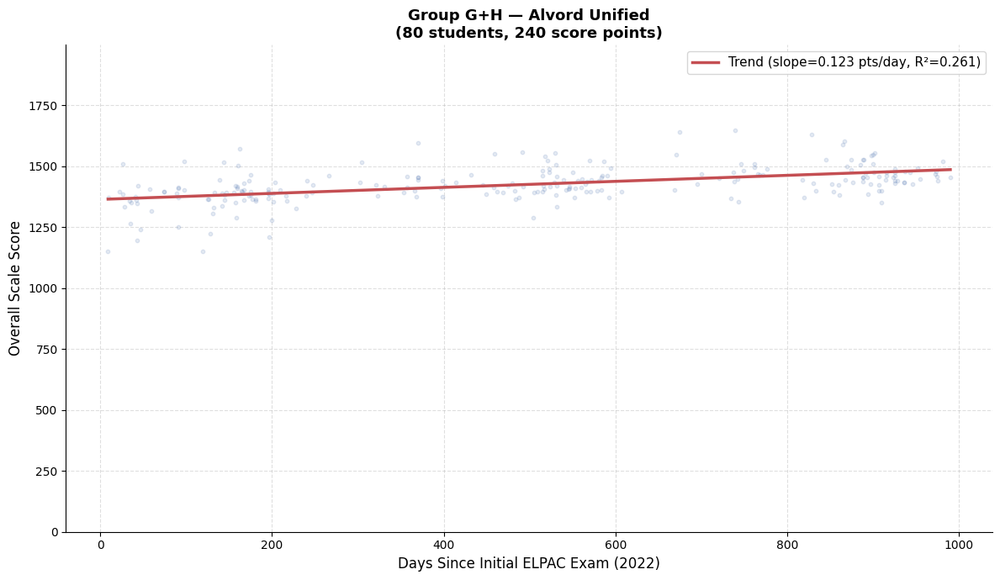

Saved: plots/group_gh_scatter_district_3366977_Alvord_Unified.png


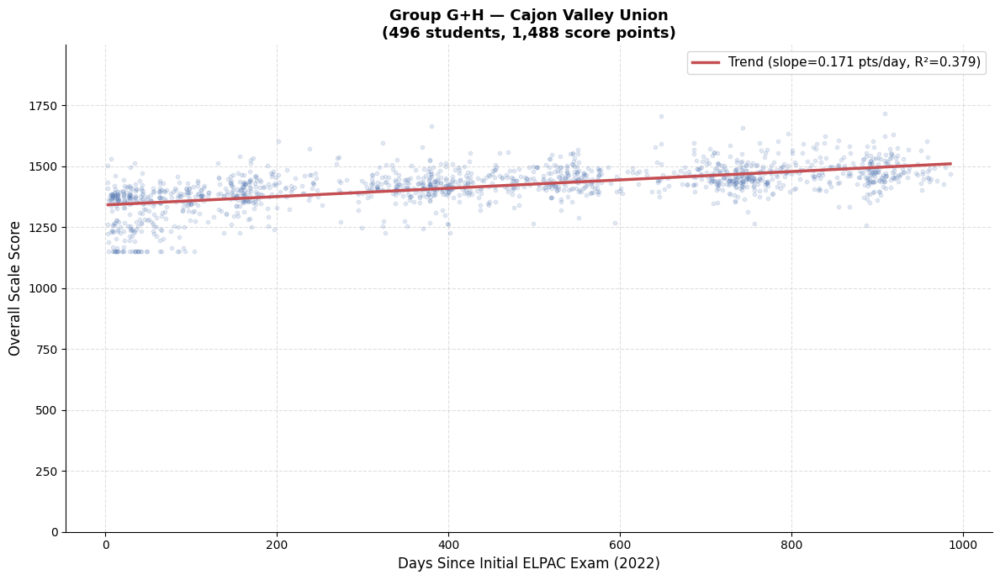

Saved: plots/group_gh_scatter_district_3767991_Cajon_Valley_Union.png


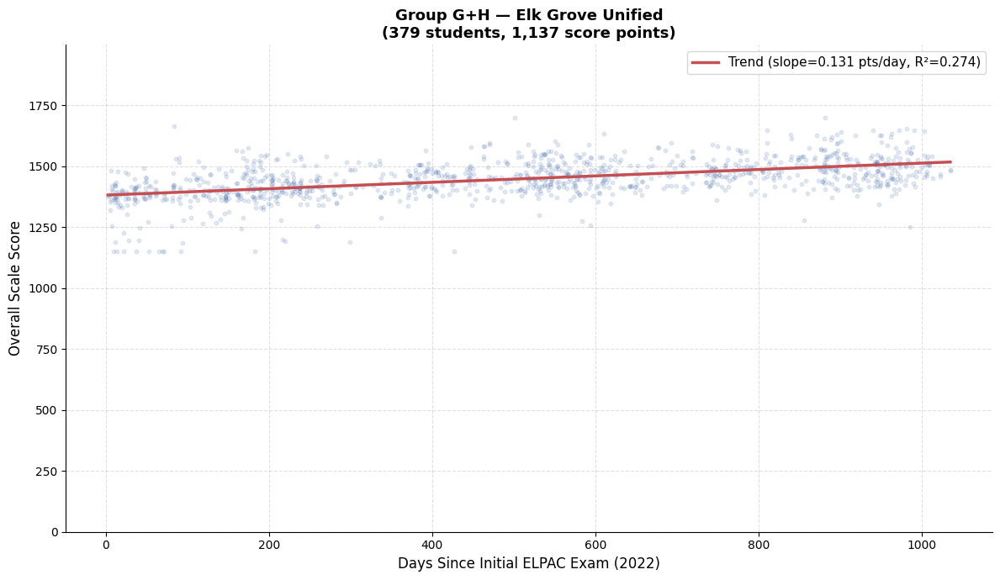

Saved: plots/group_gh_scatter_district_3467314_Elk_Grove_Unified.png


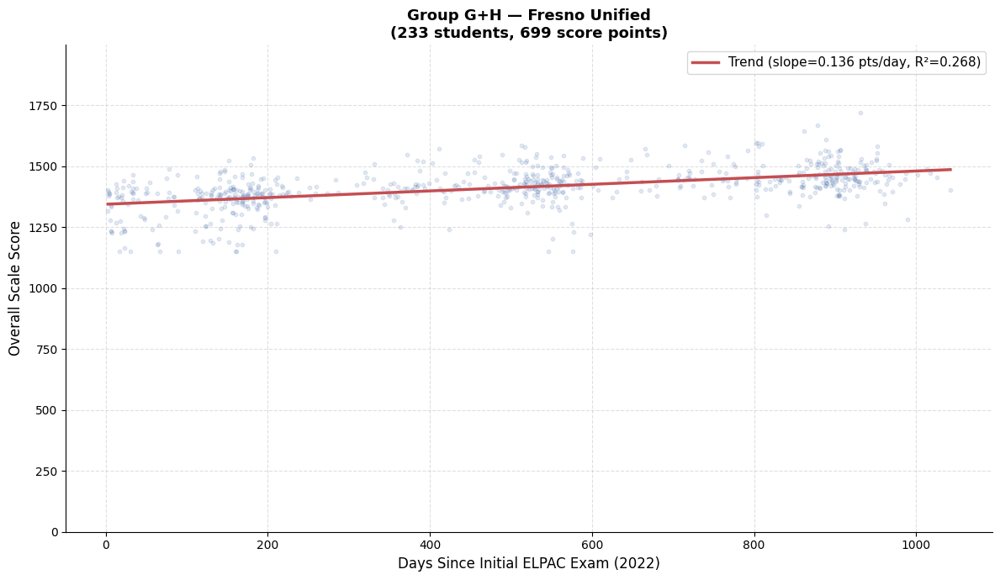

Saved: plots/group_gh_scatter_district_1062166_Fresno_Unified.png


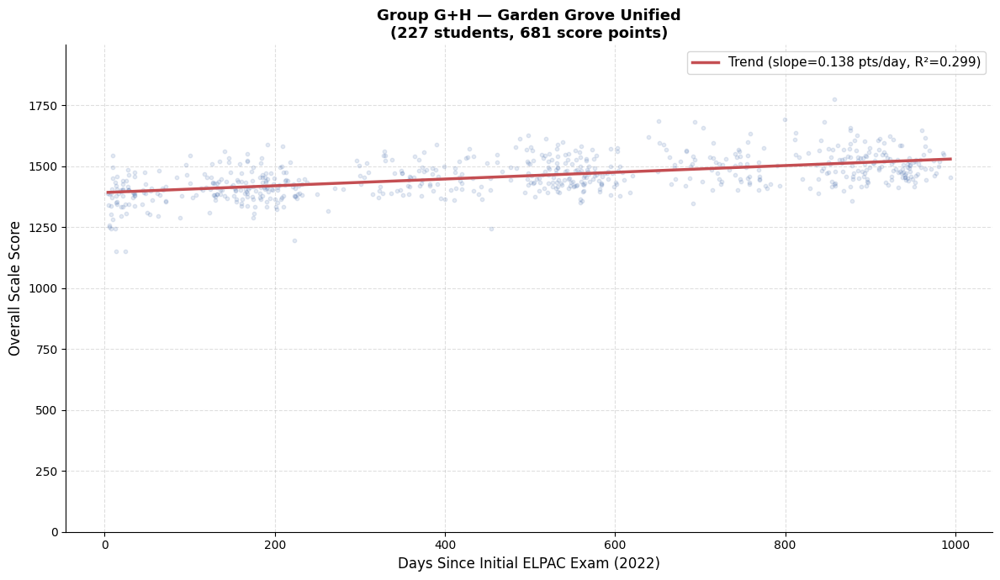

Saved: plots/group_gh_scatter_district_3066522_Garden_Grove_Unified.png


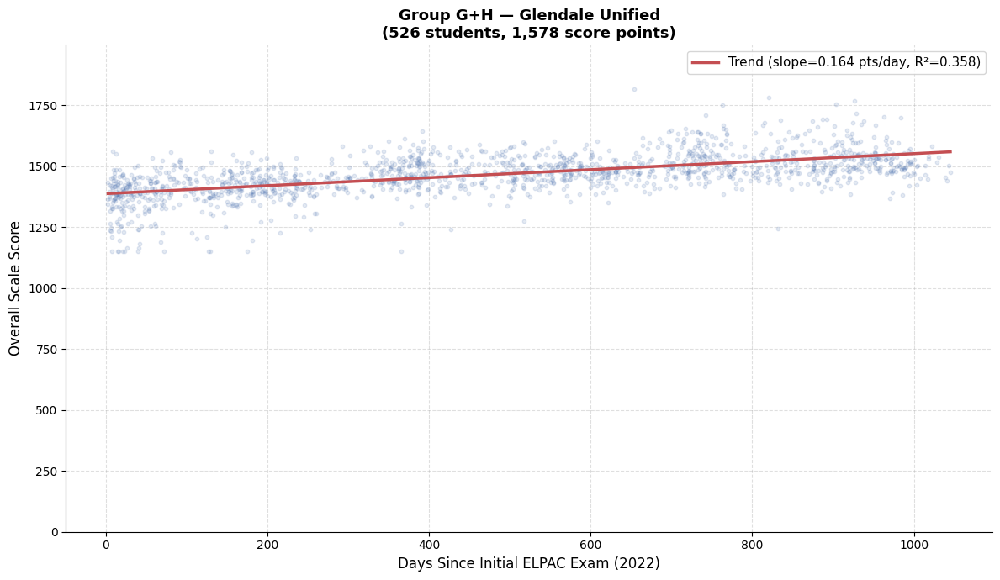

Saved: plots/group_gh_scatter_district_1964568_Glendale_Unified.png


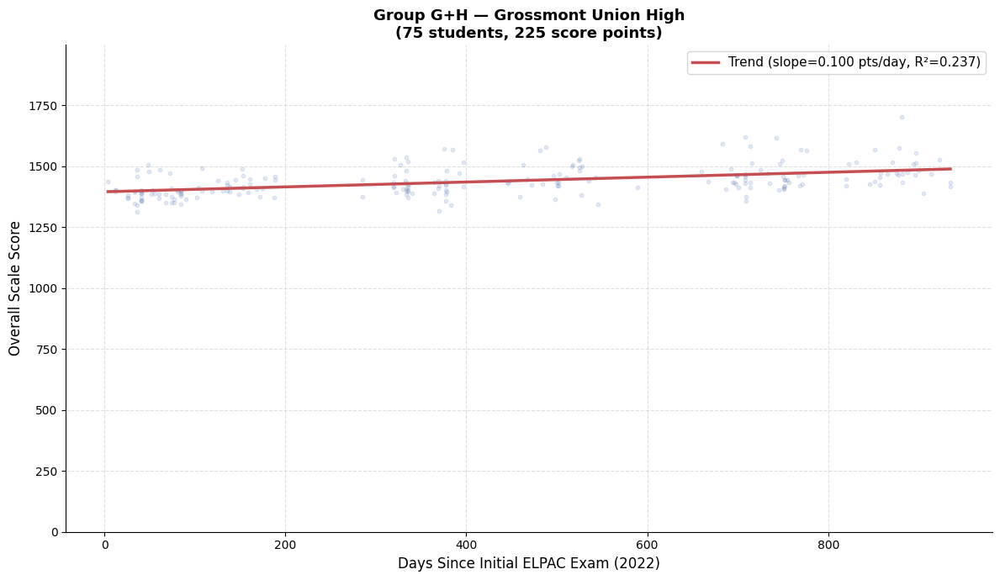

Saved: plots/group_gh_scatter_district_3768130_Grossmont_Union_High.png


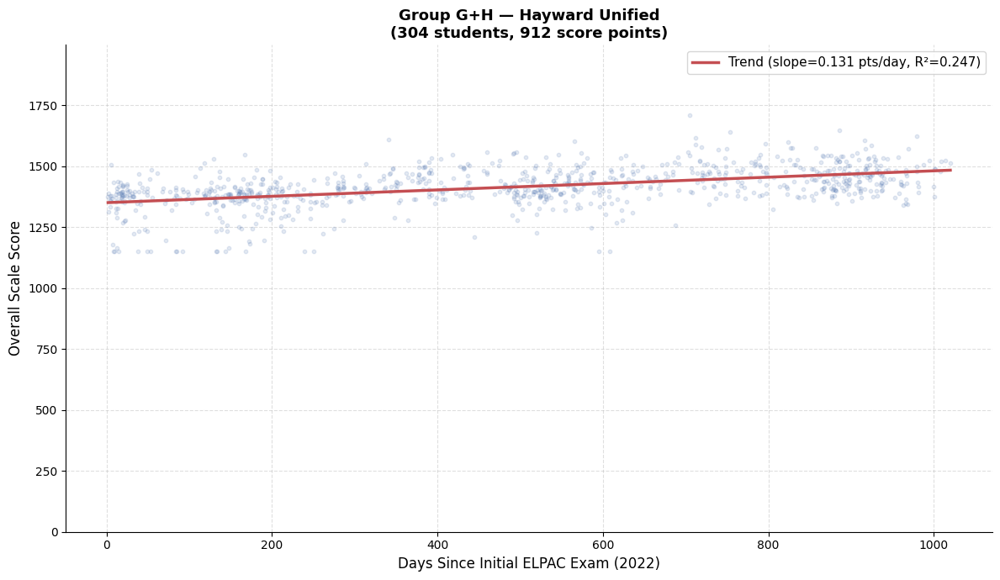

Saved: plots/group_gh_scatter_district_161192_Hayward_Unified.png


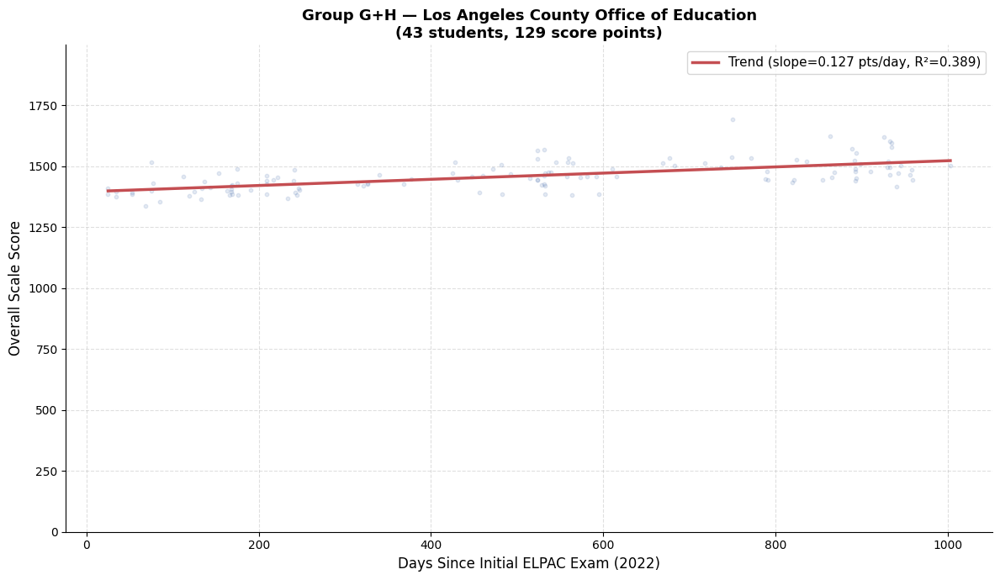

Saved: plots/group_gh_scatter_district_1910199_Los_Angeles_County_Office_of_Education.png


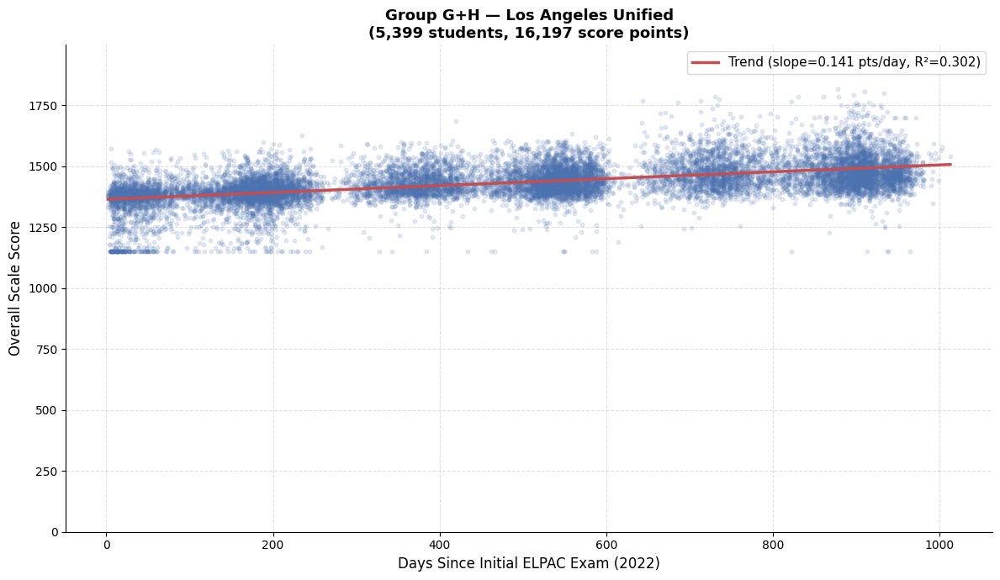

Saved: plots/group_gh_scatter_district_1964733_Los_Angeles_Unified.png


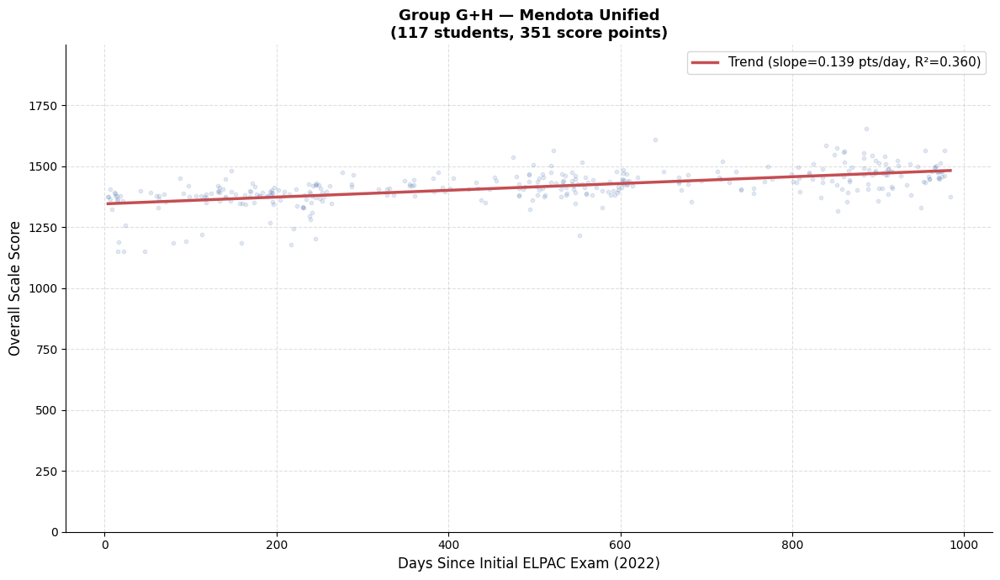

Saved: plots/group_gh_scatter_district_1075127_Mendota_Unified.png


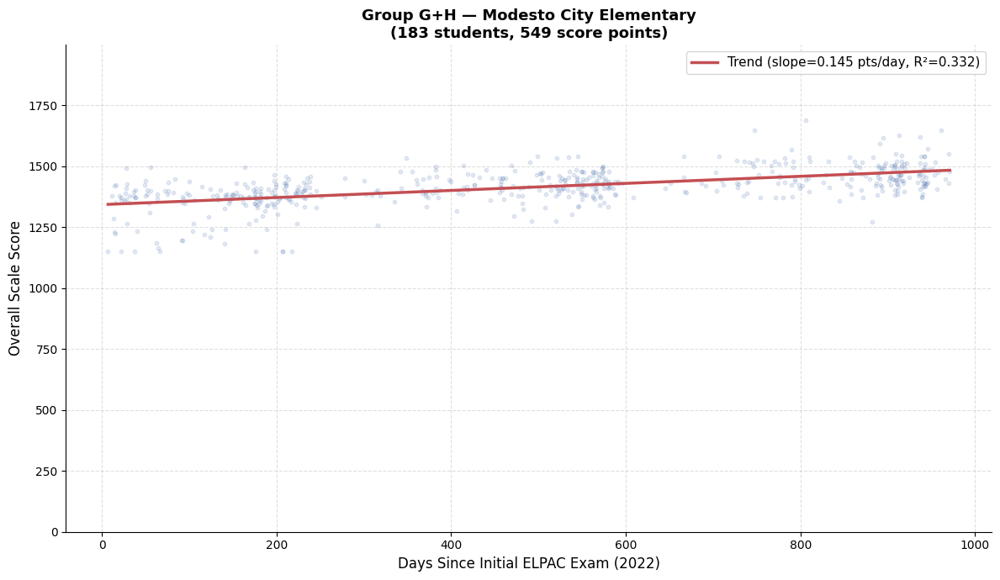

Saved: plots/group_gh_scatter_district_5071167_Modesto_City_Elementary.png


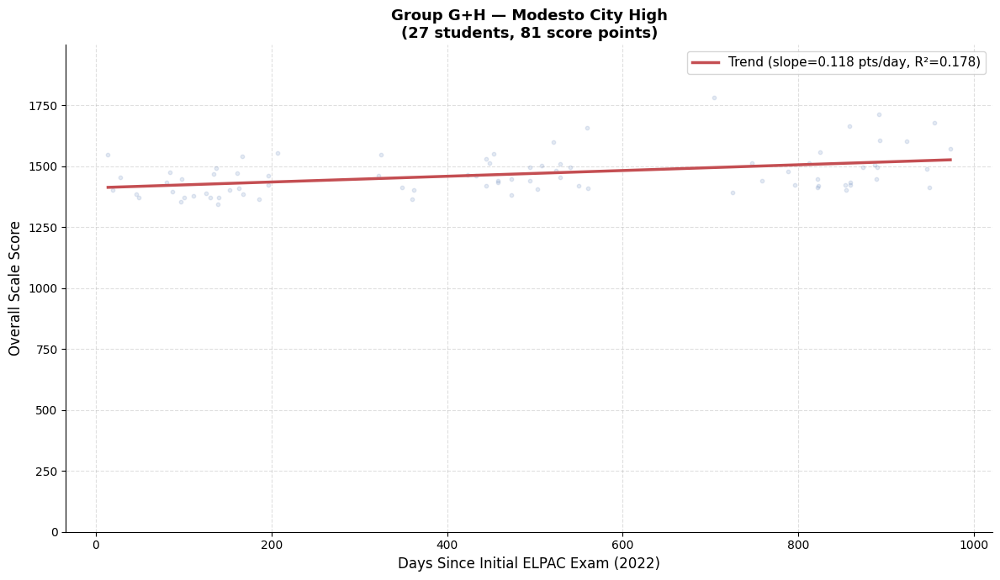

Saved: plots/group_gh_scatter_district_5071175_Modesto_City_High.png


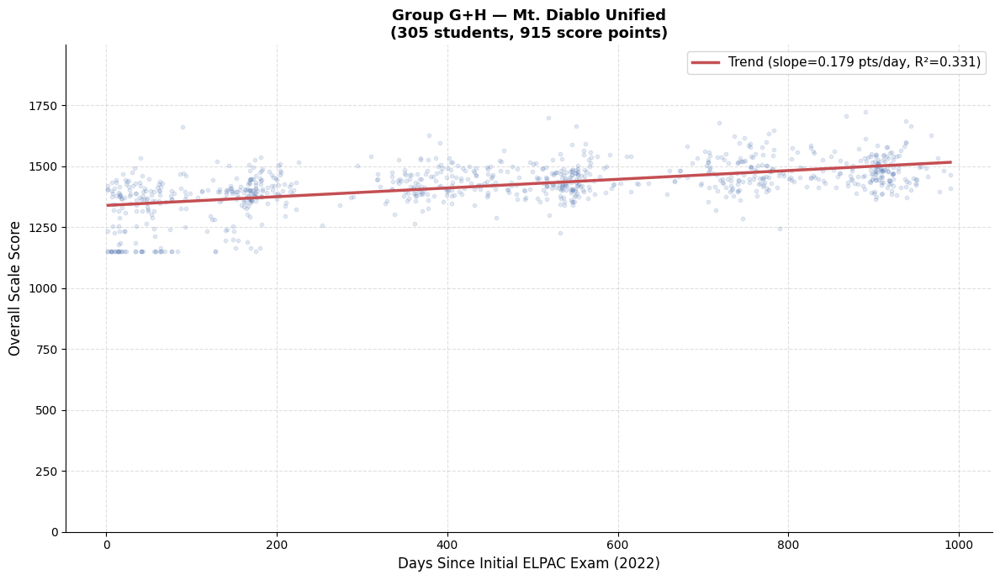

Saved: plots/group_gh_scatter_district_761754_Mt._Diablo_Unified.png


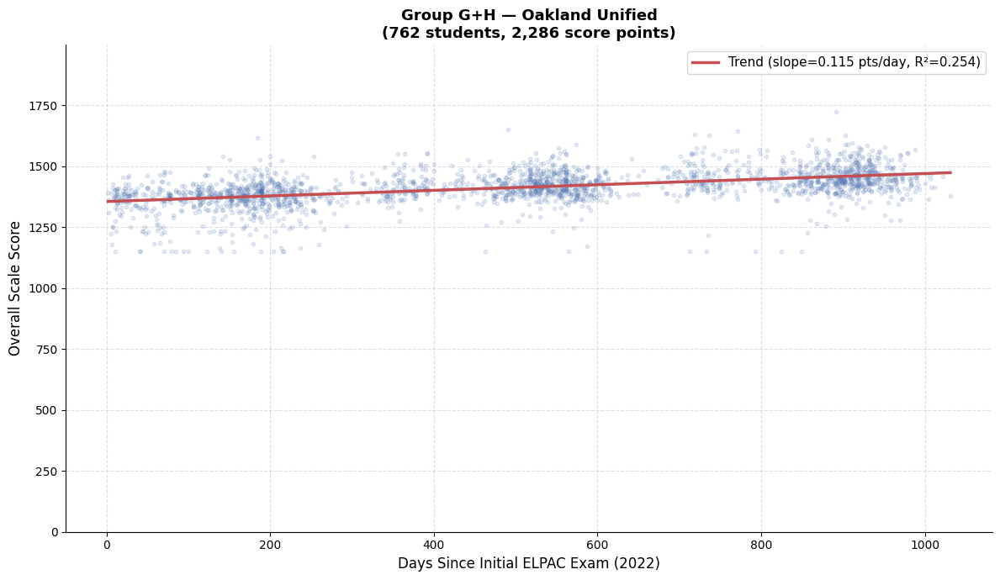

Saved: plots/group_gh_scatter_district_161259_Oakland_Unified.png


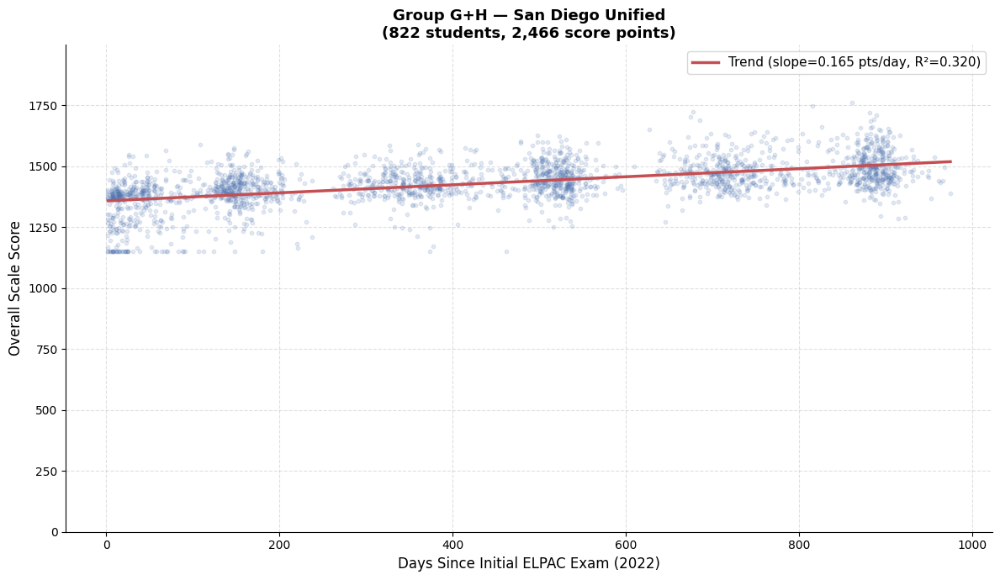

Saved: plots/group_gh_scatter_district_3768338_San_Diego_Unified.png


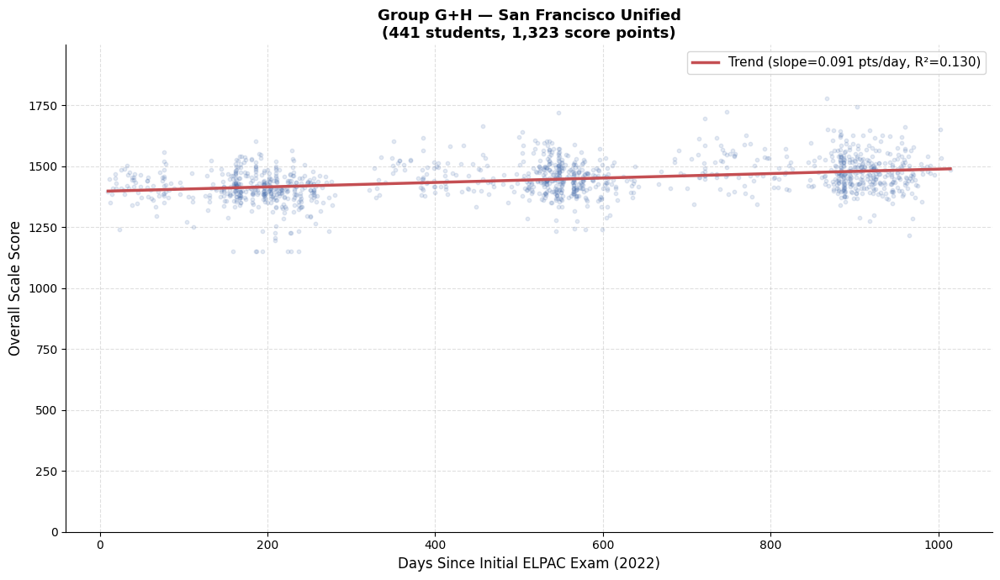

Saved: plots/group_gh_scatter_district_3868478_San_Francisco_Unified.png


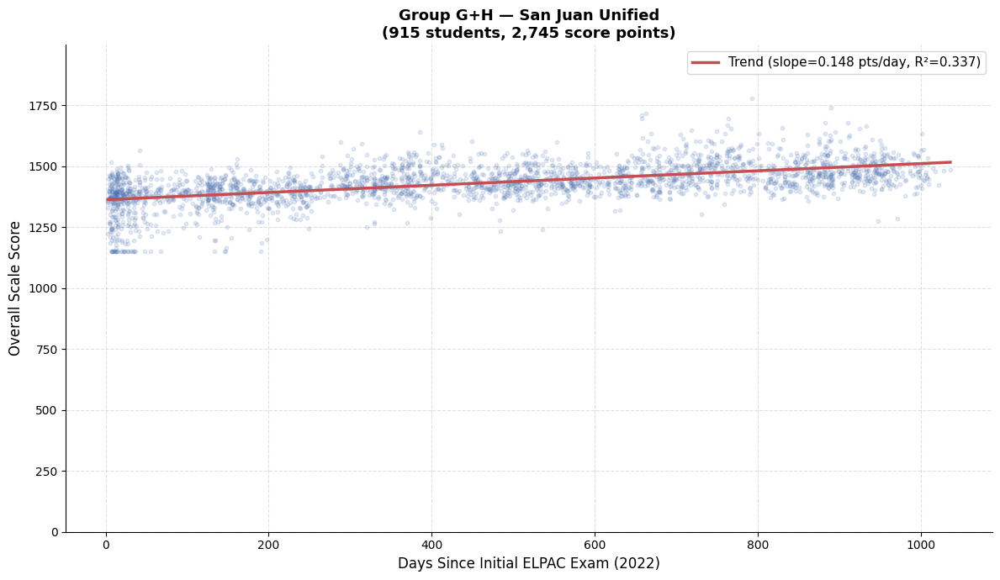

Saved: plots/group_gh_scatter_district_3467447_San_Juan_Unified.png


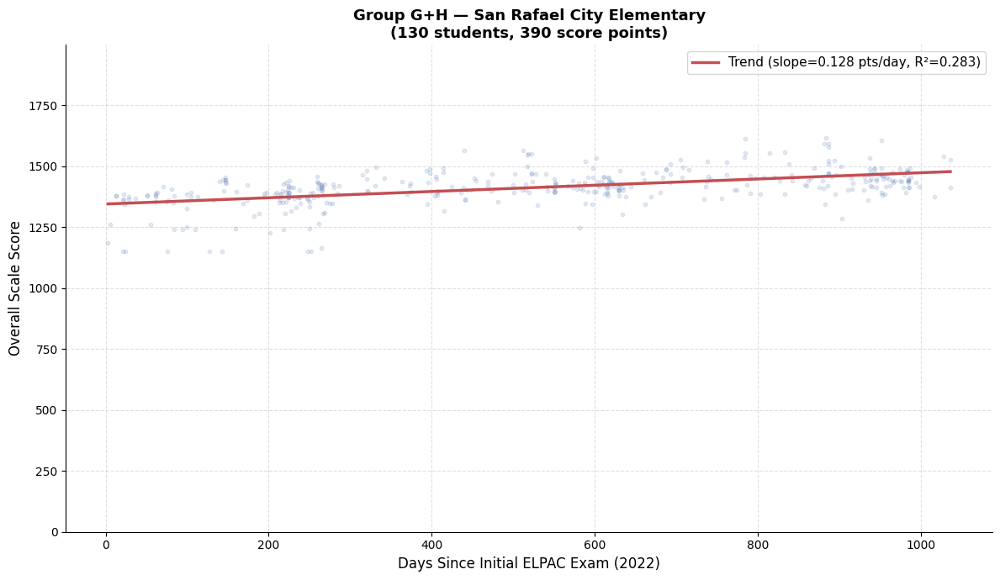

Saved: plots/group_gh_scatter_district_2165458_San_Rafael_City_Elementary.png


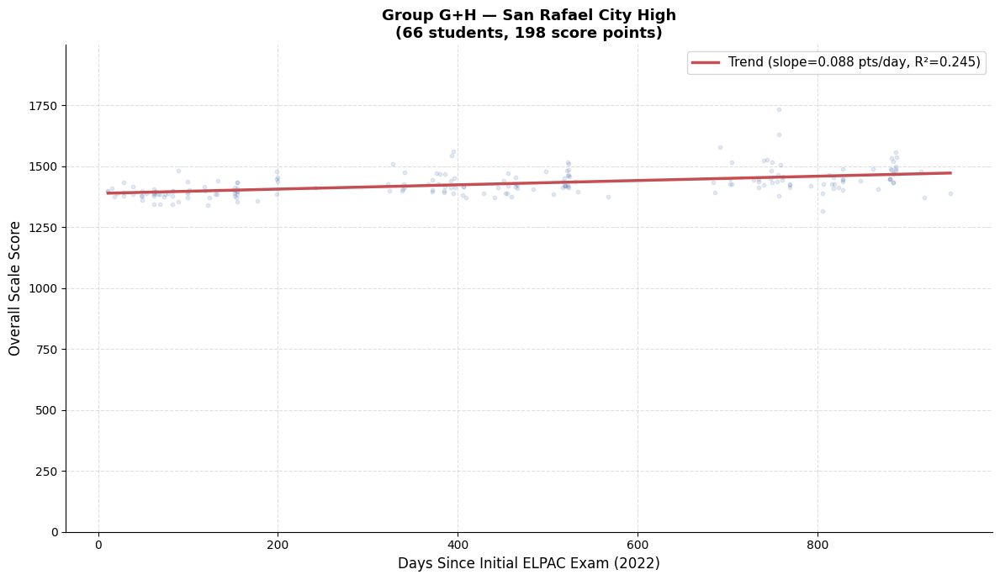

Saved: plots/group_gh_scatter_district_2165466_San_Rafael_City_High.png


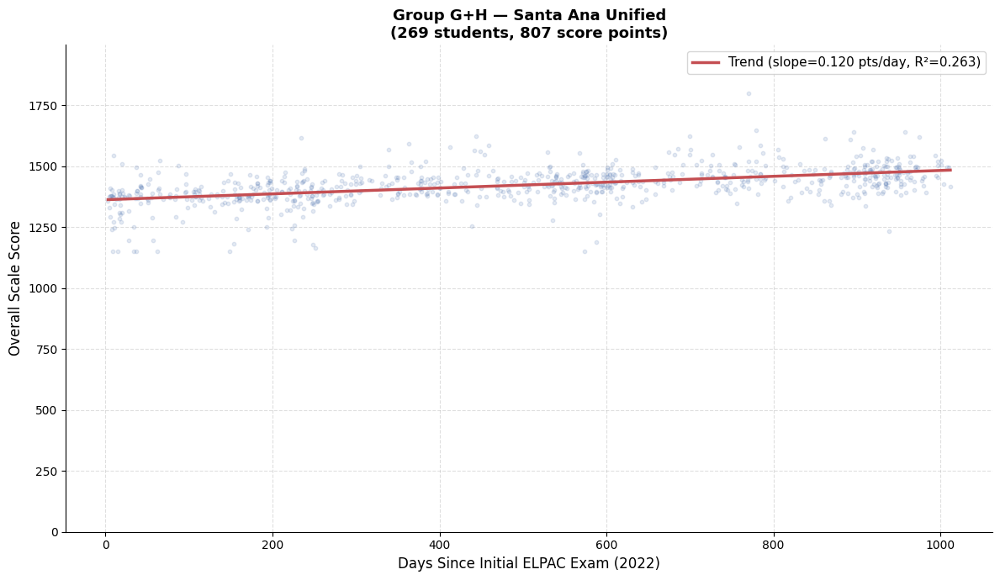

Saved: plots/group_gh_scatter_district_3066670_Santa_Ana_Unified.png


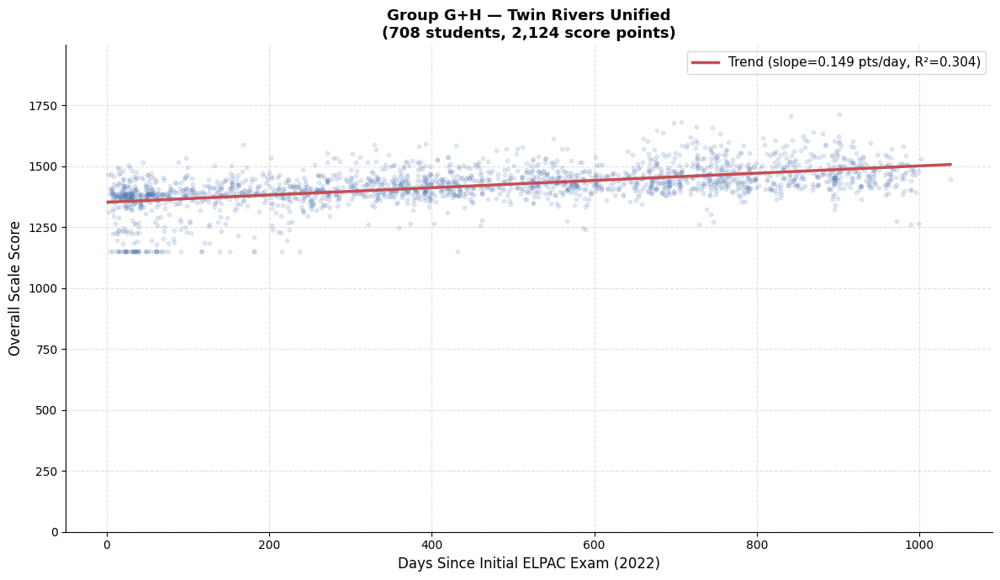

Saved: plots/group_gh_scatter_district_3476505_Twin_Rivers_Unified.png


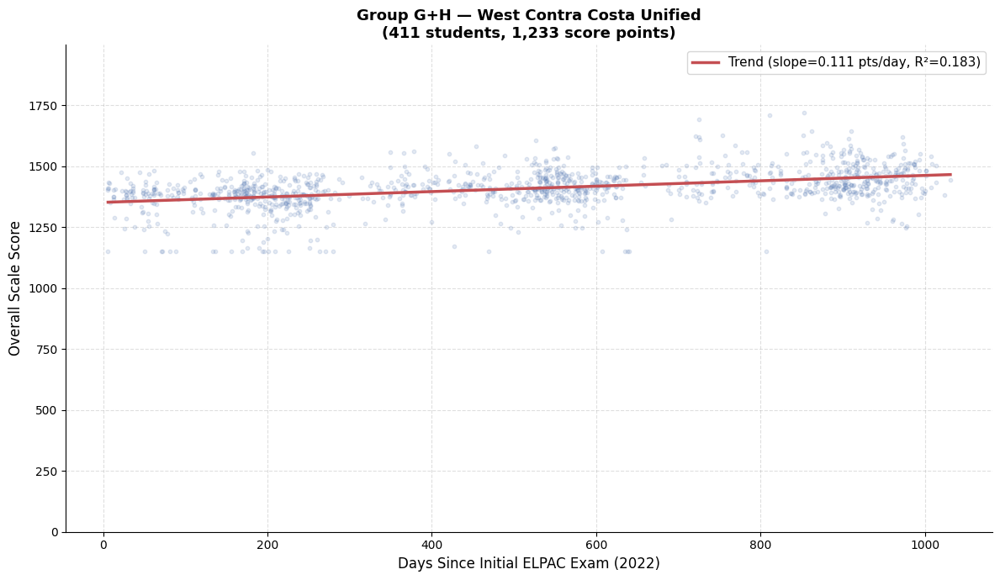

Saved: plots/group_gh_scatter_district_761796_West_Contra_Costa_Unified.png


In [25]:
# --- Scatter plot per district ---
for _, district_row in districts.iterrows():
    cd_code   = district_row["CDCode"]
    dist_name = district_row["Districtname"]

    dist_data = scatter_df[
        (scatter_df["CDCode"] == cd_code) &
        (scatter_df["days"] > 0) &
        (scatter_df["score"] > 1000)
    ]
    x = dist_data["days"].values
    y = dist_data["score"].values

    if len(x) < 2:
        print(f"Skipping {dist_name} — insufficient data ({len(x)} points)")
        continue

    fig, ax = plt.subplots(figsize=(12, 7))
    ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    trend_x   = np.linspace(x.min(), x.max(), 300)
    r_squared = r_value ** 2
    ax.plot(trend_x, slope * trend_x + intercept, color="#C44E52", linewidth=2.5, zorder=3,
            label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

    ax.set_ylim(0, y_max)
    ax.set_xlabel("Days Since Initial ELPAC Exam (2022)", fontsize=12)
    ax.set_ylabel("Overall Scale Score", fontsize=12)
    ax.set_title(f"{group_label} — {dist_name}\n"
                 f"({dist_data['SSID'].nunique():,} students, {len(x):,} score points)",
                 fontsize=13, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_name = str(dist_name).replace(" ", "_").replace("/", "_")
    plt.savefig(f"plots/{group_short}_scatter_district_{cd_code}_{safe_name}.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_scatter_district_{cd_code}_{safe_name}.png")

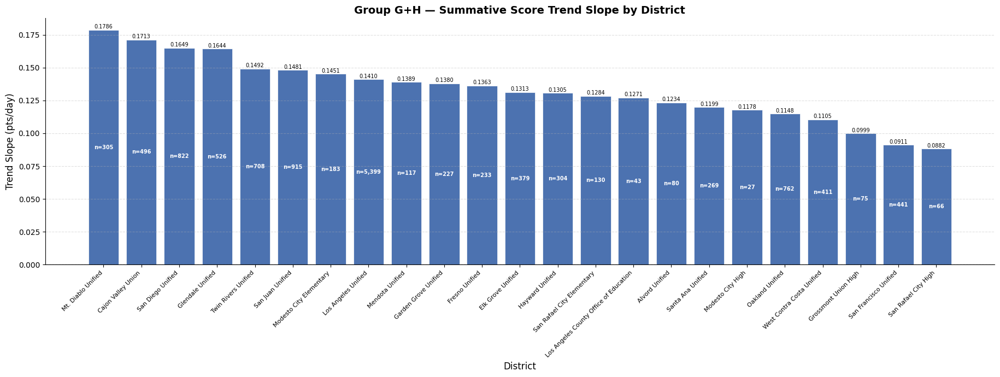

Saved: plots/group_gh_slope_by_district.png


In [26]:
# --- Slope bar chart by district ---
district_slopes = {}
district_counts = {}

for _, district_row in districts.iterrows():
    cd_code   = district_row["CDCode"]
    dist_name = district_row["Districtname"]

    dist_data = scatter_df[
        (scatter_df["CDCode"] == cd_code) &
        (scatter_df["days"] > 0) &
        (scatter_df["score"] > 1000)
    ]
    x = dist_data["days"].values
    y = dist_data["score"].values

    if len(x) < 2:
        continue

    slope, _, _, _, _ = stats.linregress(x, y)
    district_slopes[dist_name] = slope
    district_counts[dist_name] = dist_data["SSID"].nunique()

# Sort by slope descending
sorted_districts = sorted(district_slopes.items(), key=lambda kv: -kv[1])
dist_names = [d[0] for d in sorted_districts]
slopes     = [d[1] for d in sorted_districts]
counts     = [district_counts[d] for d in dist_names]

# --- Bar chart ---
fig, ax = plt.subplots(figsize=(max(14, len(dist_names) * 0.8), 7))

colors = ["#4C72B0" if s >= 0 else "#C44E52" for s in slopes]
bars = ax.bar(range(len(dist_names)), slopes, color=colors, edgecolor="white", linewidth=0.5)

# Slope label above/below each bar
for bar, slope in zip(bars, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (0.0002 if slope >= 0 else -0.0002),
        f"{slope:.4f}",
        ha="center", va="bottom" if slope >= 0 else "top", fontsize=7
    )

# Student count inside each bar
for bar, count, slope in zip(bars, counts, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() / 2,
        f"n={count:,}",
        ha="center", va="center",
        fontsize=7, color="white", fontweight="bold"
    )

ax.set_xticks(range(len(dist_names)))
ax.set_xticklabels(dist_names, rotation=45, ha="right", fontsize=8)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("District", fontsize=12)
ax.set_ylabel("Trend Slope (pts/day)", fontsize=12)
ax.set_title(f"{group_label} — Summative Score Trend Slope by District", fontsize=14, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(f"plots/{group_short}_slope_by_district.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: plots/{group_short}_slope_by_district.png")

In [33]:
dist_names2 = dist_names.copy()

In [41]:
dist_names2=[]
for x in dist_names:
    if x=='Los Angeles County Office of Education':
        x='LA County Office of Ed.'
        print('replaced')
    dist_names2.append(x)
dist_names2

replaced


['Mt. Diablo Unified',
 'Cajon Valley Union',
 'San Diego Unified',
 'Glendale Unified',
 'Twin Rivers Unified',
 'San Juan Unified',
 'Modesto City Elementary',
 'Los Angeles Unified',
 'Mendota Unified',
 'Garden Grove Unified',
 'Fresno Unified',
 'Elk Grove Unified',
 'Hayward Unified',
 'San Rafael City Elementary',
 'LA County Office of Ed.',
 'Alvord Unified',
 'Santa Ana Unified',
 'Modesto City High',
 'Oakland Unified',
 'West Contra Costa Unified',
 'Grossmont Union High',
 'San Francisco Unified',
 'San Rafael City High']

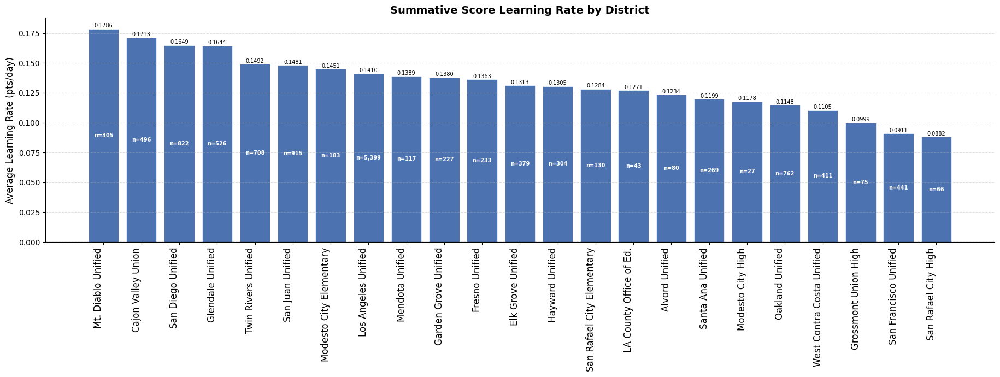

Saved: final_plots/group_gh_slope_by_district.png


In [45]:
fig, ax = plt.subplots(figsize=(max(14, len(dist_names) * 0.8), 7))

colors = ["#4C72B0" if s >= 0 else "#C44E52" for s in slopes]
bars = ax.bar(range(len(dist_names)), slopes, color=colors, edgecolor="white", linewidth=0.5)

# Slope label above/below each bar
for bar, slope in zip(bars, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (0.0002 if slope >= 0 else -0.0002),
        f"{slope:.4f}",
        ha="center", va="bottom" if slope >= 0 else "top", fontsize=7
    )

# Student count inside each bar
for bar, count, slope in zip(bars, counts, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() / 2,
        f"n={count:,}",
        ha="center", va="center",
        fontsize=7, color="white", fontweight="bold"
    )

ax.set_xticks(range(len(dist_names)))
ax.set_xticklabels(dist_names2, rotation=90, ha="right", fontsize=12)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
#ax.set_xlabel("District", fontsize=12)
ax.set_ylabel("Average Learning Rate (pts/day)", fontsize=12)
ax.set_title(f"Summative Score Learning Rate by District", fontsize=14, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(f"final_plots/{group_short}_slope_by_district.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: final_plots/{group_short}_slope_by_district.png")

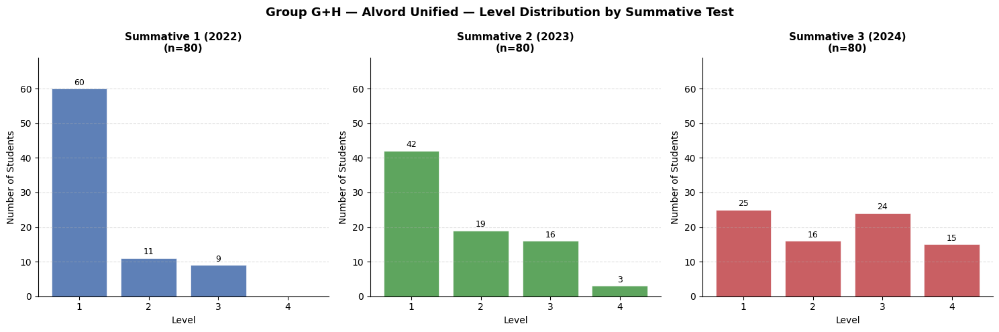

Saved: plots/group_gh_level_distribution_district_3366977_Alvord_Unified.png


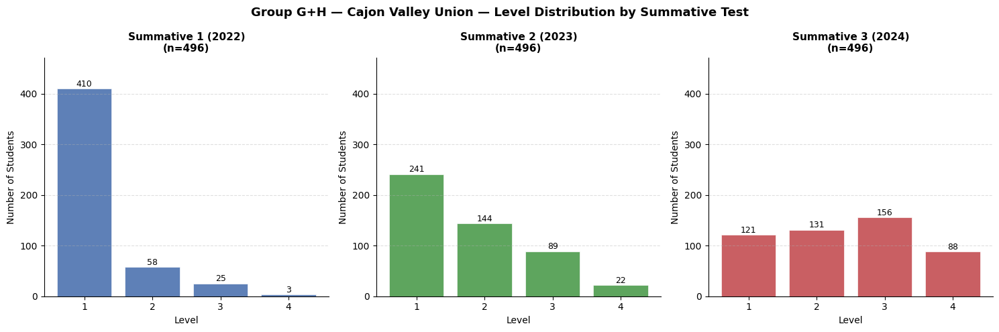

Saved: plots/group_gh_level_distribution_district_3767991_Cajon_Valley_Union.png


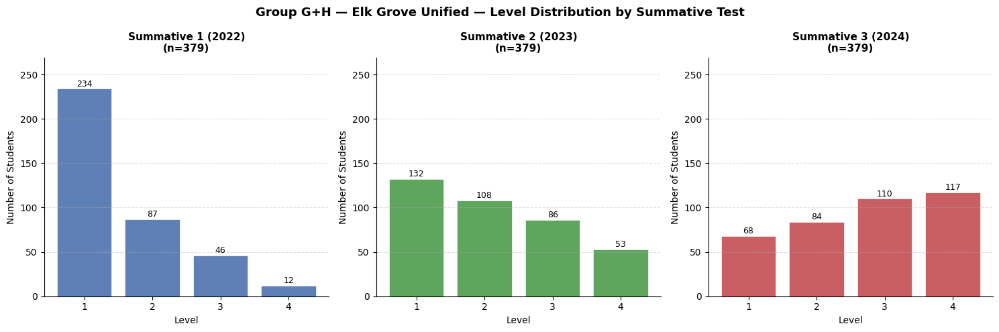

Saved: plots/group_gh_level_distribution_district_3467314_Elk_Grove_Unified.png


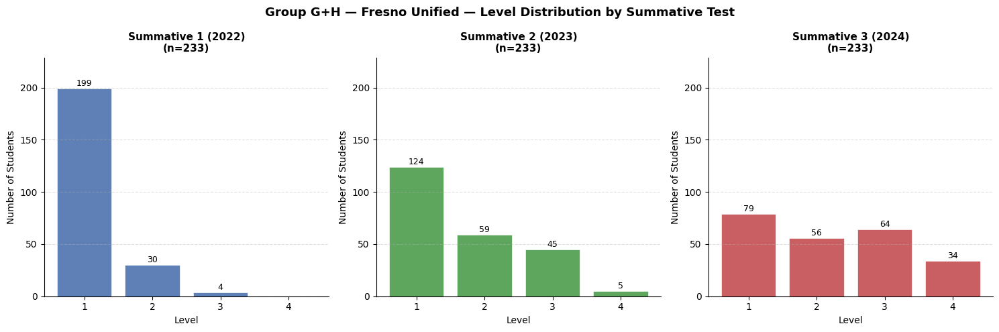

Saved: plots/group_gh_level_distribution_district_1062166_Fresno_Unified.png


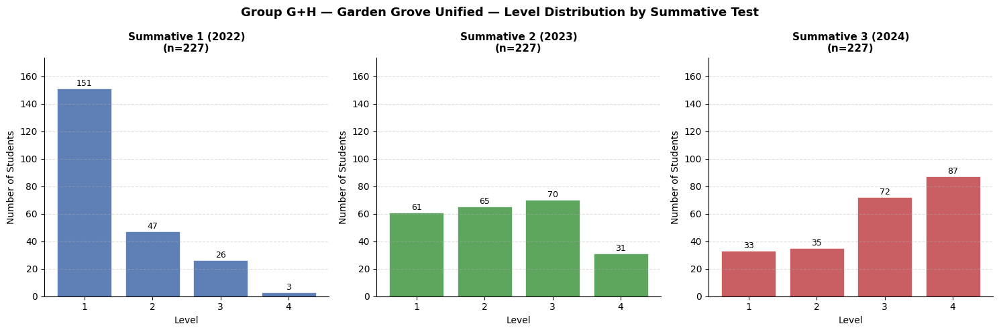

Saved: plots/group_gh_level_distribution_district_3066522_Garden_Grove_Unified.png


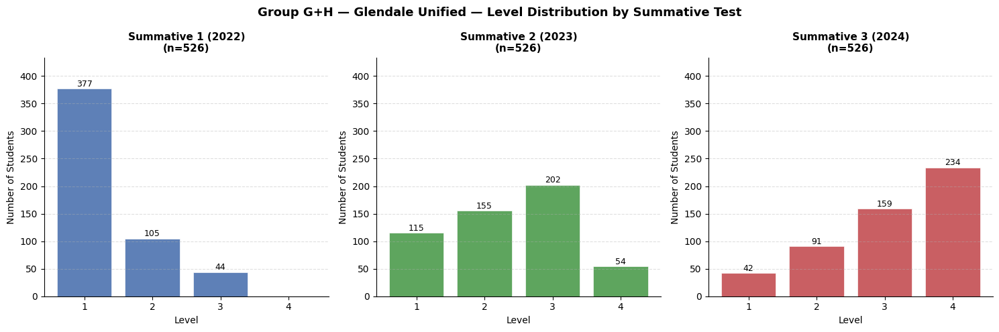

Saved: plots/group_gh_level_distribution_district_1964568_Glendale_Unified.png


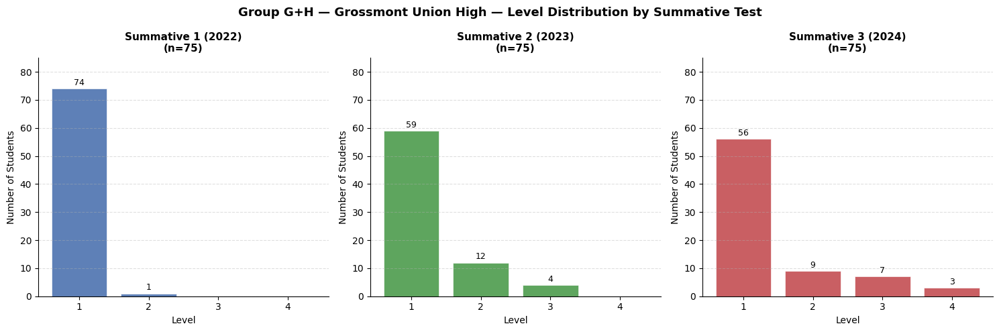

Saved: plots/group_gh_level_distribution_district_3768130_Grossmont_Union_High.png


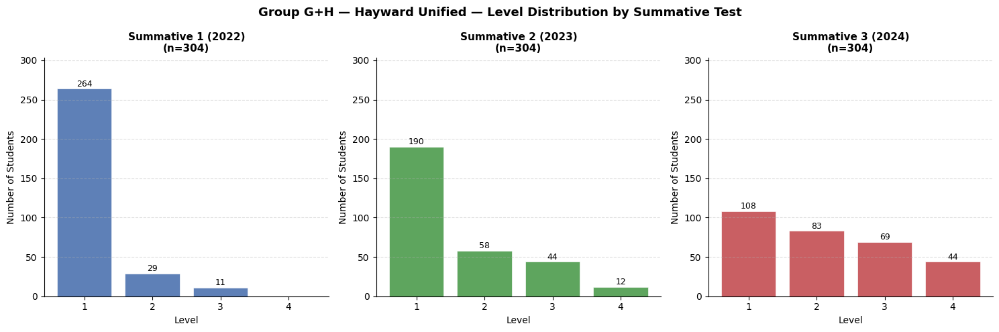

Saved: plots/group_gh_level_distribution_district_161192_Hayward_Unified.png


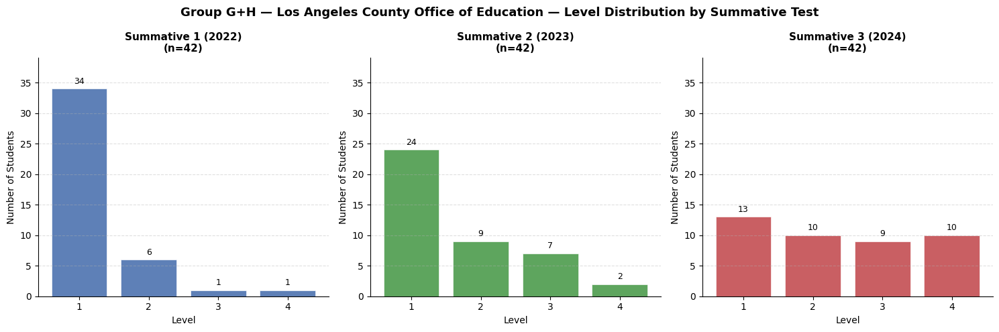

Saved: plots/group_gh_level_distribution_district_1910199_Los_Angeles_County_Office_of_Education.png


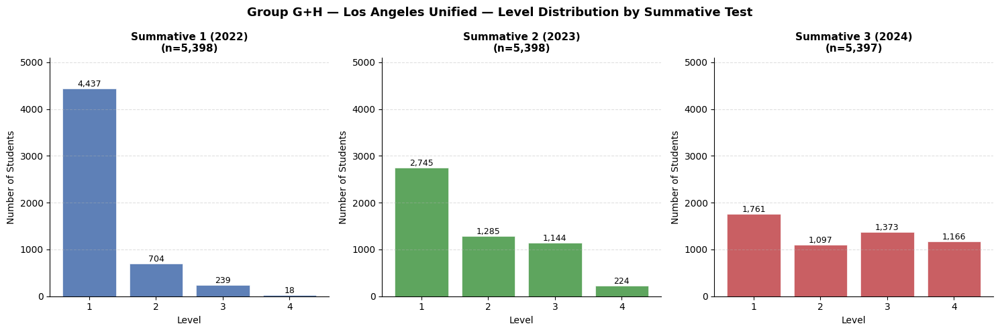

Saved: plots/group_gh_level_distribution_district_1964733_Los_Angeles_Unified.png


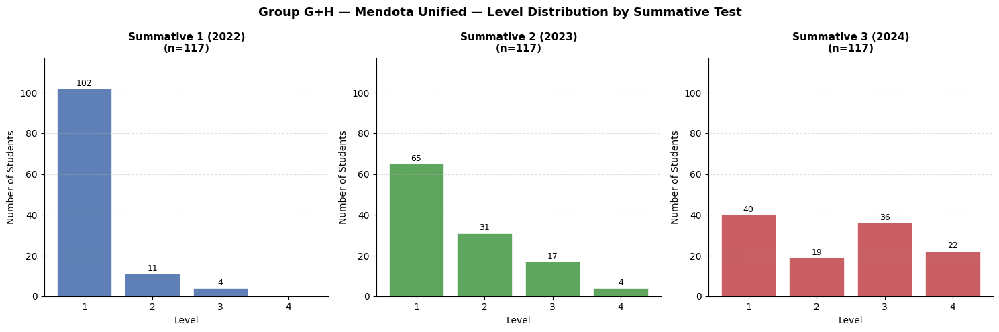

Saved: plots/group_gh_level_distribution_district_1075127_Mendota_Unified.png


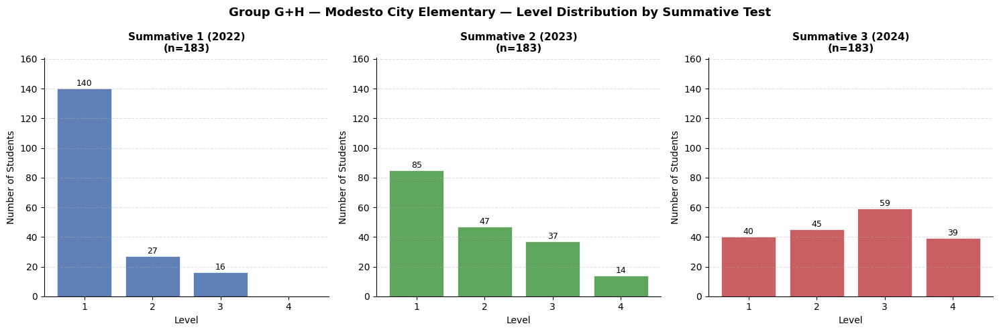

Saved: plots/group_gh_level_distribution_district_5071167_Modesto_City_Elementary.png


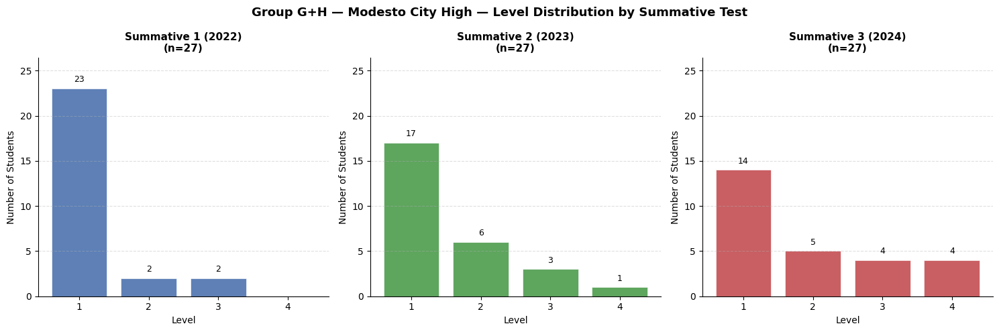

Saved: plots/group_gh_level_distribution_district_5071175_Modesto_City_High.png


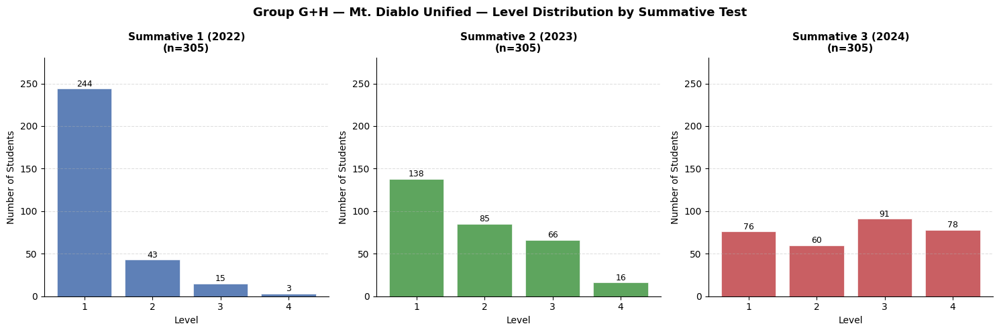

Saved: plots/group_gh_level_distribution_district_761754_Mt._Diablo_Unified.png


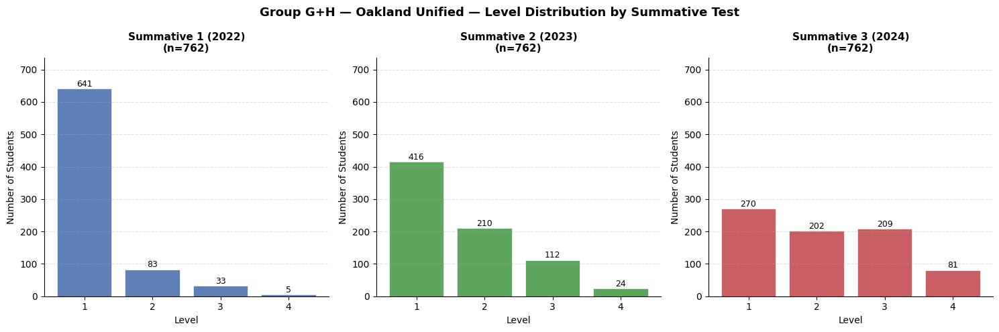

Saved: plots/group_gh_level_distribution_district_161259_Oakland_Unified.png


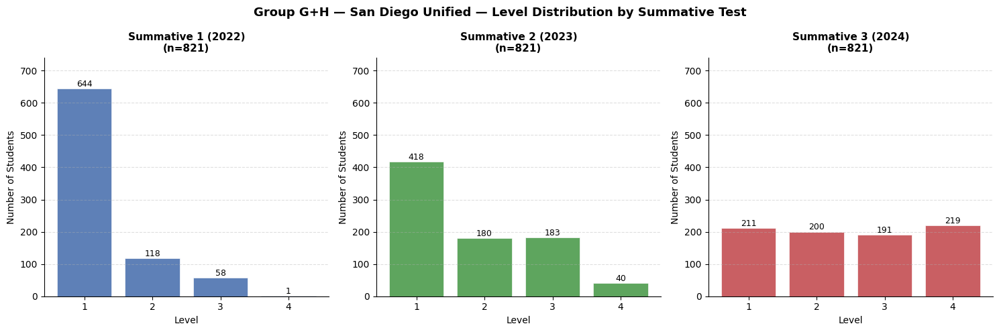

Saved: plots/group_gh_level_distribution_district_3768338_San_Diego_Unified.png


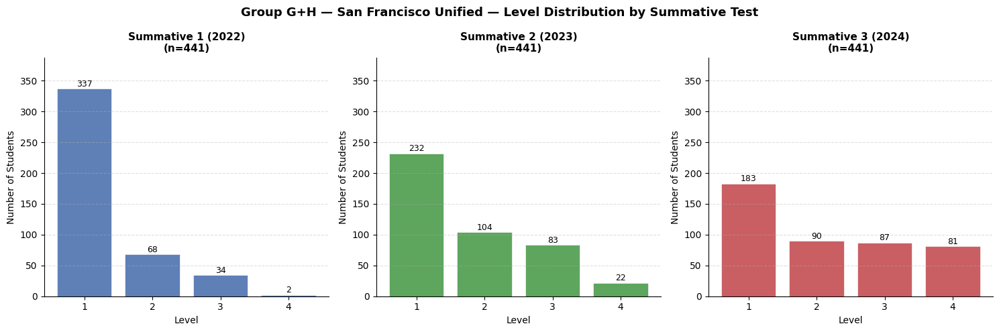

Saved: plots/group_gh_level_distribution_district_3868478_San_Francisco_Unified.png


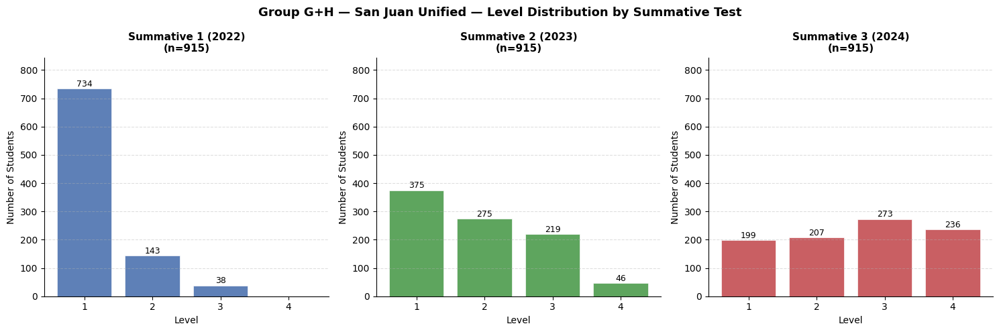

Saved: plots/group_gh_level_distribution_district_3467447_San_Juan_Unified.png


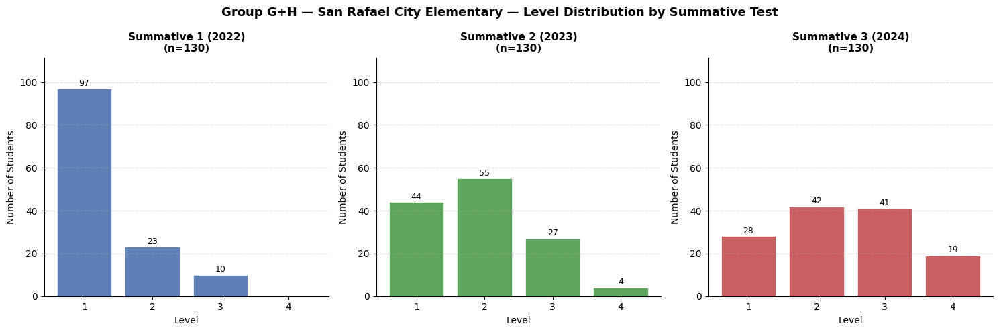

Saved: plots/group_gh_level_distribution_district_2165458_San_Rafael_City_Elementary.png


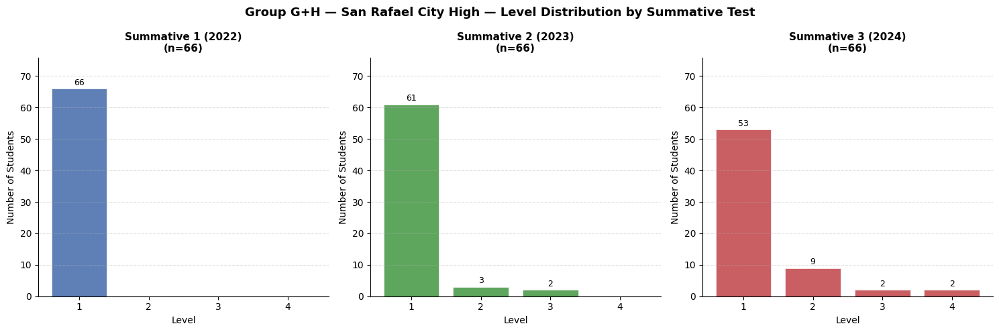

Saved: plots/group_gh_level_distribution_district_2165466_San_Rafael_City_High.png


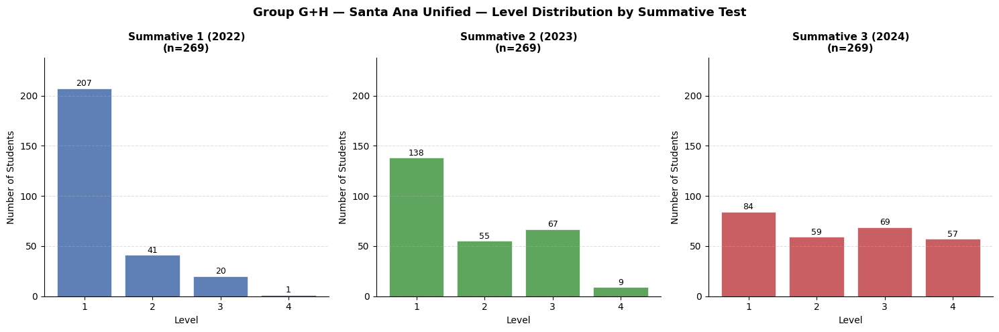

Saved: plots/group_gh_level_distribution_district_3066670_Santa_Ana_Unified.png


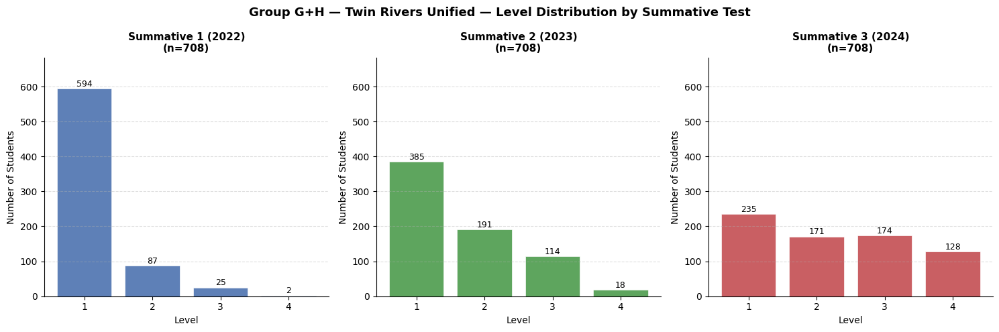

Saved: plots/group_gh_level_distribution_district_3476505_Twin_Rivers_Unified.png


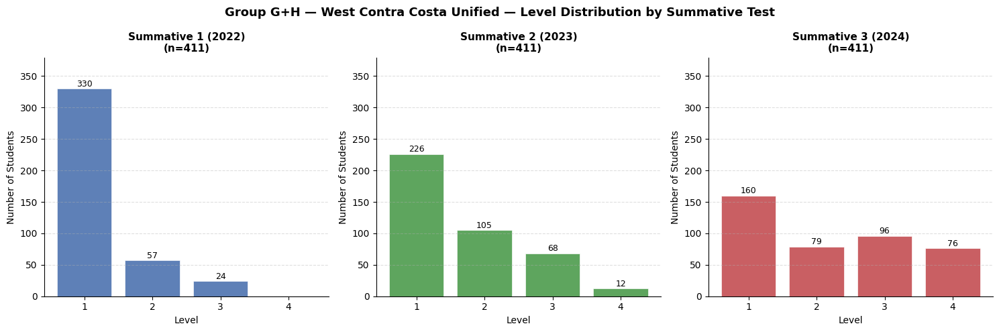

Saved: plots/group_gh_level_distribution_district_761796_West_Contra_Costa_Unified.png


In [15]:
# --- Level distribution per district: 3 subplots with consistent y-axis ---
for _, district_row in districts.iterrows():
    cd_code   = district_row["CDCode"]
    dist_name = district_row["Districtname"]

    dist_data = scored_df[scored_df["CDCode"] == cd_code]
    if len(dist_data) == 0:
        continue

    # Find y-axis max across all 3 tests for this district
    dist_y_max = 0
    for test_num in [1, 2, 3]:
        test_data  = dist_data[dist_data["TestNumber"] == test_num]["Level"].dropna()
        counts     = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        dist_y_max = max(dist_y_max, counts.max())
    dist_y_max = dist_y_max * 1.15

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f"{group_label} — {dist_name} — Level Distribution by Summative Test",
                 fontsize=13, fontweight="bold")

    for ax, (test_num, color) in zip(axes, zip([1, 2, 3], test_colors)):
        test_data = dist_data[dist_data["TestNumber"] == test_num]["Level"].dropna()
        counts    = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        bars      = ax.bar(counts.index, counts.values, color=color,
                           edgecolor="white", linewidth=0.5, alpha=0.9)

        for bar, count in zip(bars, counts.values):
            if count > 0:
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                        f"{count:,}", ha="center", va="bottom", fontsize=9)

        ax.set_ylim(0, dist_y_max)
        ax.set_title(f"Summative {test_num} ({test_years[test_num]})\n(n={len(test_data):,})",
                     fontsize=11, fontweight="bold")
        ax.set_xlabel("Level", fontsize=10)
        ax.set_ylabel("Number of Students", fontsize=10)
        ax.set_xticks([1, 2, 3, 4])
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_name = str(dist_name).replace(" ", "_").replace("/", "_")
    plt.savefig(f"plots/{group_short}_level_distribution_district_{cd_code}_{safe_name}.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_level_distribution_district_{cd_code}_{safe_name}.png")

# Broken out by SEDStatus

In [16]:
# --- Get SED status from 2021-22 enrollment ---
sed_2022 = (
    enrollment_dfs["2021-22"][["SSID", "SocioeconomicallyDisadvantaged"]]
    .dropna()
    .drop_duplicates(subset="SSID", keep="first")
)

# --- Merge into scatter_df and scored_df ---
scatter_df = scatter_df.merge(sed_2022, on="SSID", how="left")
scored_df  = scored_df.merge(sed_2022, on="SSID", how="left")

sed_values = sorted(scatter_df["SocioeconomicallyDisadvantaged"].dropna().unique())
print(f"Unique SED values: {sed_values}")
for val in sed_values:
    n = scatter_df[scatter_df["SocioeconomicallyDisadvantaged"] == val]["SSID"].nunique()
    print(f"  '{val}': {n:,} students")

Unique SED values: ['N', 'Y']
  'N': 3,030 students
  'Y': 9,888 students


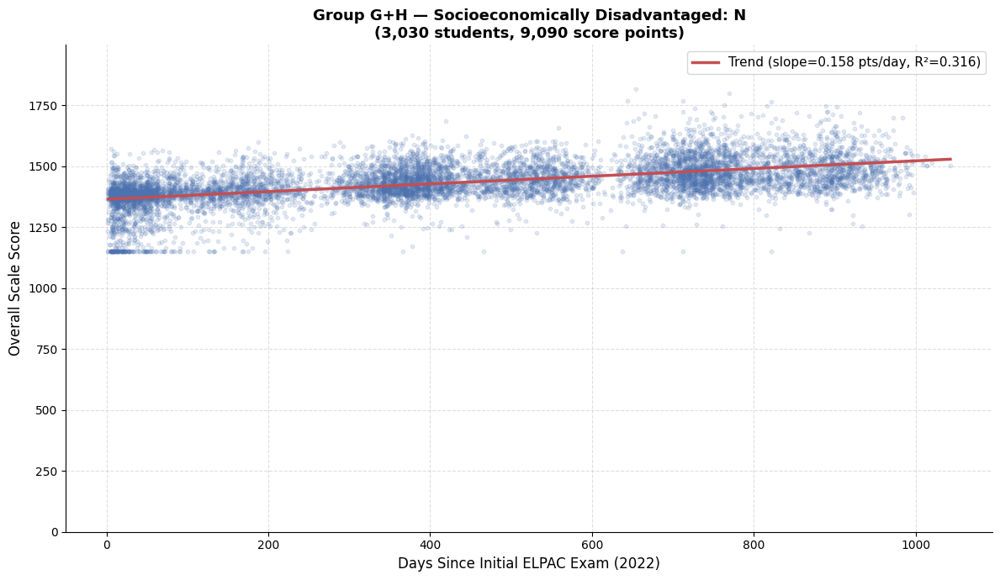

Saved: plots/group_gh_scatter_sed_N.png


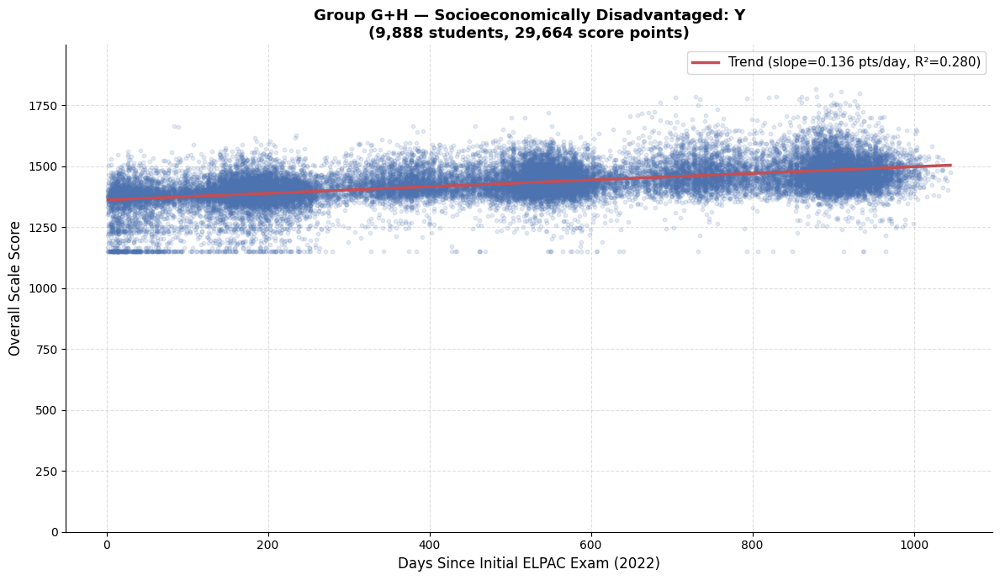

Saved: plots/group_gh_scatter_sed_Y.png


In [17]:
# --- Scatter plot per SED status ---
for sed in sed_values:
    sed_data = scatter_df[
        (scatter_df["SocioeconomicallyDisadvantaged"] == sed) &
        (scatter_df["days"] > 0) &
        (scatter_df["score"] > 1000)
    ]
    x = sed_data["days"].values
    y = sed_data["score"].values

    if len(x) < 2:
        print(f"Skipping SED={sed} — insufficient data ({len(x)} points)")
        continue

    fig, ax = plt.subplots(figsize=(12, 7))
    ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    trend_x   = np.linspace(x.min(), x.max(), 300)
    r_squared = r_value ** 2
    ax.plot(trend_x, slope * trend_x + intercept, color="#C44E52", linewidth=2.5, zorder=3,
            label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

    ax.set_ylim(0, y_max)
    ax.set_xlabel("Days Since Initial ELPAC Exam (2022)", fontsize=12)
    ax.set_ylabel("Overall Scale Score", fontsize=12)
    ax.set_title(f"{group_label} — Socioeconomically Disadvantaged: {sed}\n"
                 f"({sed_data['SSID'].nunique():,} students, {len(x):,} score points)",
                 fontsize=13, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_sed = str(sed).replace(" ", "_")
    plt.savefig(f"plots/{group_short}_scatter_sed_{safe_sed}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_scatter_sed_{safe_sed}.png")

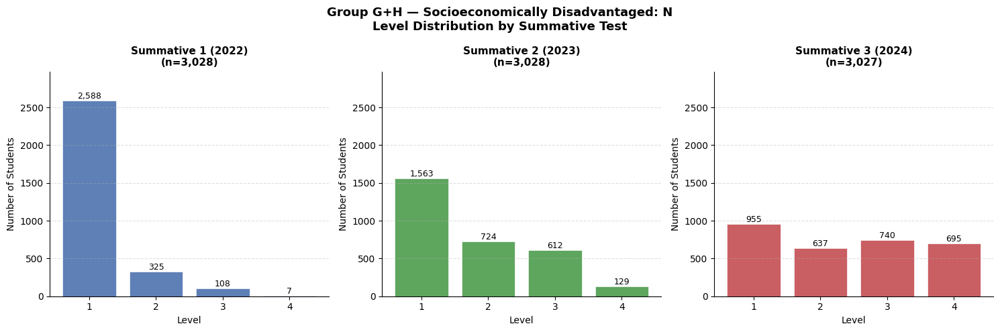

Saved: plots/group_gh_level_distribution_sed_N.png


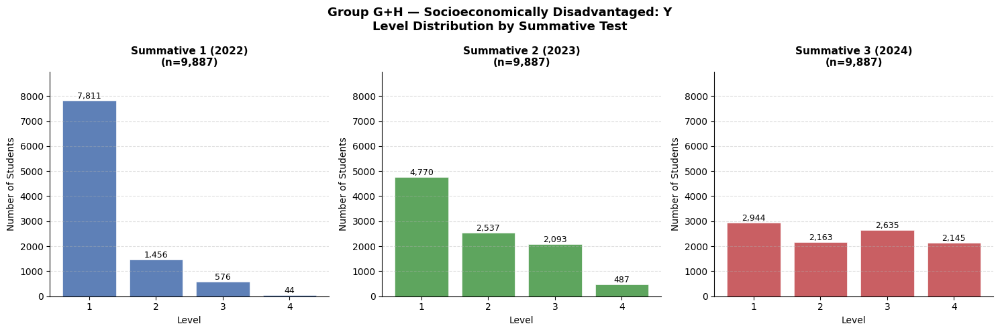

Saved: plots/group_gh_level_distribution_sed_Y.png


In [18]:
# --- Level distribution per SED status: 3 subplots with consistent y-axis ---
for sed in sed_values:
    sed_data = scored_df[scored_df["SocioeconomicallyDisadvantaged"] == sed]
    if len(sed_data) == 0:
        continue

    # Find y-axis max across all 3 tests for this SED value
    sed_y_max = 0
    for test_num in [1, 2, 3]:
        test_data = sed_data[sed_data["TestNumber"] == test_num]["Level"].dropna()
        counts    = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        sed_y_max = max(sed_y_max, counts.max())
    sed_y_max = sed_y_max * 1.15

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f"{group_label} — Socioeconomically Disadvantaged: {sed}\n"
                 f"Level Distribution by Summative Test",
                 fontsize=13, fontweight="bold")

    for ax, (test_num, color) in zip(axes, zip([1, 2, 3], test_colors)):
        test_data = sed_data[sed_data["TestNumber"] == test_num]["Level"].dropna()
        counts    = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        bars      = ax.bar(counts.index, counts.values, color=color,
                           edgecolor="white", linewidth=0.5, alpha=0.9)

        for bar, count in zip(bars, counts.values):
            if count > 0:
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                        f"{count:,}", ha="center", va="bottom", fontsize=9)

        ax.set_ylim(0, sed_y_max)
        ax.set_title(f"Summative {test_num} ({test_years[test_num]})\n(n={len(test_data):,})",
                     fontsize=11, fontweight="bold")
        ax.set_xlabel("Level", fontsize=10)
        ax.set_ylabel("Number of Students", fontsize=10)
        ax.set_xticks([1, 2, 3, 4])
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_sed = str(sed).replace(" ", "_")
    plt.savefig(f"plots/{group_short}_level_distribution_sed_{safe_sed}.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_level_distribution_sed_{safe_sed}.png")

# Broken out by Migrant Status

In [19]:
# --- Get Migrant status from 2021-22 enrollment ---
migrant_2022 = (
    enrollment_dfs["2021-22"][["SSID", "TitleIPartCMigrant"]]
    .dropna()
    .drop_duplicates(subset="SSID", keep="first")
)

# --- Merge into scatter_df and scored_df ---
scatter_df = scatter_df.merge(migrant_2022, on="SSID", how="left")
scored_df  = scored_df.merge(migrant_2022, on="SSID", how="left")

migrant_values = sorted(scatter_df["TitleIPartCMigrant"].dropna().unique())
print(f"Unique Migrant Status values: {migrant_values}")
for val in migrant_values:
    n = scatter_df[scatter_df["TitleIPartCMigrant"] == val]["SSID"].nunique()
    print(f"  '{val}': {n:,} students")

Unique Migrant Status values: ['N', 'Y']
  'N': 12,752 students
  'Y': 166 students


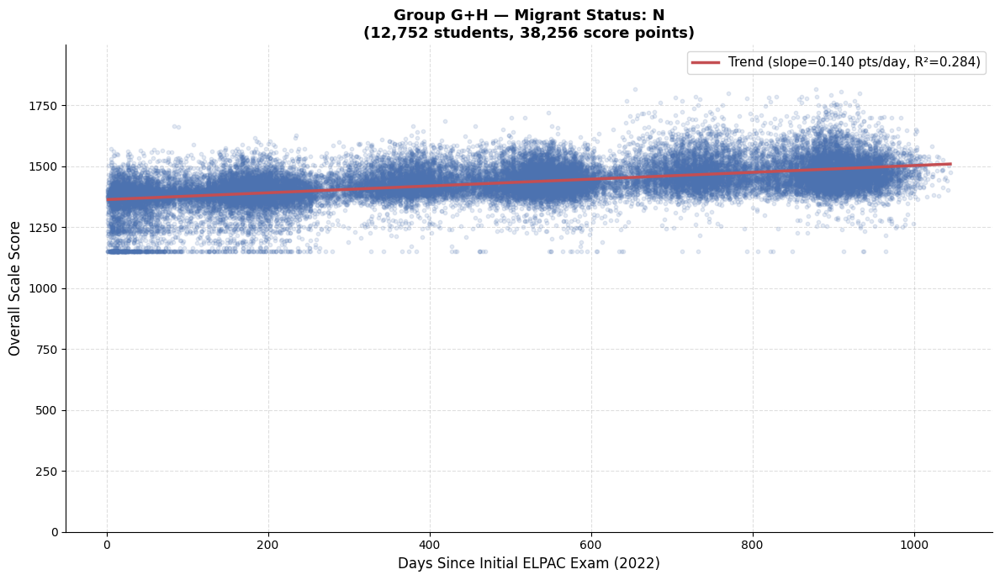

Saved: plots/group_gh_scatter_migrant_N.png


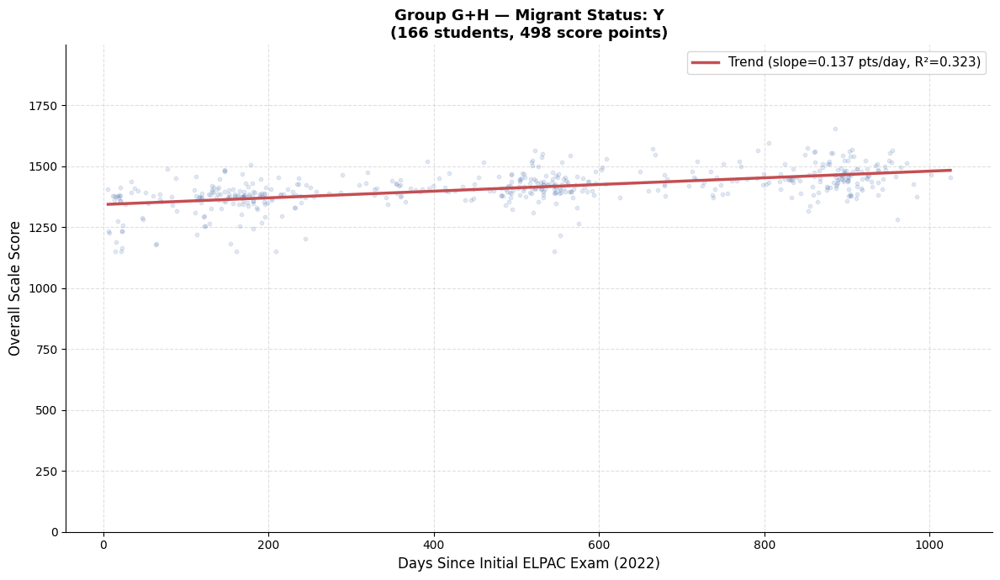

Saved: plots/group_gh_scatter_migrant_Y.png


In [20]:
# --- Scatter plot per Migrant status ---
for migrant in migrant_values:
    migrant_data = scatter_df[
        (scatter_df["TitleIPartCMigrant"] == migrant) &
        (scatter_df["days"] > 0) &
        (scatter_df["score"] > 1000)
    ]
    x = migrant_data["days"].values
    y = migrant_data["score"].values

    if len(x) < 2:
        print(f"Skipping Migrant={migrant} — insufficient data ({len(x)} points)")
        continue

    fig, ax = plt.subplots(figsize=(12, 7))
    ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    trend_x   = np.linspace(x.min(), x.max(), 300)
    r_squared = r_value ** 2
    ax.plot(trend_x, slope * trend_x + intercept, color="#C44E52", linewidth=2.5, zorder=3,
            label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

    ax.set_ylim(0, y_max)
    ax.set_xlabel("Days Since Initial ELPAC Exam (2022)", fontsize=12)
    ax.set_ylabel("Overall Scale Score", fontsize=12)
    ax.set_title(f"{group_label} — Migrant Status: {migrant}\n"
                 f"({migrant_data['SSID'].nunique():,} students, {len(x):,} score points)",
                 fontsize=13, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_migrant = str(migrant).replace(" ", "_")
    plt.savefig(f"plots/{group_short}_scatter_migrant_{safe_migrant}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_scatter_migrant_{safe_migrant}.png")

# Break out by ParentGuardianHighestEducationLevelCode

In [21]:
# --- Get Parent Education Level from 2021-22 enrollment ---
edu_2022 = (
    enrollment_dfs["2021-22"][["SSID", "ParentGuardianHighestEducationLevelCode"]]
    .dropna()
    .drop_duplicates(subset="SSID", keep="first")
)

# --- Merge into scatter_df and scored_df ---
scatter_df = scatter_df.merge(edu_2022, on="SSID", how="left")
scored_df  = scored_df.merge(edu_2022, on="SSID", how="left")

edu_values = sorted(scatter_df["ParentGuardianHighestEducationLevelCode"].dropna().unique())
print(f"Unique Parent Education Level values: {edu_values}")
for val in edu_values:
    n = scatter_df[scatter_df["ParentGuardianHighestEducationLevelCode"] == val]["SSID"].nunique()
    print(f"  '{val}': {n:,} students")

Unique Parent Education Level values: [np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0)]
  '10.0': 802 students
  '11.0': 1,169 students
  '12.0': 689 students
  '13.0': 2,597 students
  '14.0': 2,872 students
  '15.0': 4,733 students


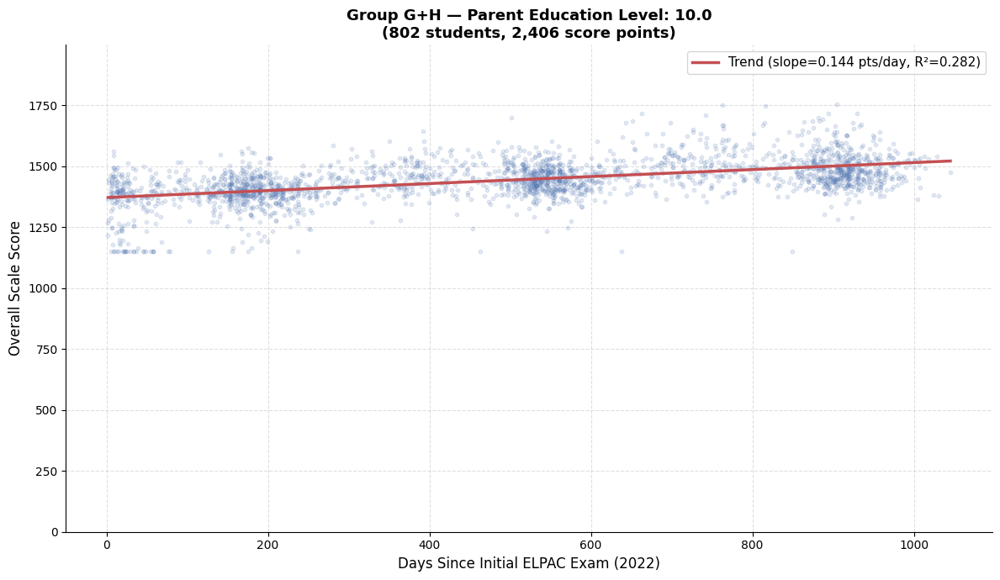

Saved: plots/group_gh_scatter_edu_10.0.png


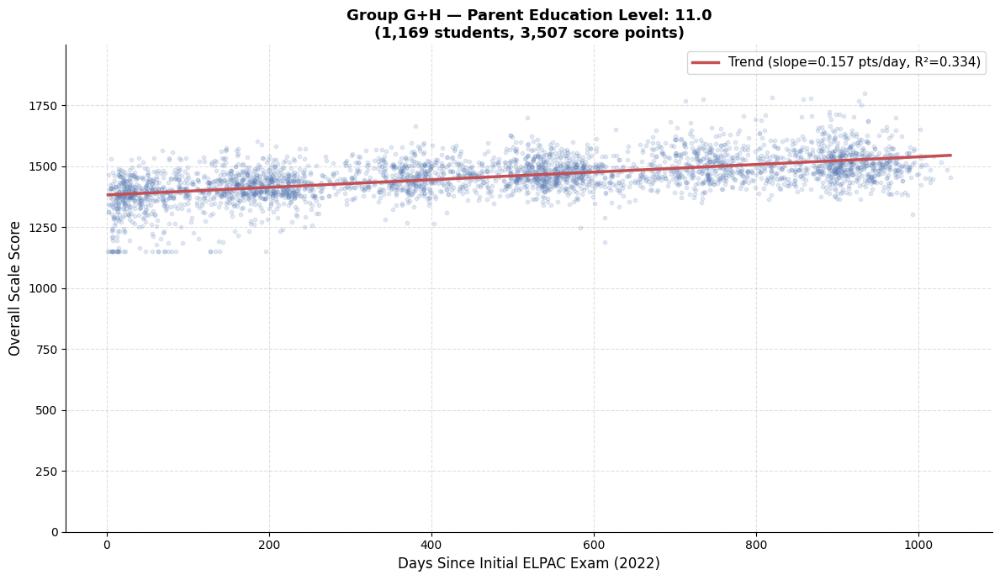

Saved: plots/group_gh_scatter_edu_11.0.png


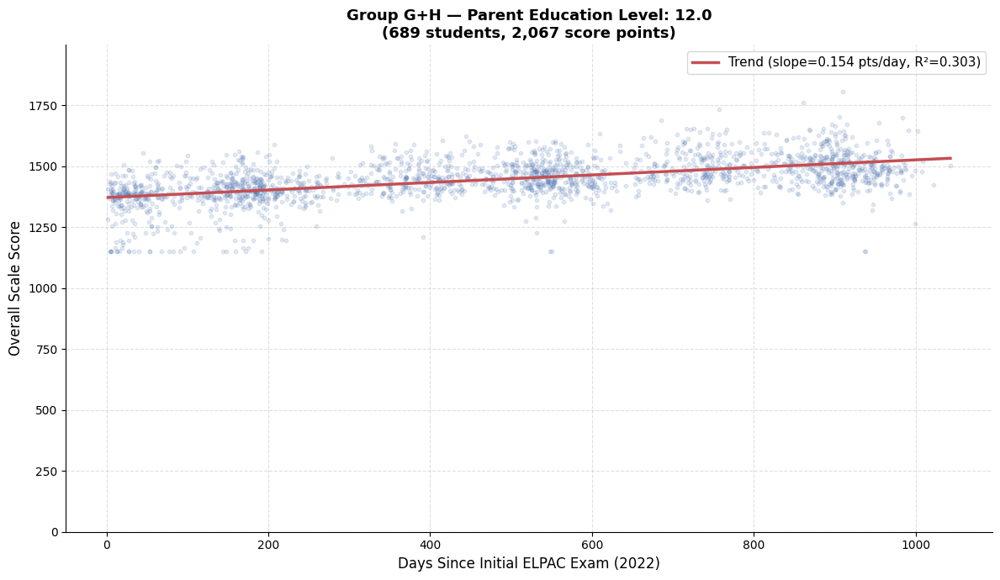

Saved: plots/group_gh_scatter_edu_12.0.png


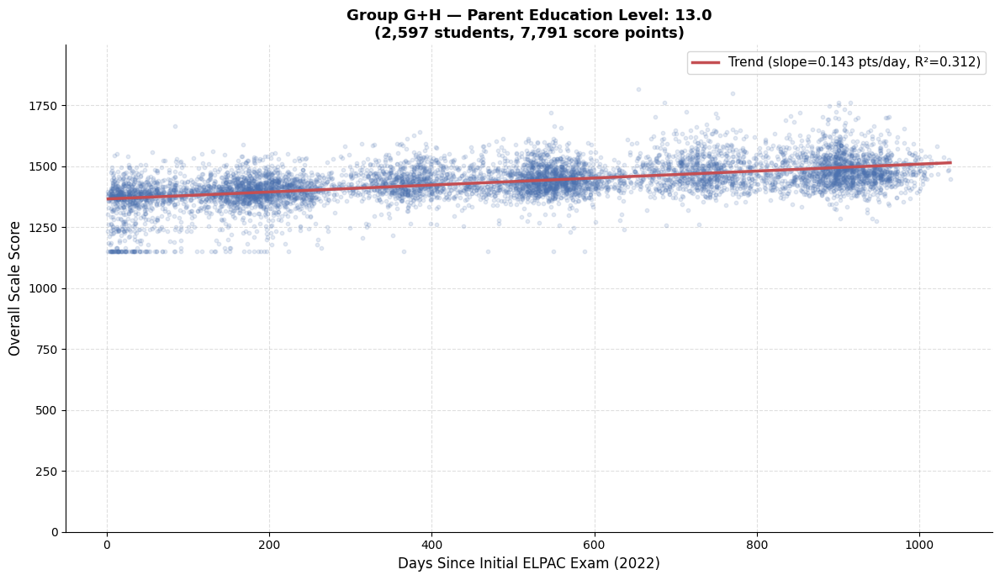

Saved: plots/group_gh_scatter_edu_13.0.png


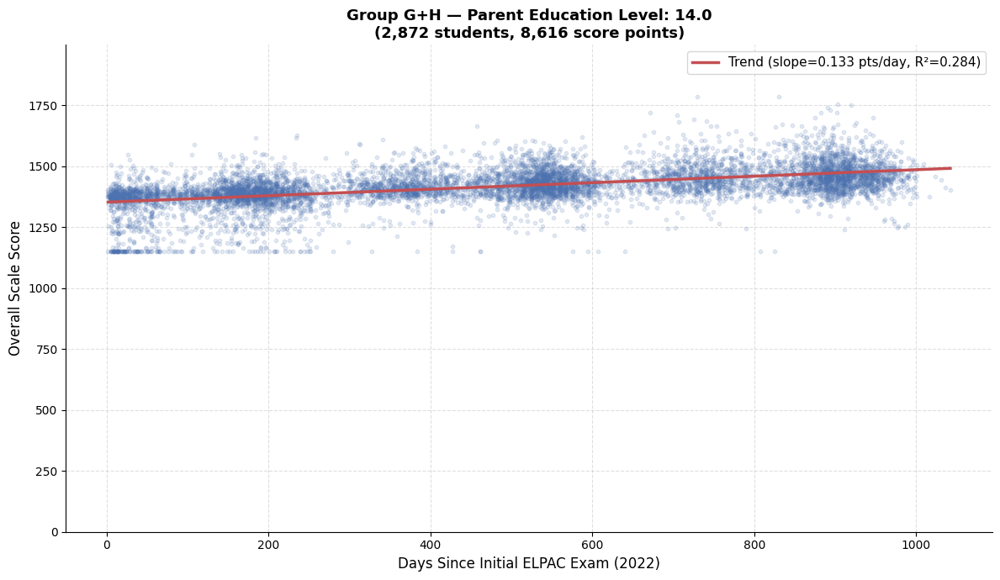

Saved: plots/group_gh_scatter_edu_14.0.png


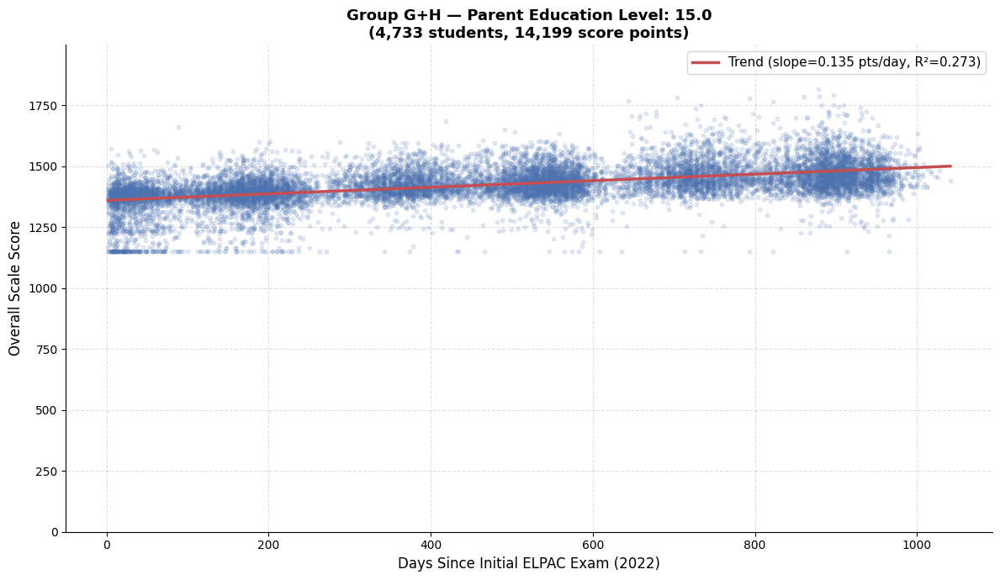

Saved: plots/group_gh_scatter_edu_15.0.png


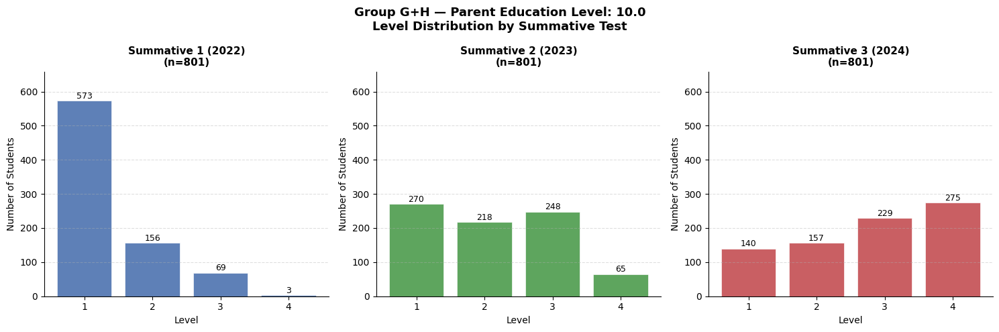

Saved: plots/group_gh_level_distribution_edu_10.0.png


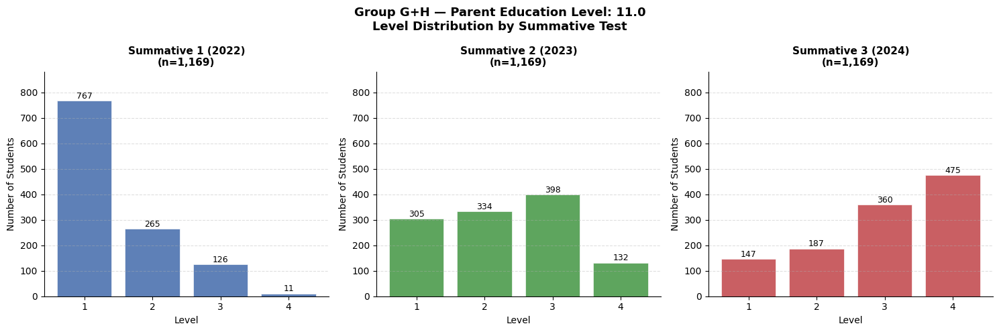

Saved: plots/group_gh_level_distribution_edu_11.0.png


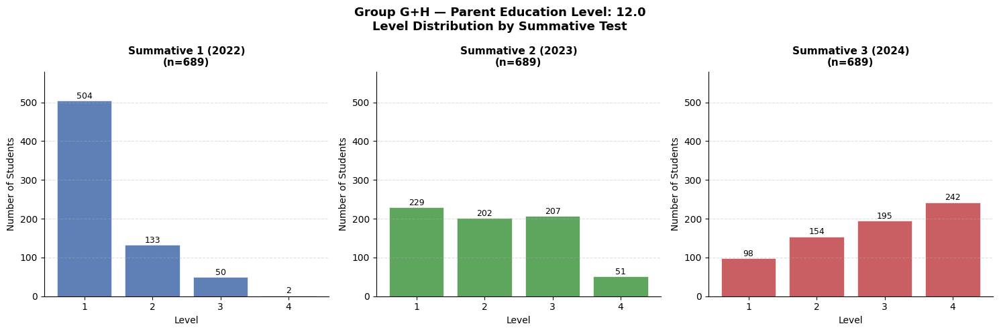

Saved: plots/group_gh_level_distribution_edu_12.0.png


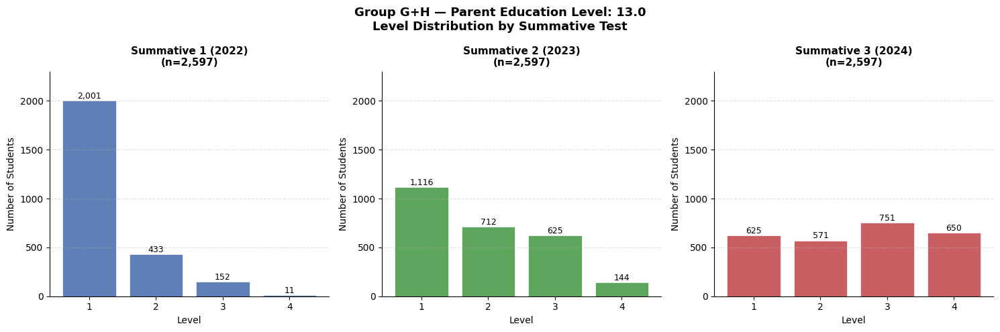

Saved: plots/group_gh_level_distribution_edu_13.0.png


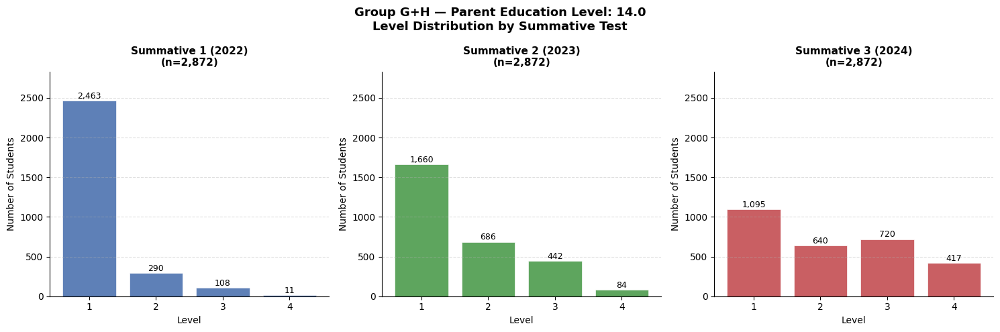

Saved: plots/group_gh_level_distribution_edu_14.0.png


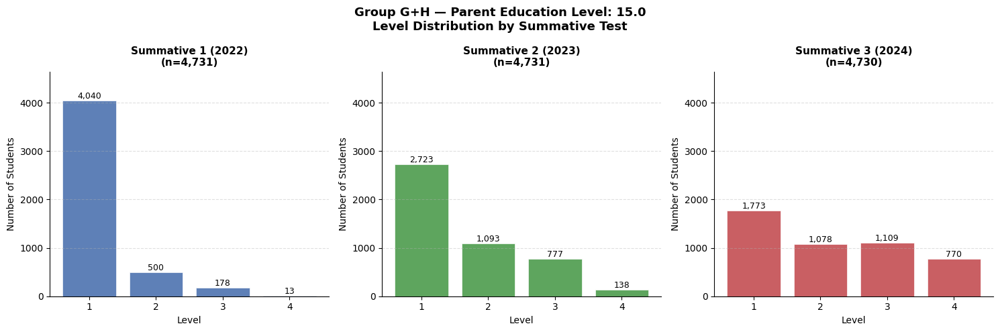

Saved: plots/group_gh_level_distribution_edu_15.0.png


In [22]:
# --- Scatter plot per Parent Education Level ---
for edu in edu_values:
    edu_data = scatter_df[
        (scatter_df["ParentGuardianHighestEducationLevelCode"] == edu) &
        (scatter_df["days"] > 0) &
        (scatter_df["score"] > 1000)
    ]
    x = edu_data["days"].values
    y = edu_data["score"].values

    if len(x) < 2:
        print(f"Skipping Education Level={edu} — insufficient data ({len(x)} points)")
        continue

    fig, ax = plt.subplots(figsize=(12, 7))
    ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    trend_x   = np.linspace(x.min(), x.max(), 300)
    r_squared = r_value ** 2
    ax.plot(trend_x, slope * trend_x + intercept, color="#C44E52", linewidth=2.5, zorder=3,
            label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

    ax.set_ylim(0, y_max)
    ax.set_xlabel("Days Since Initial ELPAC Exam (2022)", fontsize=12)
    ax.set_ylabel("Overall Scale Score", fontsize=12)
    ax.set_title(f"{group_label} — Parent Education Level: {edu}\n"
                 f"({edu_data['SSID'].nunique():,} students, {len(x):,} score points)",
                 fontsize=13, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_edu = str(edu).replace(" ", "_").replace("/", "_")
    plt.savefig(f"plots/{group_short}_scatter_edu_{safe_edu}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_scatter_edu_{safe_edu}.png")# --- Level distribution per Parent Education Level: 3 subplots with consistent y-axis ---
for edu in edu_values:
    edu_data = scored_df[scored_df["ParentGuardianHighestEducationLevelCode"] == edu]
    if len(edu_data) == 0:
        continue

    # Find y-axis max across all 3 tests for this education level
    edu_y_max = 0
    for test_num in [1, 2, 3]:
        test_data = edu_data[edu_data["TestNumber"] == test_num]["Level"].dropna()
        counts    = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        edu_y_max = max(edu_y_max, counts.max())
    edu_y_max = edu_y_max * 1.15

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f"{group_label} — Parent Education Level: {edu}\n"
                 f"Level Distribution by Summative Test",
                 fontsize=13, fontweight="bold")

    for ax, (test_num, color) in zip(axes, zip([1, 2, 3], test_colors)):
        test_data = edu_data[edu_data["TestNumber"] == test_num]["Level"].dropna()
        counts    = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        bars      = ax.bar(counts.index, counts.values, color=color,
                           edgecolor="white", linewidth=0.5, alpha=0.9)

        for bar, count in zip(bars, counts.values):
            if count > 0:
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                        f"{count:,}", ha="center", va="bottom", fontsize=9)

        ax.set_ylim(0, edu_y_max)
        ax.set_title(f"Summative {test_num} ({test_years[test_num]})\n(n={len(test_data):,})",
                     fontsize=11, fontweight="bold")
        ax.set_xlabel("Level", fontsize=10)
        ax.set_ylabel("Number of Students", fontsize=10)
        ax.set_xticks([1, 2, 3, 4])
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_edu = str(edu).replace(" ", "_").replace("/", "_")
    plt.savefig(f"plots/{group_short}_level_distribution_edu_{safe_edu}.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_level_distribution_edu_{safe_edu}.png")

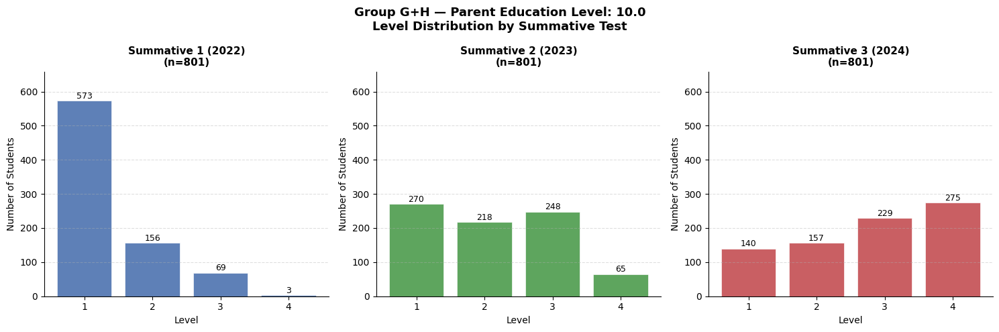

Saved: plots/group_gh_level_distribution_edu_10.0.png


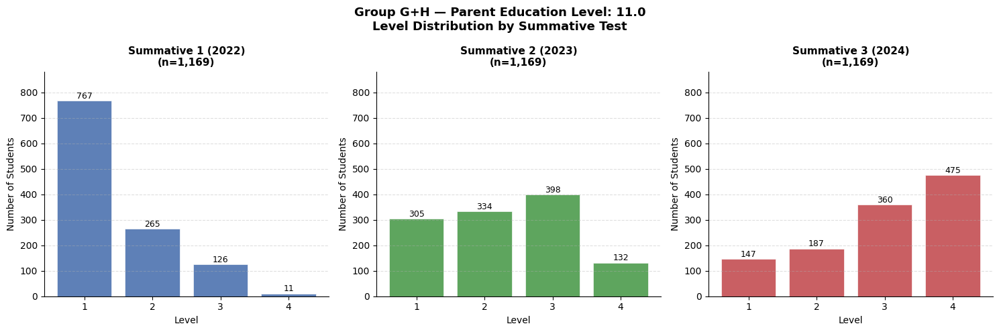

Saved: plots/group_gh_level_distribution_edu_11.0.png


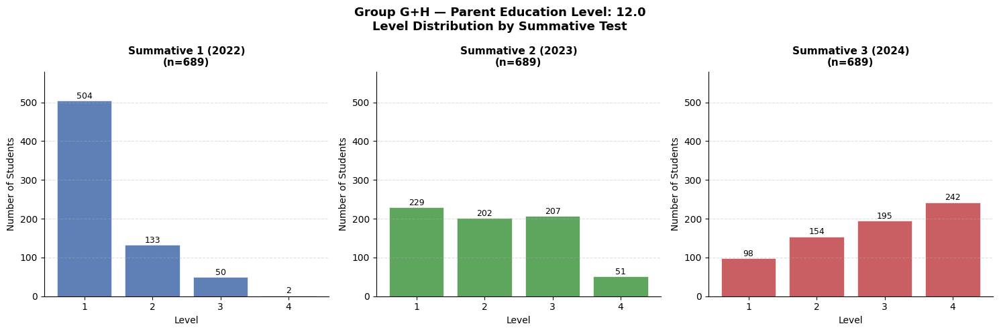

Saved: plots/group_gh_level_distribution_edu_12.0.png


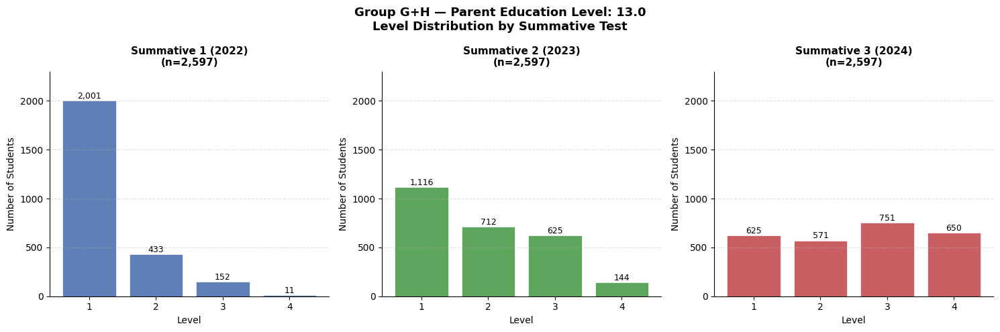

Saved: plots/group_gh_level_distribution_edu_13.0.png


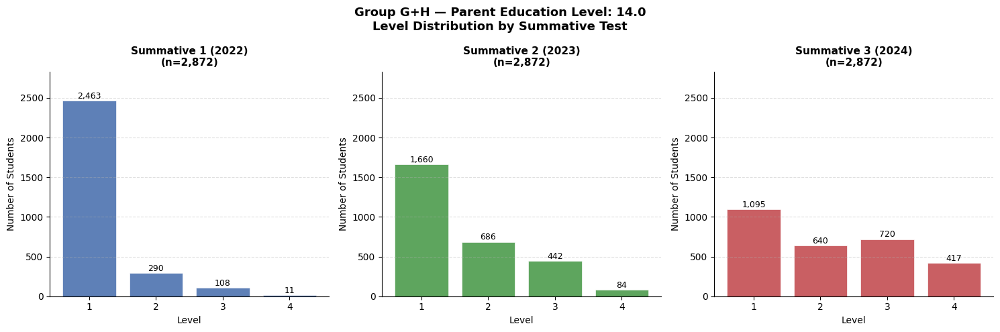

Saved: plots/group_gh_level_distribution_edu_14.0.png


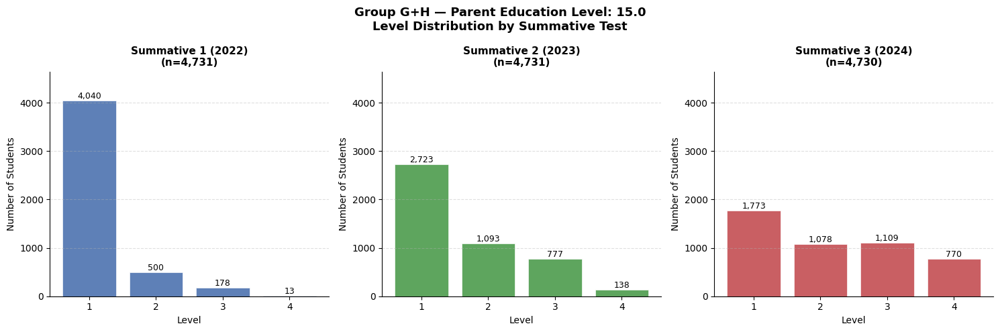

Saved: plots/group_gh_level_distribution_edu_15.0.png


In [23]:
# --- Level distribution per Parent Education Level: 3 subplots with consistent y-axis ---
for edu in edu_values:
    edu_data = scored_df[scored_df["ParentGuardianHighestEducationLevelCode"] == edu]
    if len(edu_data) == 0:
        continue

    # Find y-axis max across all 3 tests for this education level
    edu_y_max = 0
    for test_num in [1, 2, 3]:
        test_data = edu_data[edu_data["TestNumber"] == test_num]["Level"].dropna()
        counts    = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        edu_y_max = max(edu_y_max, counts.max())
    edu_y_max = edu_y_max * 1.15

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f"{group_label} — Parent Education Level: {edu}\n"
                 f"Level Distribution by Summative Test",
                 fontsize=13, fontweight="bold")

    for ax, (test_num, color) in zip(axes, zip([1, 2, 3], test_colors)):
        test_data = edu_data[edu_data["TestNumber"] == test_num]["Level"].dropna()
        counts    = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        bars      = ax.bar(counts.index, counts.values, color=color,
                           edgecolor="white", linewidth=0.5, alpha=0.9)

        for bar, count in zip(bars, counts.values):
            if count > 0:
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                        f"{count:,}", ha="center", va="bottom", fontsize=9)

        ax.set_ylim(0, edu_y_max)
        ax.set_title(f"Summative {test_num} ({test_years[test_num]})\n(n={len(test_data):,})",
                     fontsize=11, fontweight="bold")
        ax.set_xlabel("Level", fontsize=10)
        ax.set_ylabel("Number of Students", fontsize=10)
        ax.set_xticks([1, 2, 3, 4])
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_edu = str(edu).replace(" ", "_").replace("/", "_")
    plt.savefig(f"plots/{group_short}_level_distribution_edu_{safe_edu}.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_level_distribution_edu_{safe_edu}.png")

# Break out by Primary Language (Spanish vs. non-spanish)

In [24]:
# --- Get Primary Language from 2021-22 enrollment ---
lang_2022 = (
    enrollment_dfs["2021-22"][["SSID", "PrimaryLanguageCode"]]
    .dropna()
    .drop_duplicates(subset="SSID", keep="first")
)

# --- Merge into scatter_df and scored_df ---
scatter_df = scatter_df.merge(lang_2022, on="SSID", how="left")
scored_df  = scored_df.merge(lang_2022, on="SSID", how="left")

# --- Map to Spanish / Non-Spanish ---
scatter_df["LanguageGroup"] = scatter_df["PrimaryLanguageCode"].apply(
    lambda x: "Spanish" if str(x).strip() == "01" else "Non-Spanish"
)
scored_df["LanguageGroup"] = scored_df["PrimaryLanguageCode"].apply(
    lambda x: "Spanish" if str(x).strip() == "01" else "Non-Spanish"
)

lang_values = ["Spanish", "Non-Spanish"]
print("Language group counts:")
for val in lang_values:
    n = scatter_df[scatter_df["LanguageGroup"] == val]["SSID"].nunique()
    print(f"  {val}: {n:,} students")

Language group counts:
  Spanish: 7,859 students
  Non-Spanish: 5,059 students


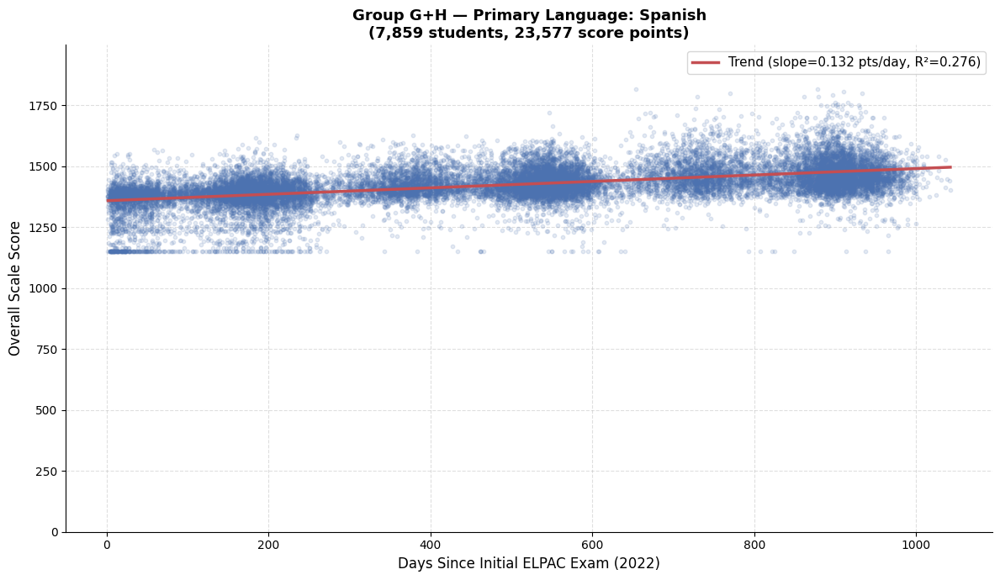

Saved: plots/group_gh_scatter_lang_spanish.png


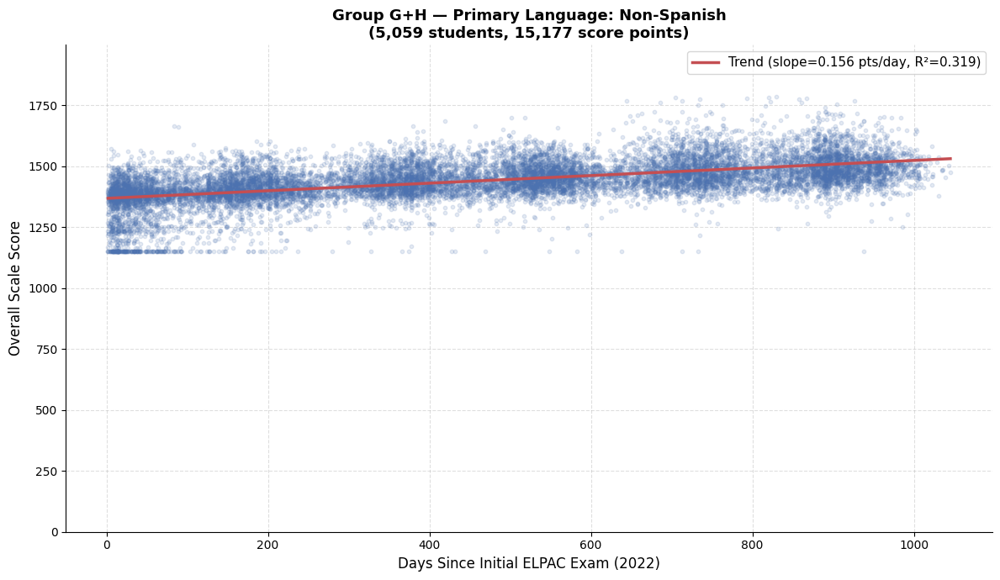

Saved: plots/group_gh_scatter_lang_non_spanish.png


In [25]:
# --- Scatter plot per Language Group ---
for lang in lang_values:
    lang_data = scatter_df[
        (scatter_df["LanguageGroup"] == lang) &
        (scatter_df["days"] > 0) &
        (scatter_df["score"] > 1000)
    ]
    x = lang_data["days"].values
    y = lang_data["score"].values

    if len(x) < 2:
        print(f"Skipping {lang} — insufficient data ({len(x)} points)")
        continue

    fig, ax = plt.subplots(figsize=(12, 7))
    ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    trend_x   = np.linspace(x.min(), x.max(), 300)
    r_squared = r_value ** 2
    ax.plot(trend_x, slope * trend_x + intercept, color="#C44E52", linewidth=2.5, zorder=3,
            label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

    ax.set_ylim(0, y_max)
    ax.set_xlabel("Days Since Initial ELPAC Exam (2022)", fontsize=12)
    ax.set_ylabel("Overall Scale Score", fontsize=12)
    ax.set_title(f"{group_label} — Primary Language: {lang}\n"
                 f"({lang_data['SSID'].nunique():,} students, {len(x):,} score points)",
                 fontsize=13, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_lang = lang.lower().replace("-", "_")
    plt.savefig(f"plots/{group_short}_scatter_lang_{safe_lang}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_scatter_lang_{safe_lang}.png")

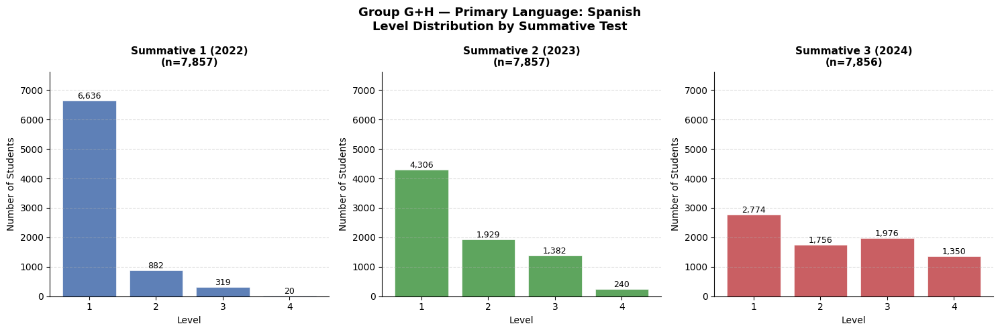

Saved: plots/group_gh_level_distribution_lang_spanish.png


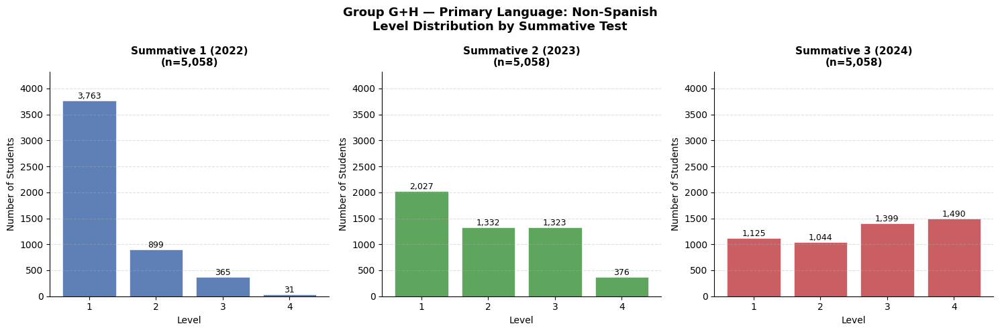

Saved: plots/group_gh_level_distribution_lang_non_spanish.png


In [26]:
# --- Level distribution per Language Group: 3 subplots with consistent y-axis ---
for lang in lang_values:
    lang_data = scored_df[scored_df["LanguageGroup"] == lang]
    if len(lang_data) == 0:
        continue

    # Find y-axis max across all 3 tests for this language group
    lang_y_max = 0
    for test_num in [1, 2, 3]:
        test_data  = lang_data[lang_data["TestNumber"] == test_num]["Level"].dropna()
        counts     = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        lang_y_max = max(lang_y_max, counts.max())
    lang_y_max = lang_y_max * 1.15

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f"{group_label} — Primary Language: {lang}\n"
                 f"Level Distribution by Summative Test",
                 fontsize=13, fontweight="bold")

    for ax, (test_num, color) in zip(axes, zip([1, 2, 3], test_colors)):
        test_data = lang_data[lang_data["TestNumber"] == test_num]["Level"].dropna()
        counts    = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        bars      = ax.bar(counts.index, counts.values, color=color,
                           edgecolor="white", linewidth=0.5, alpha=0.9)

        for bar, count in zip(bars, counts.values):
            if count > 0:
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                        f"{count:,}", ha="center", va="bottom", fontsize=9)

        ax.set_ylim(0, lang_y_max)
        ax.set_title(f"Summative {test_num} ({test_years[test_num]})\n(n={len(test_data):,})",
                     fontsize=11, fontweight="bold")
        ax.set_xlabel("Level", fontsize=10)
        ax.set_ylabel("Number of Students", fontsize=10)
        ax.set_xticks([1, 2, 3, 4])
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_lang = lang.lower().replace("-", "_")
    plt.savefig(f"plots/{group_short}_level_distribution_lang_{safe_lang}.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_level_distribution_lang_{safe_lang}.png")

# Broken out by Gender

In [27]:
# --- Get Gender from 2021-22 enrollment ---
gender_2022 = (
    enrollment_dfs["2021-22"][["SSID", "StudentGenderCode"]]
    .dropna()
    .drop_duplicates(subset="SSID", keep="first")
)

# --- Merge into scatter_df and scored_df ---
scatter_df = scatter_df.merge(gender_2022, on="SSID", how="left")
scored_df  = scored_df.merge(gender_2022, on="SSID", how="left")

gender_values = sorted(scatter_df["StudentGenderCode"].dropna().unique())
print(f"Unique Gender values: {gender_values}")
for val in gender_values:
    n = scatter_df[scatter_df["StudentGenderCode"] == val]["SSID"].nunique()
    print(f"  '{val}': {n:,} students")

Unique Gender values: ['F', 'M', 'X']
  'F': 6,021 students
  'M': 6,896 students
  'X': 1 students


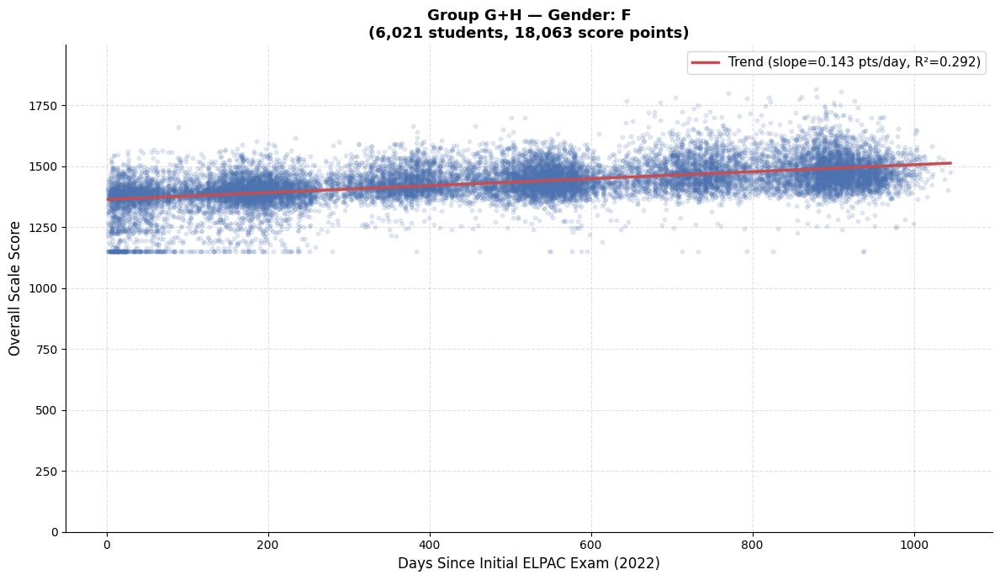

Saved: plots/group_gh_scatter_gender_F.png


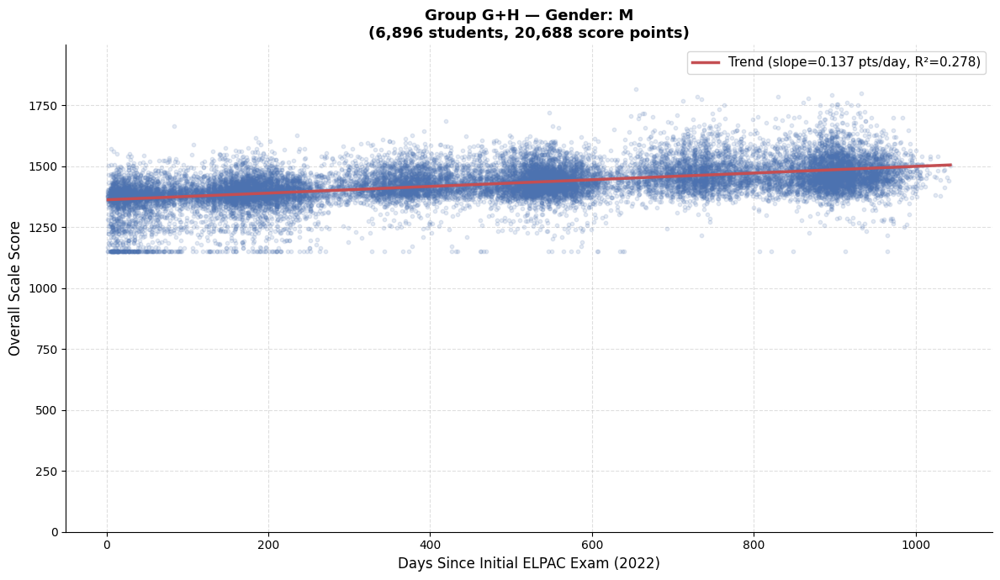

Saved: plots/group_gh_scatter_gender_M.png


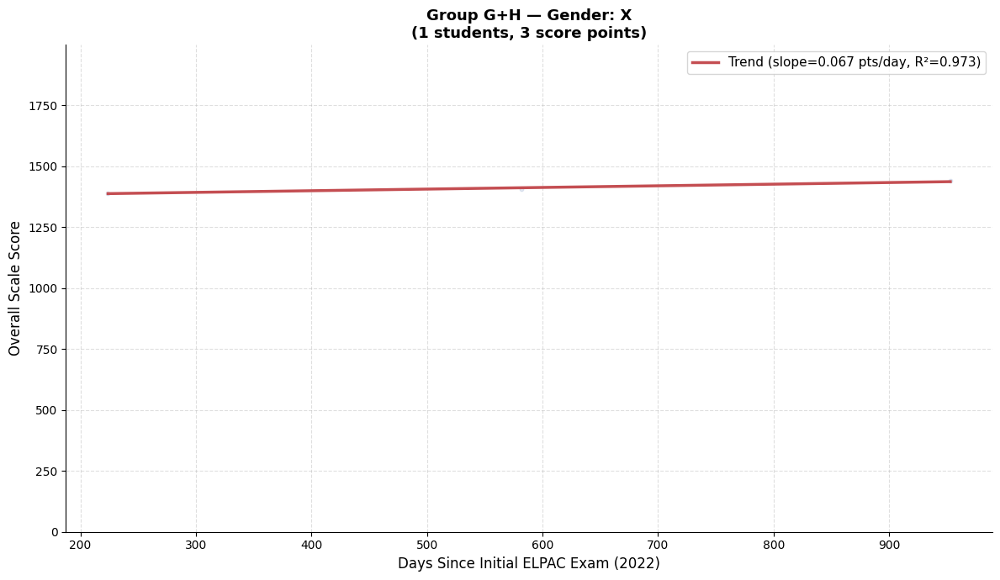

Saved: plots/group_gh_scatter_gender_X.png


In [28]:
# --- Scatter plot per Gender ---
for gender in gender_values:
    gender_data = scatter_df[
        (scatter_df["StudentGenderCode"] == gender) &
        (scatter_df["days"] > 0) &
        (scatter_df["score"] > 1000)
    ]
    x = gender_data["days"].values
    y = gender_data["score"].values

    if len(x) < 2:
        print(f"Skipping Gender={gender} — insufficient data ({len(x)} points)")
        continue

    fig, ax = plt.subplots(figsize=(12, 7))
    ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    trend_x   = np.linspace(x.min(), x.max(), 300)
    r_squared = r_value ** 2
    ax.plot(trend_x, slope * trend_x + intercept, color="#C44E52", linewidth=2.5, zorder=3,
            label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

    ax.set_ylim(0, y_max)
    ax.set_xlabel("Days Since Initial ELPAC Exam (2022)", fontsize=12)
    ax.set_ylabel("Overall Scale Score", fontsize=12)
    ax.set_title(f"{group_label} — Gender: {gender}\n"
                 f"({gender_data['SSID'].nunique():,} students, {len(x):,} score points)",
                 fontsize=13, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_gender = str(gender).replace(" ", "_")
    plt.savefig(f"plots/{group_short}_scatter_gender_{safe_gender}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_scatter_gender_{safe_gender}.png")

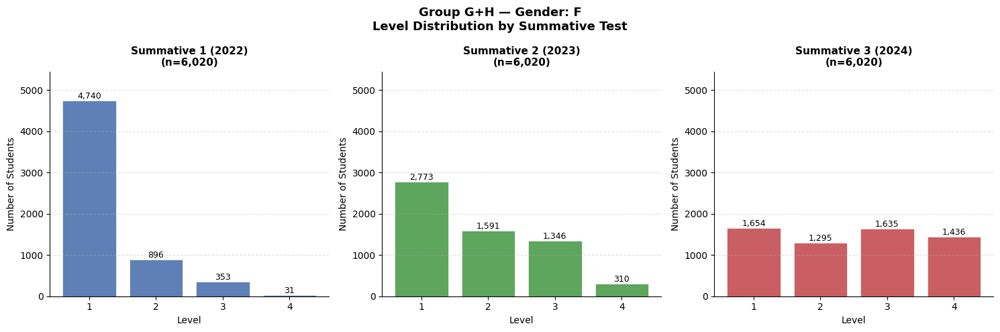

Saved: plots/group_gh_level_distribution_gender_F.png


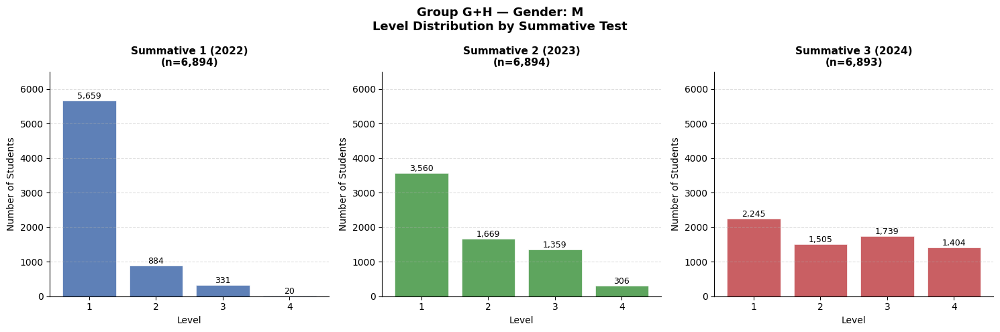

Saved: plots/group_gh_level_distribution_gender_M.png


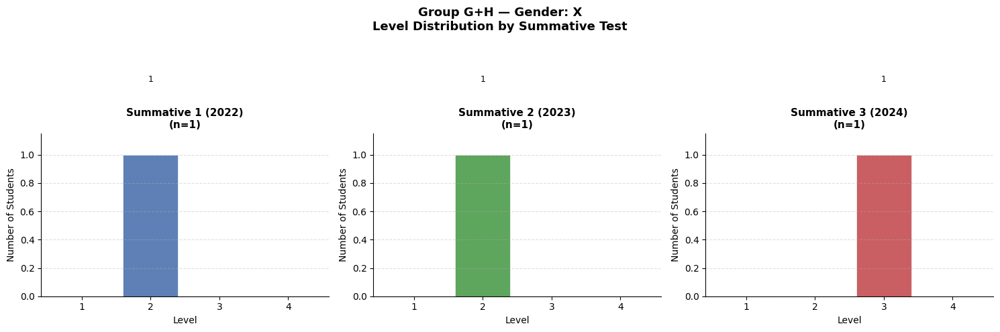

Saved: plots/group_gh_level_distribution_gender_X.png


In [29]:
# --- Level distribution per Gender: 3 subplots with consistent y-axis ---
for gender in gender_values:
    gender_data = scored_df[scored_df["StudentGenderCode"] == gender]
    if len(gender_data) == 0:
        continue

    # Find y-axis max across all 3 tests for this gender
    gender_y_max = 0
    for test_num in [1, 2, 3]:
        test_data    = gender_data[gender_data["TestNumber"] == test_num]["Level"].dropna()
        counts       = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        gender_y_max = max(gender_y_max, counts.max())
    gender_y_max = gender_y_max * 1.15

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f"{group_label} — Gender: {gender}\n"
                 f"Level Distribution by Summative Test",
                 fontsize=13, fontweight="bold")

    for ax, (test_num, color) in zip(axes, zip([1, 2, 3], test_colors)):
        test_data = gender_data[gender_data["TestNumber"] == test_num]["Level"].dropna()
        counts    = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        bars      = ax.bar(counts.index, counts.values, color=color,
                           edgecolor="white", linewidth=0.5, alpha=0.9)

        for bar, count in zip(bars, counts.values):
            if count > 0:
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                        f"{count:,}", ha="center", va="bottom", fontsize=9)

        ax.set_ylim(0, gender_y_max)
        ax.set_title(f"Summative {test_num} ({test_years[test_num]})\n(n={len(test_data):,})",
                     fontsize=11, fontweight="bold")
        ax.set_xlabel("Level", fontsize=10)
        ax.set_ylabel("Number of Students", fontsize=10)
        ax.set_xticks([1, 2, 3, 4])
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_gender = str(gender).replace(" ", "_")
    plt.savefig(f"plots/{group_short}_level_distribution_gender_{safe_gender}.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_level_distribution_gender_{safe_gender}.png")

# Broken out by "Unaccompanided Youth"

In [30]:
# --- Get Unaccompanied Youth from 2021-22 enrollment ---
youth_2022 = (
    enrollment_dfs["2021-22"][["SSID", "UnaccompaniedYouthIndicator"]]
    .dropna()
    .drop_duplicates(subset="SSID", keep="first")
)

# --- Merge into scatter_df and scored_df ---
scatter_df = scatter_df.merge(youth_2022, on="SSID", how="left")
scored_df  = scored_df.merge(youth_2022, on="SSID", how="left")

youth_values = sorted(scatter_df["UnaccompaniedYouthIndicator"].dropna().unique())
print(f"Unique Unaccompanied Youth values: {youth_values}")
for val in youth_values:
    n = scatter_df[scatter_df["UnaccompaniedYouthIndicator"] == val]["SSID"].nunique()
    print(f"  '{val}': {n:,} students")

Unique Unaccompanied Youth values: ['N', 'Y']
  'N': 1,432 students
  'Y': 86 students


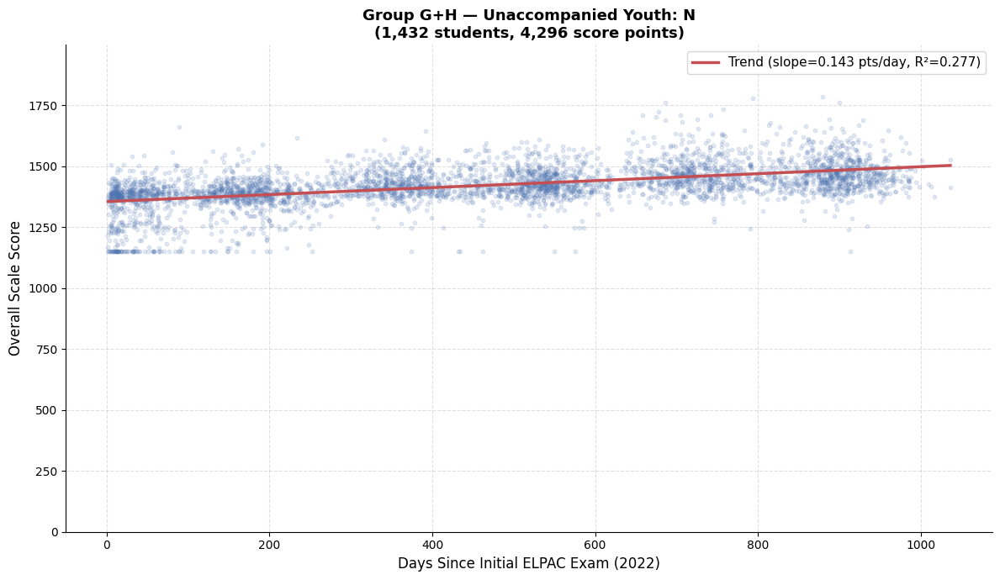

Saved: plots/group_gh_scatter_youth_N.png


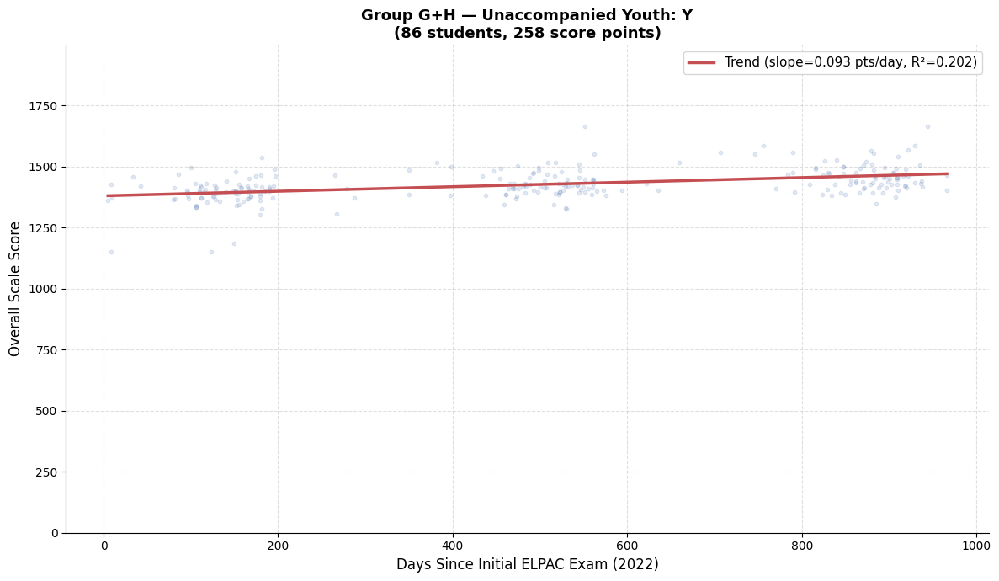

Saved: plots/group_gh_scatter_youth_Y.png


In [31]:
# --- Scatter plot per Unaccompanied Youth status ---
for youth in youth_values:
    youth_data = scatter_df[
        (scatter_df["UnaccompaniedYouthIndicator"] == youth) &
        (scatter_df["days"] > 0) &
        (scatter_df["score"] > 1000)
    ]
    x = youth_data["days"].values
    y = youth_data["score"].values

    if len(x) < 2:
        print(f"Skipping Unaccompanied Youth={youth} — insufficient data ({len(x)} points)")
        continue

    fig, ax = plt.subplots(figsize=(12, 7))
    ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    trend_x   = np.linspace(x.min(), x.max(), 300)
    r_squared = r_value ** 2
    ax.plot(trend_x, slope * trend_x + intercept, color="#C44E52", linewidth=2.5, zorder=3,
            label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

    ax.set_ylim(0, y_max)
    ax.set_xlabel("Days Since Initial ELPAC Exam (2022)", fontsize=12)
    ax.set_ylabel("Overall Scale Score", fontsize=12)
    ax.set_title(f"{group_label} — Unaccompanied Youth: {youth}\n"
                 f"({youth_data['SSID'].nunique():,} students, {len(x):,} score points)",
                 fontsize=13, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_youth = str(youth).replace(" ", "_")
    plt.savefig(f"plots/{group_short}_scatter_youth_{safe_youth}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_scatter_youth_{safe_youth}.png")

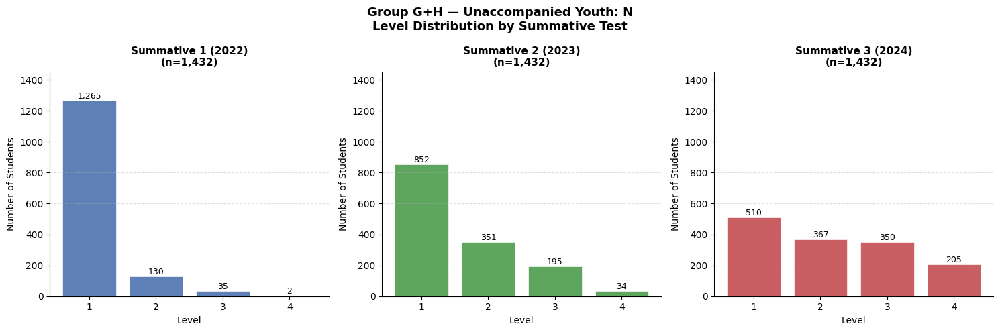

Saved: plots/group_gh_level_distribution_youth_N.png


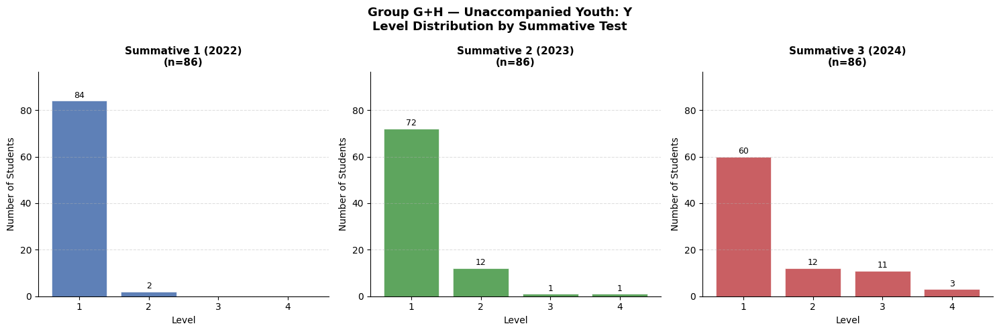

Saved: plots/group_gh_level_distribution_youth_Y.png


In [32]:
# --- Level distribution per Unaccompanied Youth: 3 subplots with consistent y-axis ---
for youth in youth_values:
    youth_data = scored_df[scored_df["UnaccompaniedYouthIndicator"] == youth]
    if len(youth_data) == 0:
        continue

    # Find y-axis max across all 3 tests
    youth_y_max = 0
    for test_num in [1, 2, 3]:
        test_data   = youth_data[youth_data["TestNumber"] == test_num]["Level"].dropna()
        counts      = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        youth_y_max = max(youth_y_max, counts.max())
    youth_y_max = youth_y_max * 1.15

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f"{group_label} — Unaccompanied Youth: {youth}\n"
                 f"Level Distribution by Summative Test",
                 fontsize=13, fontweight="bold")

    for ax, (test_num, color) in zip(axes, zip([1, 2, 3], test_colors)):
        test_data = youth_data[youth_data["TestNumber"] == test_num]["Level"].dropna()
        counts    = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        bars      = ax.bar(counts.index, counts.values, color=color,
                           edgecolor="white", linewidth=0.5, alpha=0.9)

        for bar, count in zip(bars, counts.values):
            if count > 0:
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                        f"{count:,}", ha="center", va="bottom", fontsize=9)

        ax.set_ylim(0, youth_y_max)
        ax.set_title(f"Summative {test_num} ({test_years[test_num]})\n(n={len(test_data):,})",
                     fontsize=11, fontweight="bold")
        ax.set_xlabel("Level", fontsize=10)
        ax.set_ylabel("Number of Students", fontsize=10)
        ax.set_xticks([1, 2, 3, 4])
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_youth = str(youth).replace(" ", "_")
    plt.savefig(f"plots/{group_short}_level_distribution_youth_{safe_youth}.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_level_distribution_youth_{safe_youth}.png")

# Break out by Birth Country

In [33]:
# --- Get Birth Country from 2021-22 enrollment ---
country_2022 = (
    enrollment_dfs["2021-22"][["SSID", "StudentBirthCountryCode"]]
    .dropna()
    .drop_duplicates(subset="SSID", keep="first")
)

# --- Merge into scatter_df and scored_df ---
scatter_df = scatter_df.merge(country_2022, on="SSID", how="left")
scored_df  = scored_df.merge(country_2022, on="SSID", how="left")

country_values = sorted(scatter_df["StudentBirthCountryCode"].dropna().unique())
print(f"Unique Birth Country values: {len(country_values)}")
for val in country_values:
    n = scatter_df[scatter_df["StudentBirthCountryCode"] == val]["SSID"].nunique()
    print(f"  '{val}': {n:,} students")

Unique Birth Country values: 117
  'AE': 2 students
  'AF': 2,111 students
  'AL': 2 students
  'AM': 477 students
  'AO': 2 students
  'AR': 20 students
  'AS': 2 students
  'AU': 1 students
  'AZ': 1 students
  'BD': 24 students
  'BE': 1 students
  'BO': 4 students
  'BQ': 1 students
  'BR': 90 students
  'BY': 30 students
  'BZ': 3 students
  'CA': 10 students
  'CD': 4 students
  'CF': 3 students
  'CG': 3 students
  'CH': 1 students
  'CI': 1 students
  'CL': 32 students
  'CM': 3 students
  'CN': 235 students
  'CO': 258 students
  'CR': 13 students
  'CU': 5 students
  'DE': 6 students
  'DJ': 2 students
  'DM': 2 students
  'DO': 13 students
  'DZ': 4 students
  'EC': 24 students
  'EE': 1 students
  'EG': 41 students
  'ER': 4 students
  'ES': 6 students
  'ET': 20 students
  'EU': 1 students
  'FI': 1 students
  'FJ': 11 students
  'FR': 7 students
  'GB': 1 students
  'GE': 2 students
  'GT': 2,540 students
  'HK': 13 students
  'HN': 971 students
  'HT': 102 students
  'ID

In [34]:
# --- Keep countries with >= 100 students, group rest as "Other" ---
min_students = 100

country_counts = (
    scatter_df[scatter_df["days"] > 0]
    .groupby("StudentBirthCountryCode")["SSID"]
    .nunique()
    .sort_values(ascending=False)
)

keep_countries = set(country_counts[country_counts >= min_students].index)
print(f"Countries with >= {min_students} students ({len(keep_countries)} total):")
for country, count in country_counts[country_counts >= min_students].items():
    print(f"  {country}: {count:,} students")
print(f"\nGrouped into 'Other': {len(country_counts[country_counts < min_students])} countries, "
      f"{country_counts[country_counts < min_students].sum():,} students")

# --- Map to country group ---
scatter_df["CountryGroup"] = scatter_df["StudentBirthCountryCode"].apply(
    lambda x: x if x in keep_countries else "Other"
)
scored_df["CountryGroup"] = scored_df["StudentBirthCountryCode"].apply(
    lambda x: x if x in keep_countries else "Other"
)

country_groups = sorted(keep_countries) + ["Other"]
print(f"\nGroups to plot: {country_groups}")

Countries with >= 100 students (14 total):
  GT: 2,540 students
  AF: 2,111 students
  SV: 1,867 students
  MX: 1,784 students
  HN: 971 students
  AM: 477 students
  RU: 427 students
  NI: 319 students
  CO: 258 students
  CN: 235 students
  UA: 203 students
  VN: 188 students
  UU: 166 students
  HT: 102 students

Grouped into 'Other': 103 countries, 1,270 students

Groups to plot: ['AF', 'AM', 'CN', 'CO', 'GT', 'HN', 'HT', 'MX', 'NI', 'RU', 'SV', 'UA', 'UU', 'VN', 'Other']


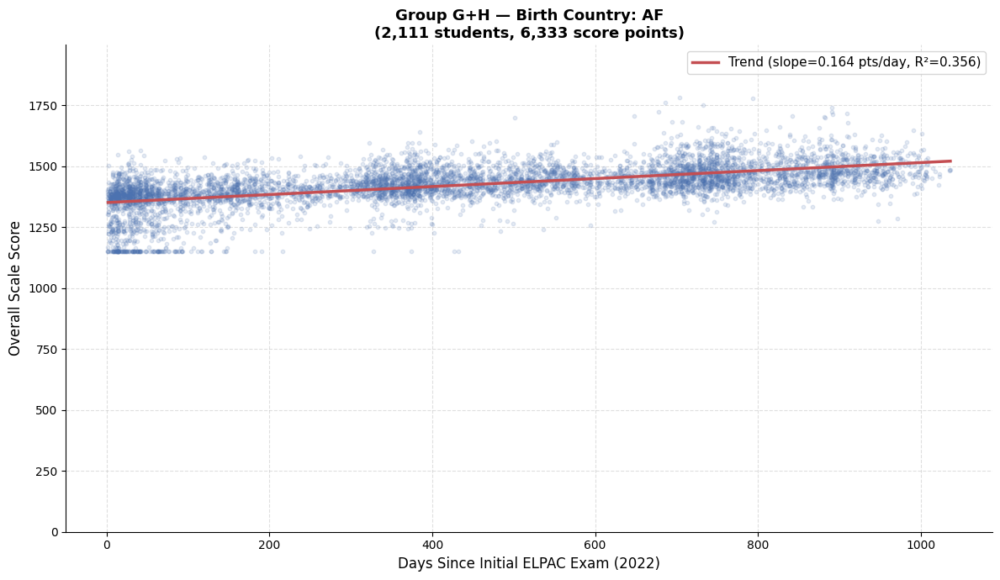

Saved: plots/group_gh_scatter_country_AF.png


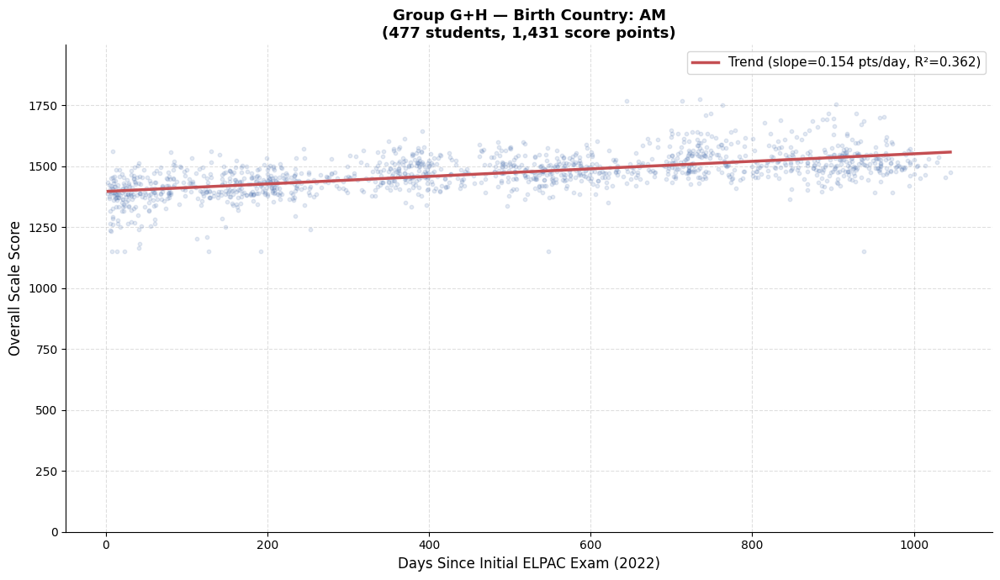

Saved: plots/group_gh_scatter_country_AM.png


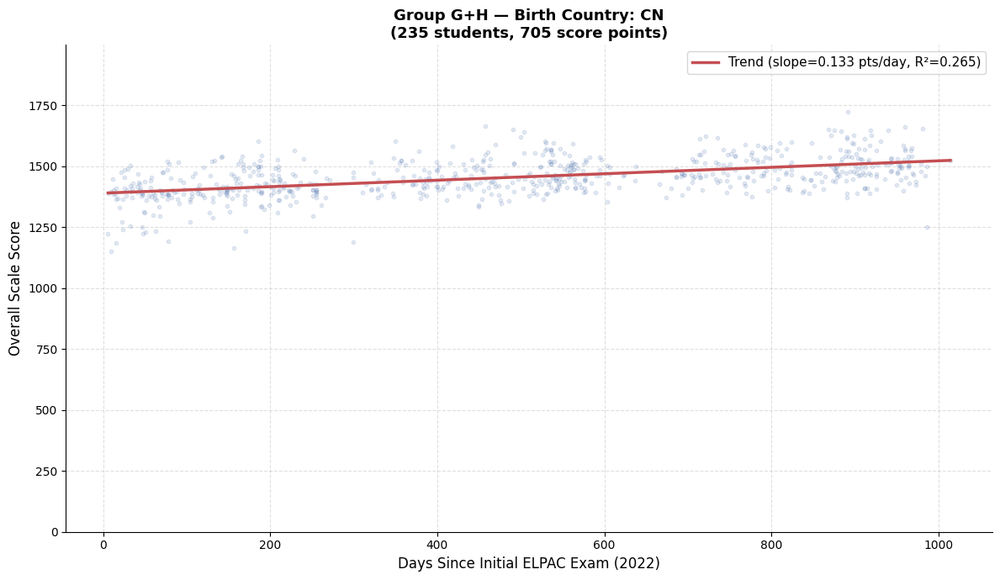

Saved: plots/group_gh_scatter_country_CN.png


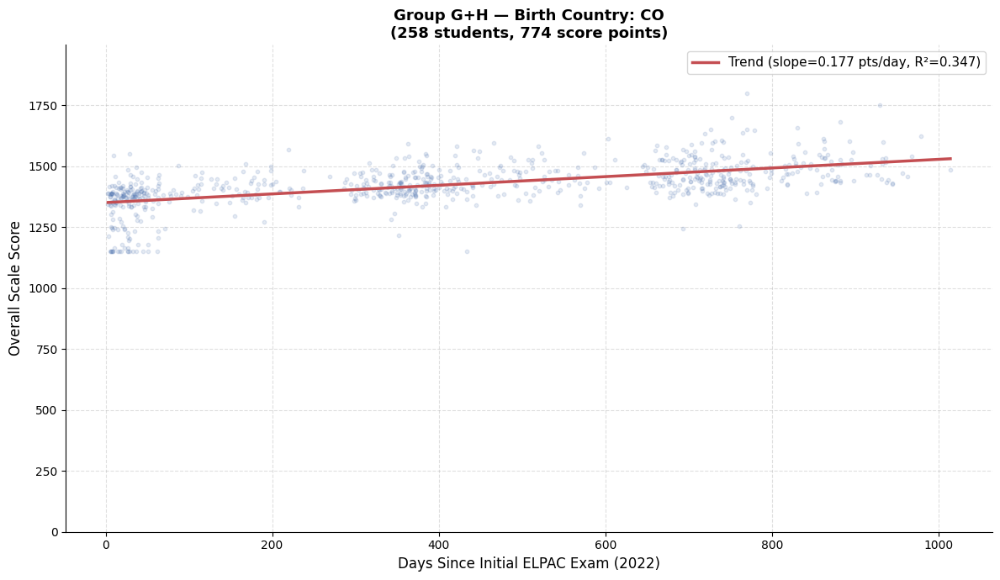

Saved: plots/group_gh_scatter_country_CO.png


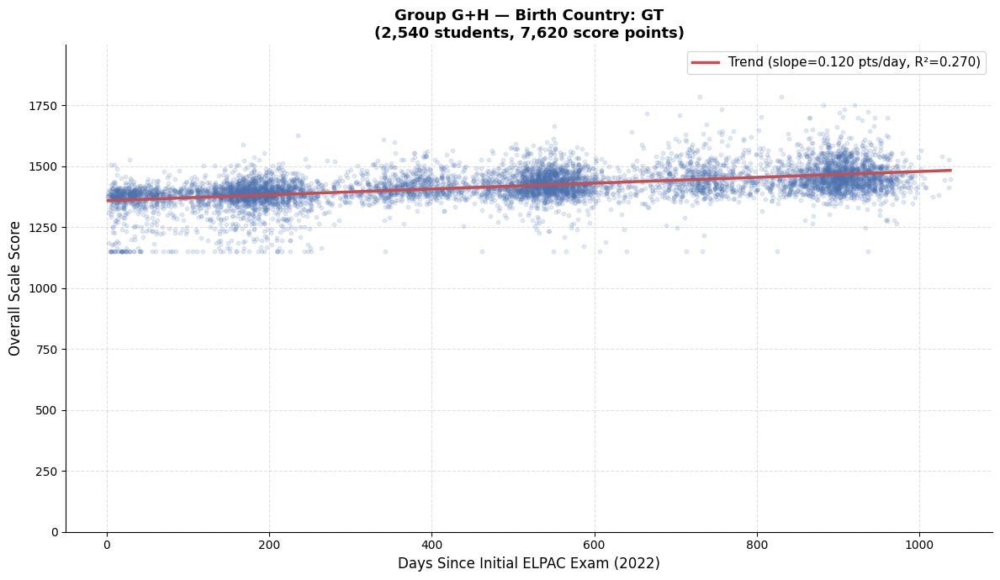

Saved: plots/group_gh_scatter_country_GT.png


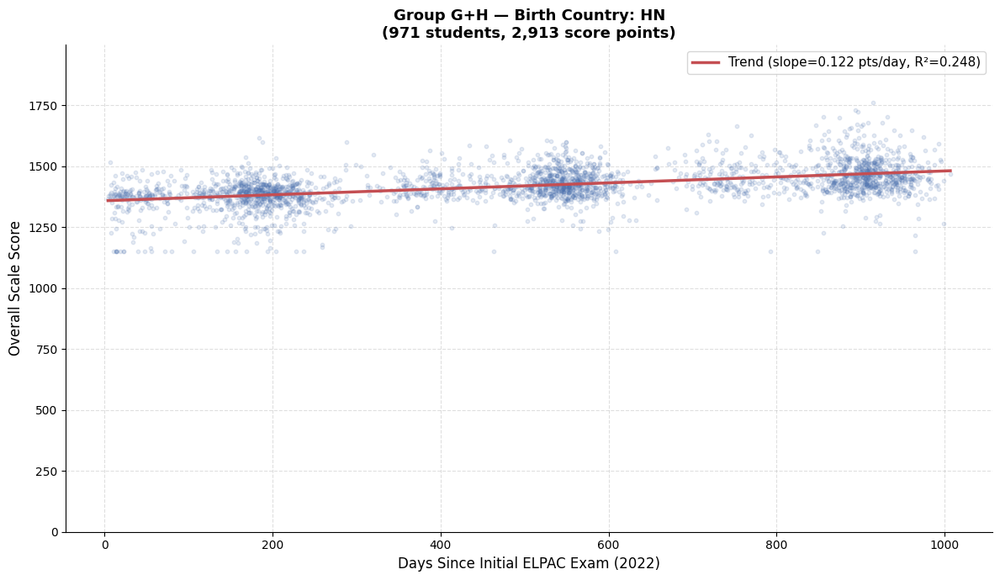

Saved: plots/group_gh_scatter_country_HN.png


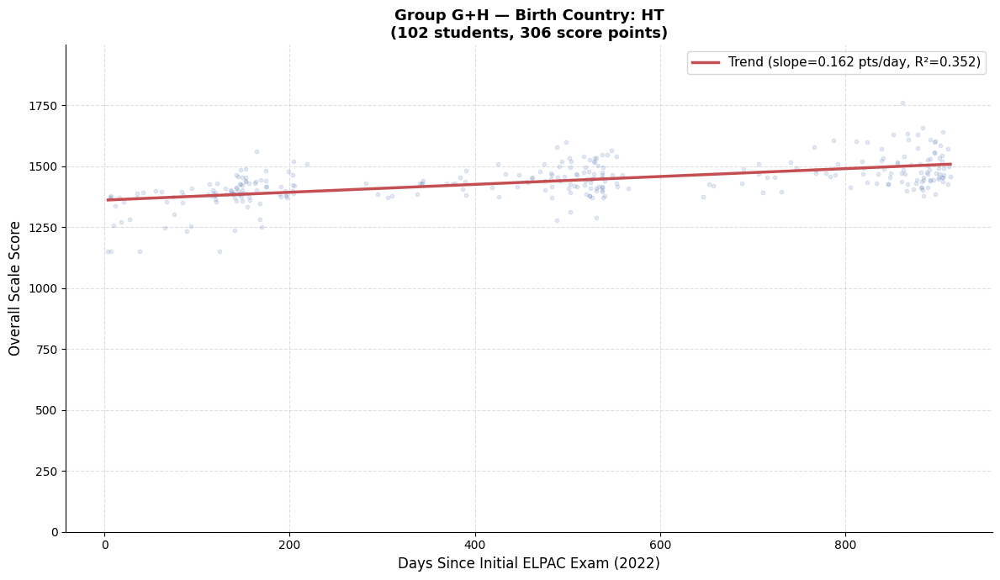

Saved: plots/group_gh_scatter_country_HT.png


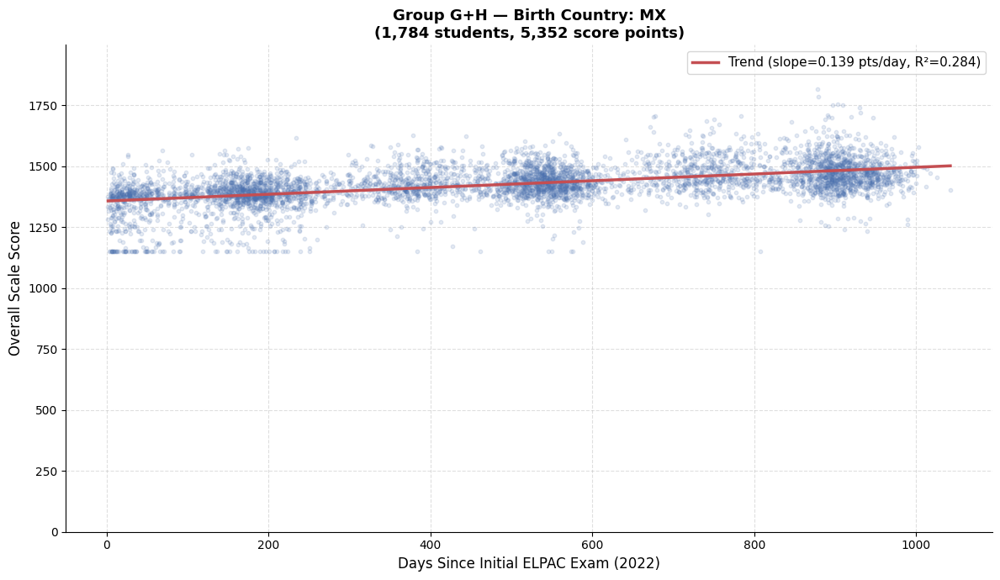

Saved: plots/group_gh_scatter_country_MX.png


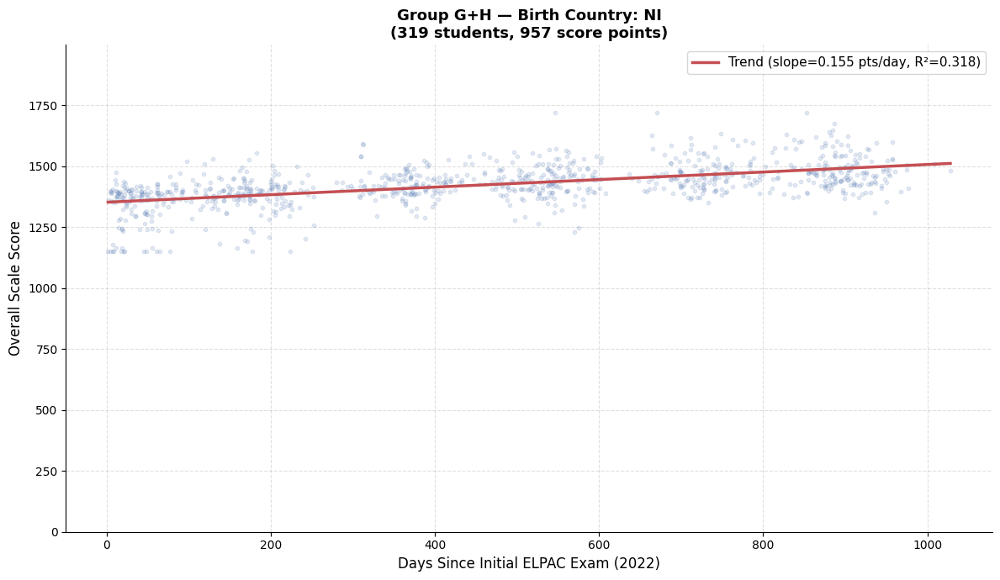

Saved: plots/group_gh_scatter_country_NI.png


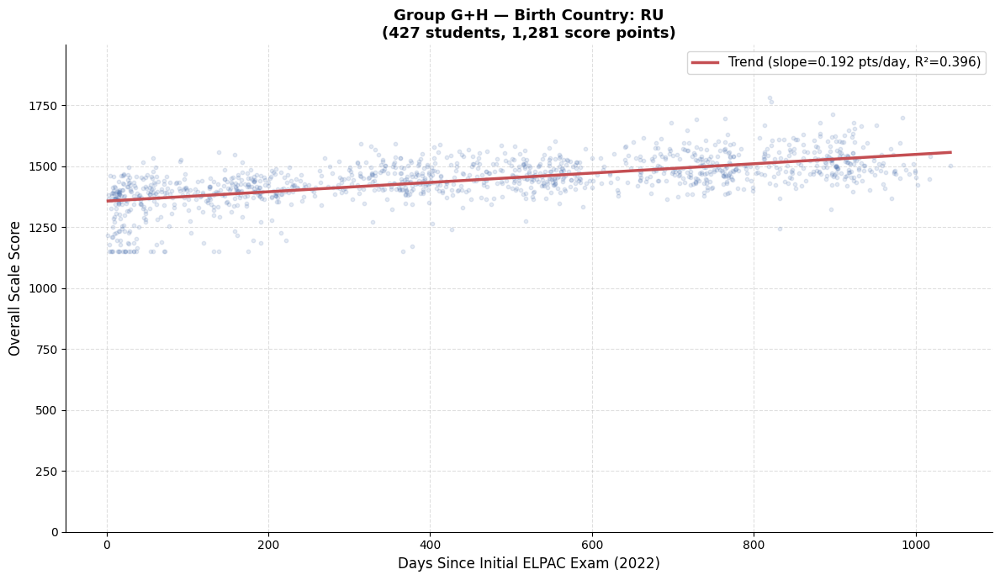

Saved: plots/group_gh_scatter_country_RU.png


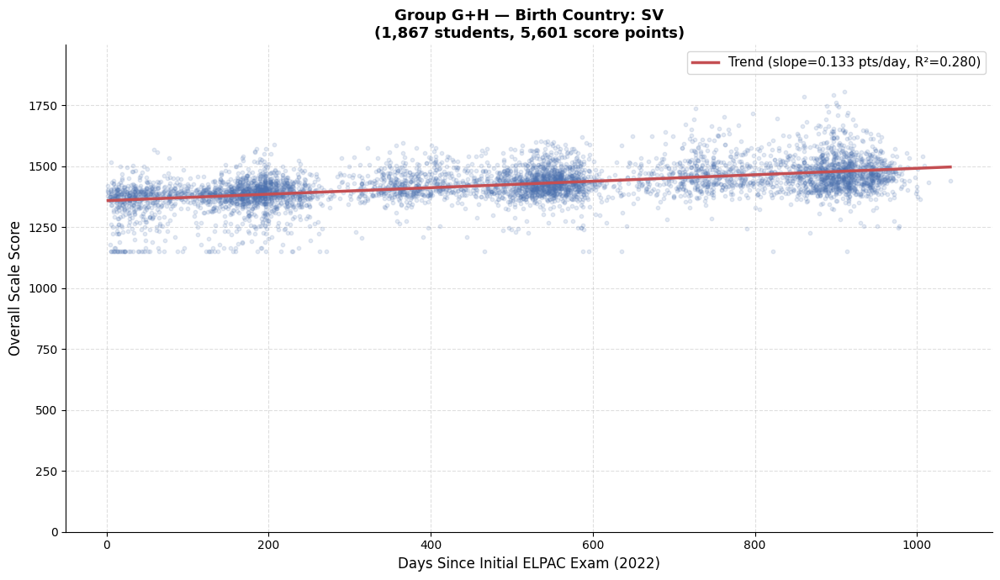

Saved: plots/group_gh_scatter_country_SV.png


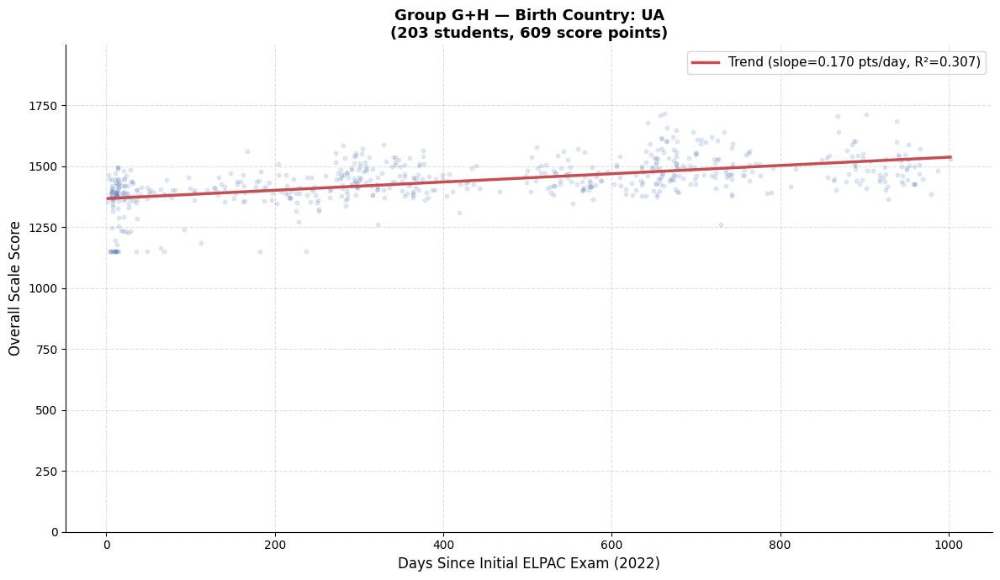

Saved: plots/group_gh_scatter_country_UA.png


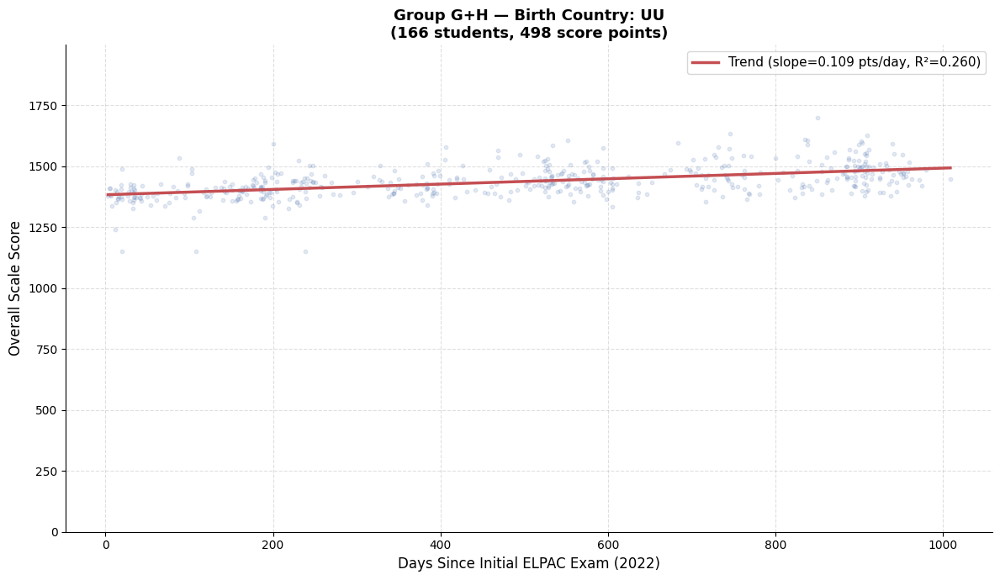

Saved: plots/group_gh_scatter_country_UU.png


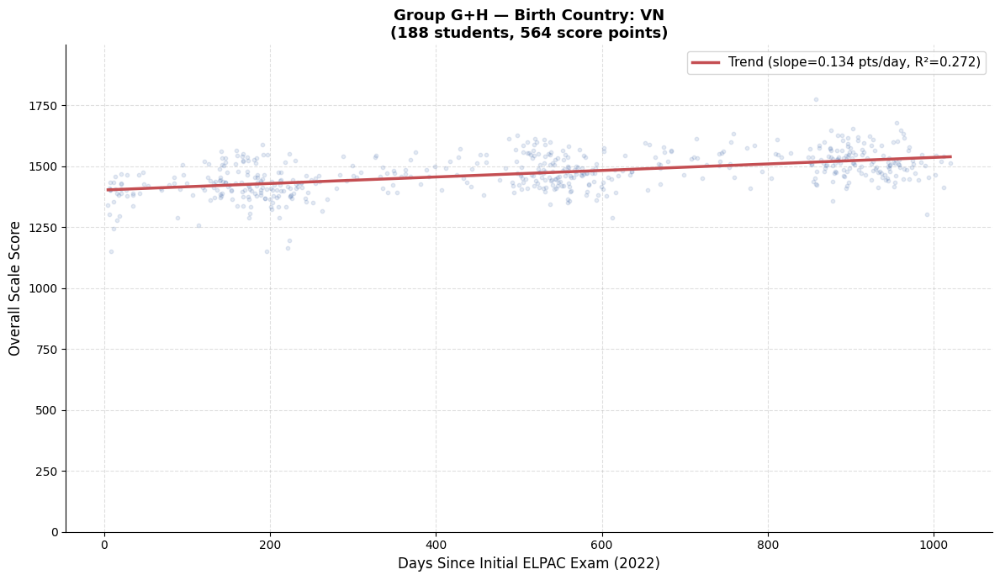

Saved: plots/group_gh_scatter_country_VN.png


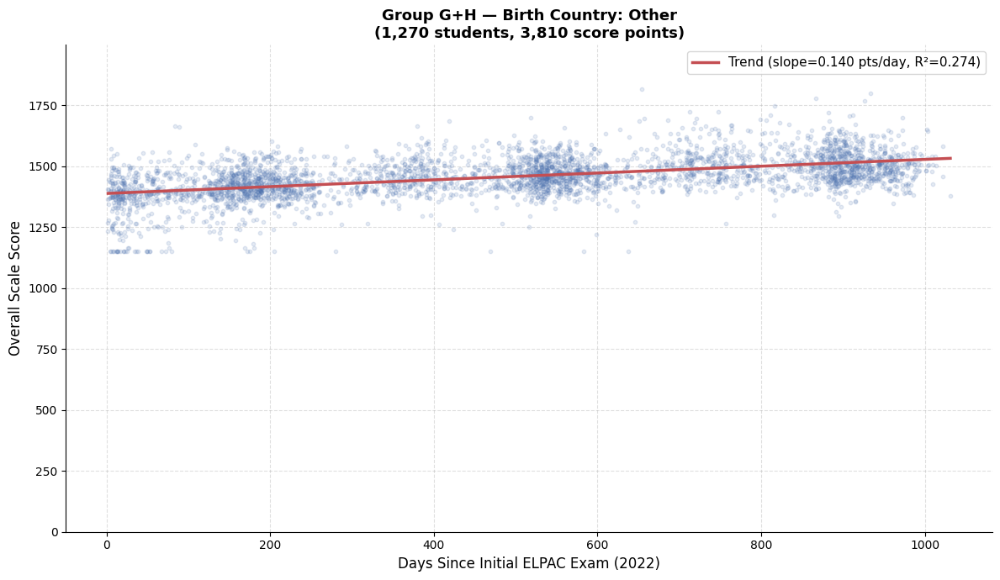

Saved: plots/group_gh_scatter_country_Other.png


In [35]:
# --- Scatter plot per country group ---
for country in country_groups:
    country_data = scatter_df[
        (scatter_df["CountryGroup"] == country) &
        (scatter_df["days"] > 0) &
        (scatter_df["score"] > 1000)
    ]
    x = country_data["days"].values
    y = country_data["score"].values

    if len(x) < 2:
        print(f"Skipping {country} — insufficient data ({len(x)} points)")
        continue

    fig, ax = plt.subplots(figsize=(12, 7))
    ax.scatter(x, y, color="#4C72B0", alpha=0.15, s=10, zorder=2)

    slope, intercept, r_value, _, _ = stats.linregress(x, y)
    trend_x   = np.linspace(x.min(), x.max(), 300)
    r_squared = r_value ** 2
    ax.plot(trend_x, slope * trend_x + intercept, color="#C44E52", linewidth=2.5, zorder=3,
            label=f"Trend (slope={slope:.3f} pts/day, R²={r_squared:.3f})")

    ax.set_ylim(0, y_max)
    ax.set_xlabel("Days Since Initial ELPAC Exam (2022)", fontsize=12)
    ax.set_ylabel("Overall Scale Score", fontsize=12)
    ax.set_title(f"{group_label} — Birth Country: {country}\n"
                 f"({country_data['SSID'].nunique():,} students, {len(x):,} score points)",
                 fontsize=13, fontweight="bold")
    ax.legend(fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_country = str(country).replace(" ", "_").replace("/", "_")
    plt.savefig(f"plots/{group_short}_scatter_country_{safe_country}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_scatter_country_{safe_country}.png")

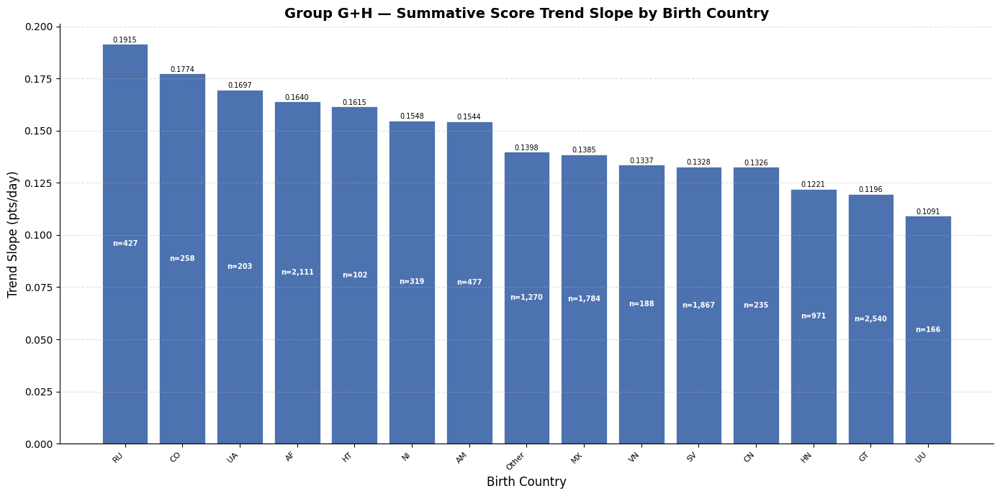

Saved: plots/group_gh_slope_by_country.png


In [39]:
# --- Slope bar chart by birth country group ---
country_slopes = {}
country_counts = {}

for country in country_groups:
    country_data = scatter_df[
        (scatter_df["CountryGroup"] == country) &
        (scatter_df["days"] > 0) &
        (scatter_df["score"] > 1000)
    ]
    x = country_data["days"].values
    y = country_data["score"].values

    if len(x) < 2:
        continue

    slope, _, _, _, _ = stats.linregress(x, y)
    country_slopes[country] = slope
    country_counts[country] = country_data["SSID"].nunique()

# Sort by slope descending
sorted_countries = sorted(country_slopes.items(), key=lambda kv: -kv[1])
country_names = [c[0] for c in sorted_countries]
slopes        = [c[1] for c in sorted_countries]
counts        = [country_counts[c] for c in country_names]

# --- Bar chart ---
fig, ax = plt.subplots(figsize=(max(14, len(country_names) * 0.8), 7))

colors = ["#4C72B0" if s >= 0 else "#C44E52" for s in slopes]
bars = ax.bar(range(len(country_names)), slopes, color=colors, edgecolor="white", linewidth=0.5)

# Slope label above/below each bar
for bar, slope in zip(bars, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (0.0002 if slope >= 0 else -0.0002),
        f"{slope:.4f}",
        ha="center", va="bottom" if slope >= 0 else "top", fontsize=7
    )

# Student count inside each bar
for bar, count, slope in zip(bars, counts, slopes):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() / 2,
        f"n={count:,}",
        ha="center", va="center",
        fontsize=7, color="white", fontweight="bold"
    )

ax.set_xticks(range(len(country_names)))
ax.set_xticklabels(country_names, rotation=45, ha="right", fontsize=8)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("Birth Country", fontsize=12)
ax.set_ylabel("Trend Slope (pts/day)", fontsize=12)
ax.set_title(f"{group_label} — Summative Score Trend Slope by Birth Country", fontsize=14, fontweight="bold")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(f"plots/{group_short}_slope_by_country.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: plots/{group_short}_slope_by_country.png")

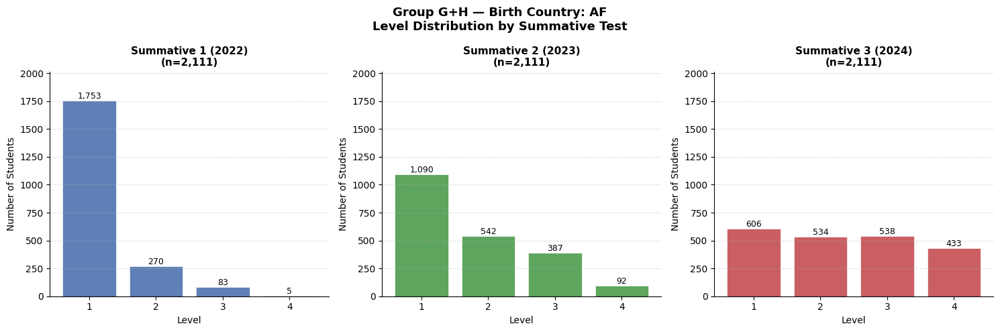

Saved: plots/group_gh_level_distribution_country_AF.png


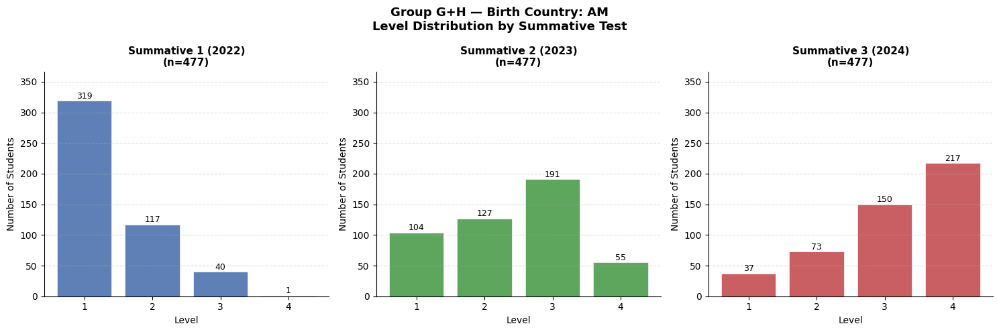

Saved: plots/group_gh_level_distribution_country_AM.png


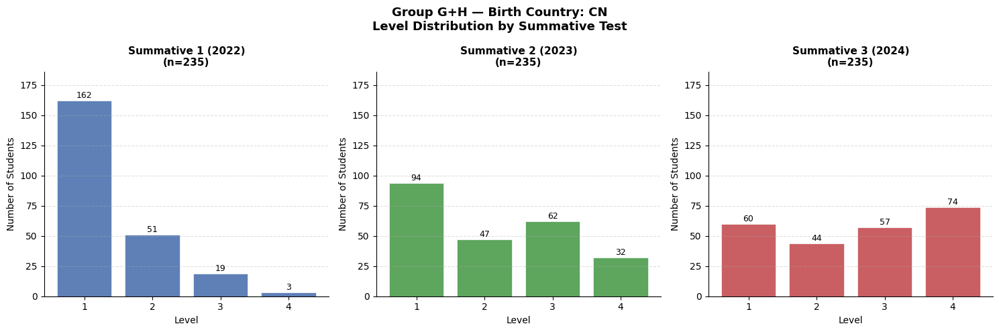

Saved: plots/group_gh_level_distribution_country_CN.png


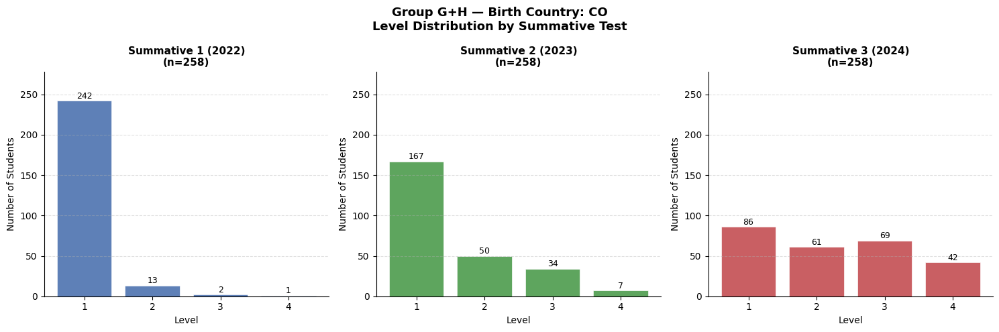

Saved: plots/group_gh_level_distribution_country_CO.png


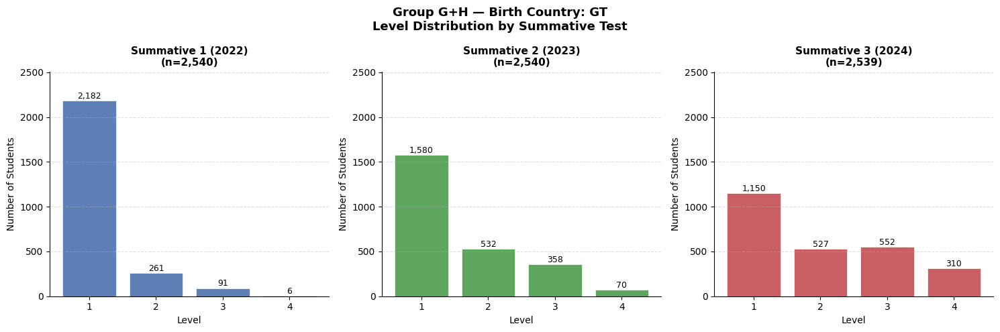

Saved: plots/group_gh_level_distribution_country_GT.png


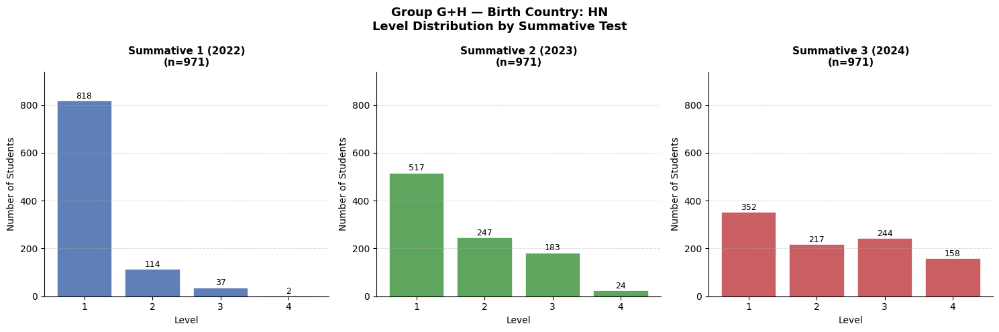

Saved: plots/group_gh_level_distribution_country_HN.png


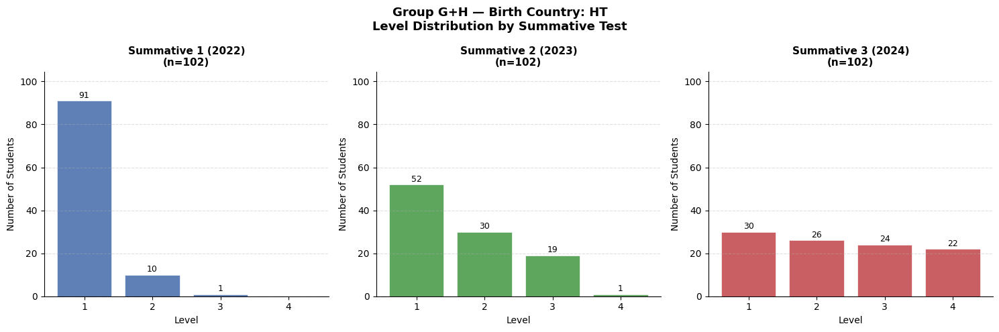

Saved: plots/group_gh_level_distribution_country_HT.png


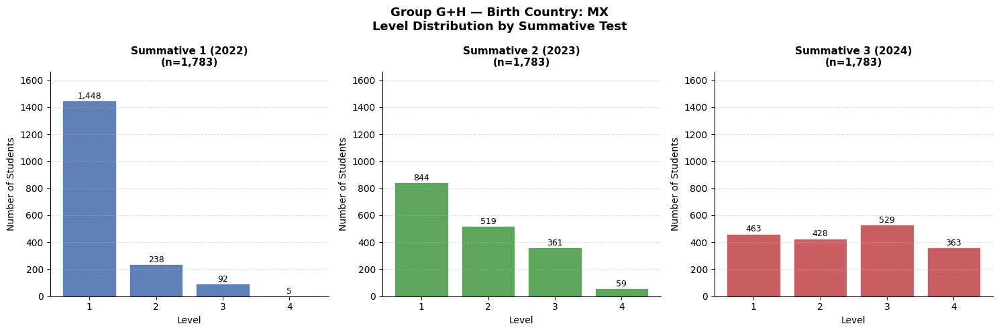

Saved: plots/group_gh_level_distribution_country_MX.png


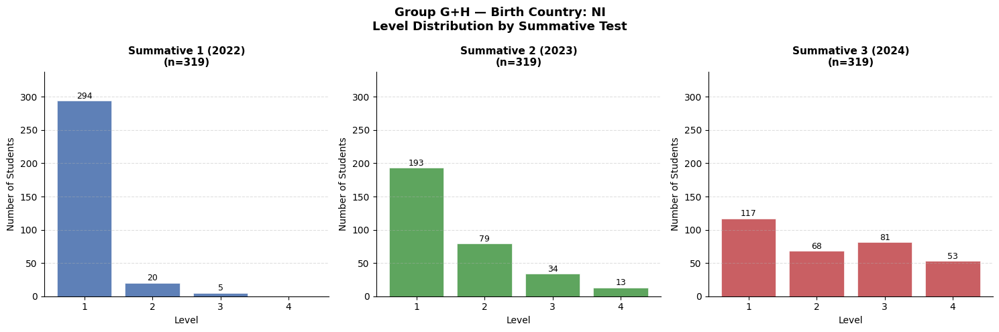

Saved: plots/group_gh_level_distribution_country_NI.png


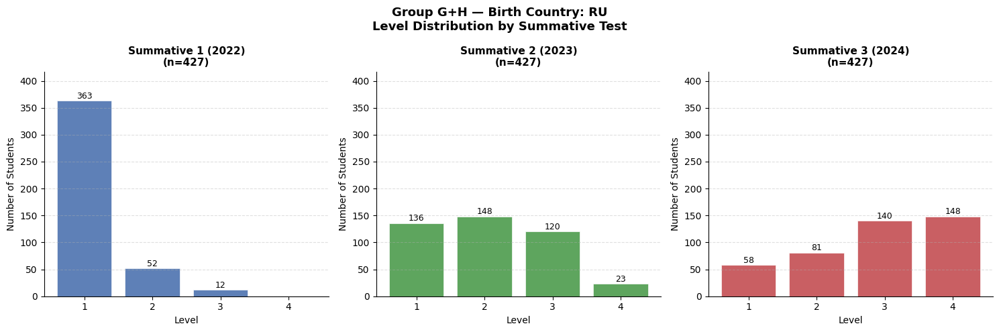

Saved: plots/group_gh_level_distribution_country_RU.png


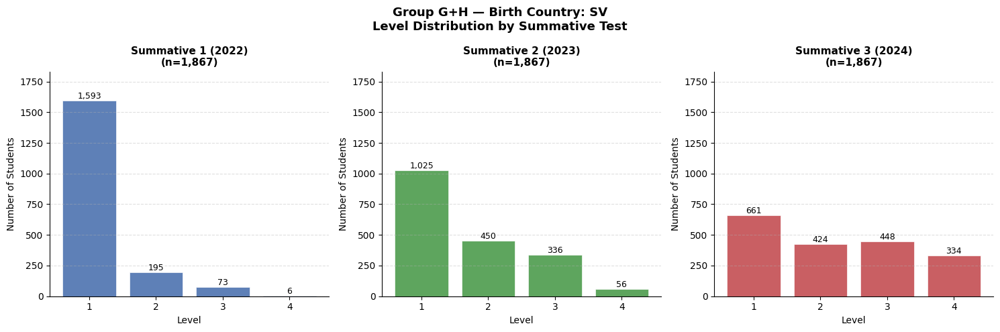

Saved: plots/group_gh_level_distribution_country_SV.png


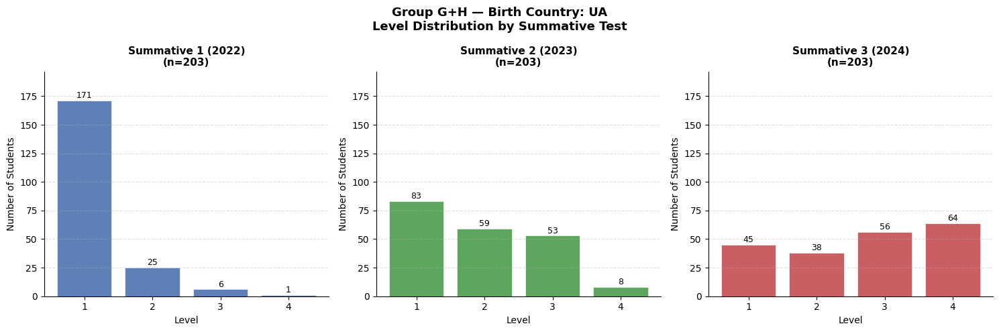

Saved: plots/group_gh_level_distribution_country_UA.png


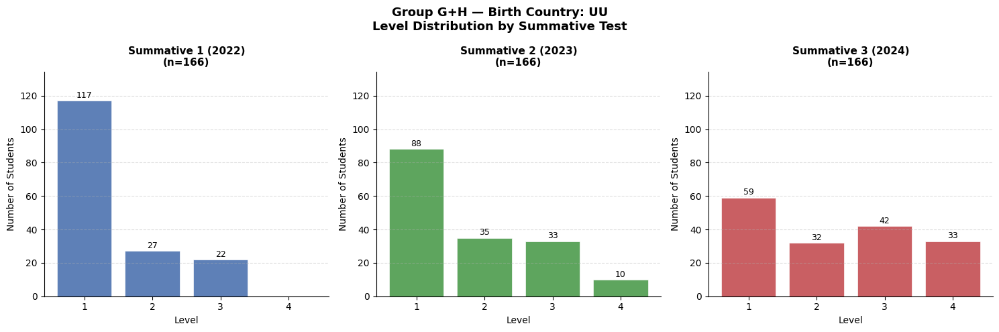

Saved: plots/group_gh_level_distribution_country_UU.png


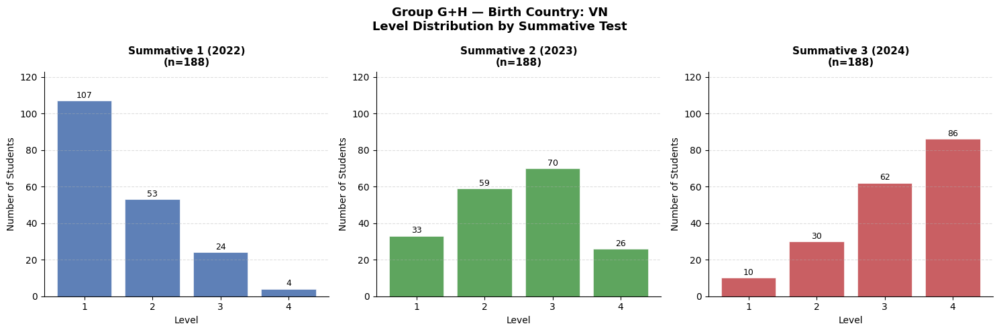

Saved: plots/group_gh_level_distribution_country_VN.png


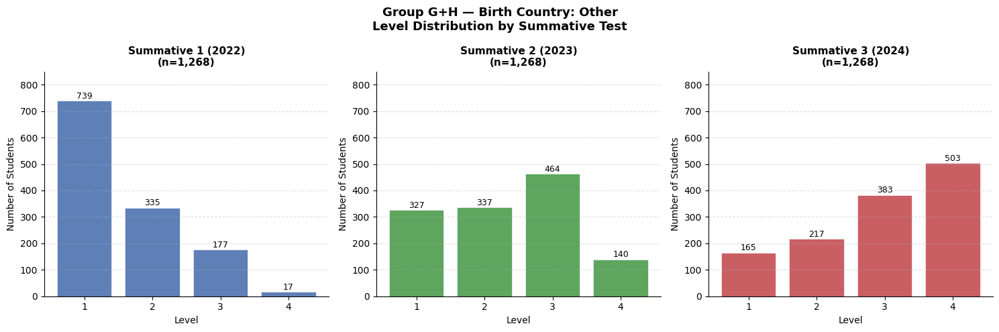

Saved: plots/group_gh_level_distribution_country_Other.png


In [36]:
# --- Level distribution per country group: 3 subplots with consistent y-axis ---
for country in country_groups:
    country_data = scored_df[scored_df["CountryGroup"] == country]
    if len(country_data) == 0:
        continue

    country_y_max = 0
    for test_num in [1, 2, 3]:
        test_data     = country_data[country_data["TestNumber"] == test_num]["Level"].dropna()
        counts        = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        country_y_max = max(country_y_max, counts.max())
    country_y_max = country_y_max * 1.15

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f"{group_label} — Birth Country: {country}\n"
                 f"Level Distribution by Summative Test",
                 fontsize=13, fontweight="bold")

    for ax, (test_num, color) in zip(axes, zip([1, 2, 3], test_colors)):
        test_data = country_data[country_data["TestNumber"] == test_num]["Level"].dropna()
        counts    = test_data.value_counts().reindex([1, 2, 3, 4], fill_value=0)
        bars      = ax.bar(counts.index, counts.values, color=color,
                           edgecolor="white", linewidth=0.5, alpha=0.9)

        for bar, count in zip(bars, counts.values):
            if count > 0:
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                        f"{count:,}", ha="center", va="bottom", fontsize=9)

        ax.set_ylim(0, country_y_max)
        ax.set_title(f"Summative {test_num} ({test_years[test_num]})\n(n={len(test_data):,})",
                     fontsize=11, fontweight="bold")
        ax.set_xlabel("Level", fontsize=10)
        ax.set_ylabel("Number of Students", fontsize=10)
        ax.set_xticks([1, 2, 3, 4])
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    safe_country = str(country).replace(" ", "_").replace("/", "_")
    plt.savefig(f"plots/{group_short}_level_distribution_country_{safe_country}.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: plots/{group_short}_level_distribution_country_{safe_country}.png")

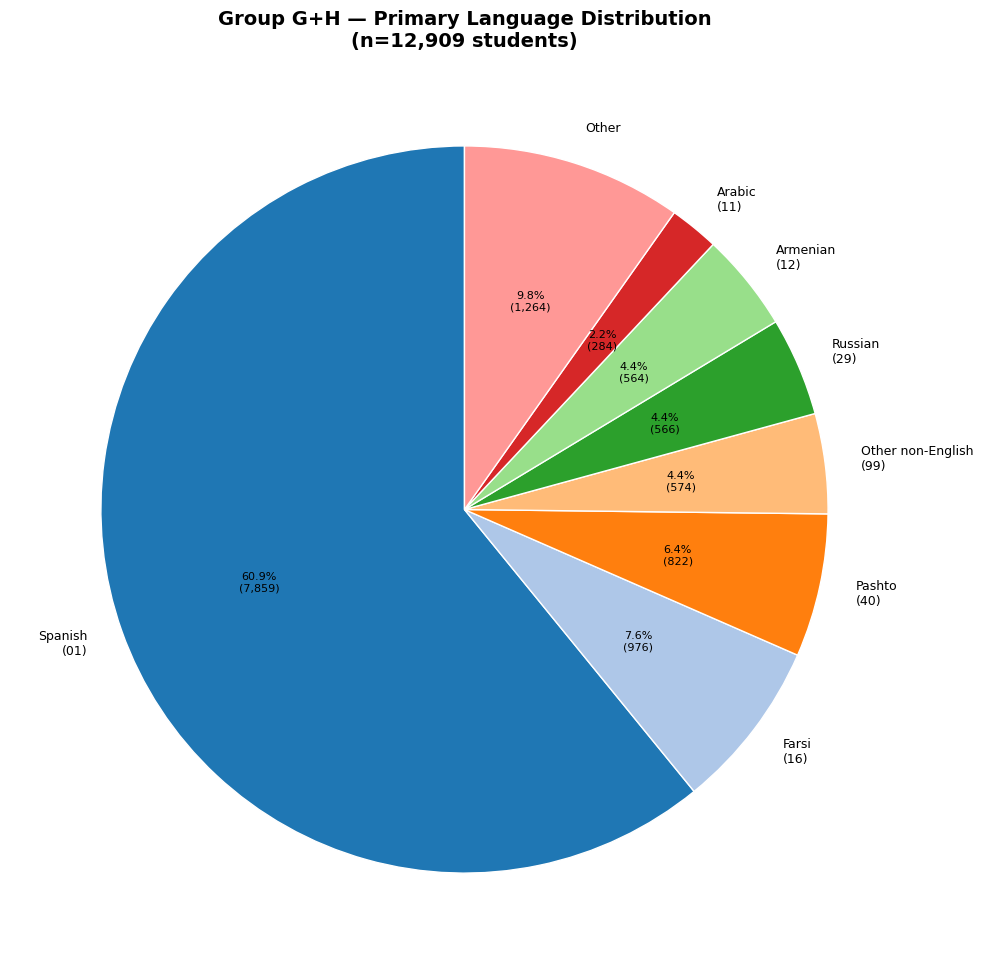

Saved: plots/group_gh_language_pie.png


In [42]:
# --- Pie chart of PrimaryLanguageCode ---
# Get language counts (one record per student)
lang_counts = (
    scatter_df.drop_duplicates(subset="SSID")["PrimaryLanguageCode"]
    .astype(str).str.strip()
    .value_counts()
)

# Group small languages into "Other"
min_pct = 0.02  # languages below 2% get grouped into "Other"
total = lang_counts.sum()
keep = lang_counts[lang_counts / total >= min_pct]
other_sum = lang_counts[lang_counts / total < min_pct].sum()

if other_sum > 0:
    keep["Other"] = other_sum

# Map codes to names (reuse the CALPADS language map)
language_code_map = {
    "00": "English", "01": "Spanish", "02": "Vietnamese", "03": "Cantonese",
    "04": "Korean", "05": "Filipino", "06": "Portuguese", "07": "Mandarin",
    "08": "Japanese", "09": "Khmer", "11": "Arabic", "12": "Armenian",
    "16": "Farsi", "23": "Hmong", "28": "Punjabi", "29": "Russian",
    "40": "Pashto", "60": "Somali", "73": "Haitian Creole", "99": "Other non-English",
    "UU": "Unknown", "Other": "Other",
}

labels = [f"{language_code_map.get(code, code)}\n({code})" if code != "Other" else "Other"
          for code in keep.index]

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 10))

colors_pie = plt.cm.tab20.colors
wedges, texts, autotexts = ax.pie(
    keep.values,
    labels=labels,
    autopct=lambda pct: f"{pct:.1f}%\n({int(round(pct/100*total)):,})",
    startangle=90,
    colors=colors_pie[:len(keep)],
    wedgeprops={"edgecolor": "white", "linewidth": 1},
    textprops={"fontsize": 9},
)

for autotext in autotexts:
    autotext.set_fontsize(8)
    autotext.set_color("black")

ax.set_title(f"{group_label} — Primary Language Distribution\n(n={total:,} students)",
             fontsize=14, fontweight="bold")

plt.tight_layout()
plt.savefig(f"plots/{group_short}_language_pie.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: plots/{group_short}_language_pie.png")